# Employee Attrition Prediction — End-to-End Machine Learning Project
**Dataset:** IBM HR Analytics Employee Attrition & Performance (`WA_Fn-UseC_-HR-Employee-Attrition.csv`)  
**Task:** Binary classification (will an employee leave: `Attrition = Yes`?)

### Contents
1. Problem statement
2. Proposed solution
3. Setup & configuration
4. Data audit & deep cleaning
5. Train / test split (done *before* any learning – leakage control)
6. Exploratory data analysis & visualisation
7. Feature engineering (with the math)
8. Preprocessing, scaling & feature reduction
9. Model benchmarking (cross-validation, imbalance strategies, ablation)
10. Hyper-parameter tuning & nested cross-validation
11. Under-fitting / over-fitting diagnostics
12. Data-leakage audit
13. Probability calibration & decision threshold
14. Final, one-time evaluation on the held-out test set
15. Model interpretation
16. Business impact (illustrative)
17. Recommendations & solution summary

---
# 1. Problem Statement

## Business context
Employee attrition is expensive. Replacing a single employee commonly costs a large fraction of their annual salary once recruiting, onboarding, lost productivity and knowledge loss are counted. HR teams usually learn about a resignation **after** it happens – when it is too late to act.

## The problem
> *Can we identify, in advance, which current employees are at high risk of leaving, and understand **why**, so that HR can run targeted retention actions before the resignation happens?*

## Machine-learning formulation
| Item | Definition |
|---|---|
| **Unit of analysis** | One employee (1,470 rows) |
| **Target** | `Attrition` → `Yes` = 1 (left), `No` = 0 (stayed) |
| **Problem type** | Supervised binary classification, **imbalanced** (≈16 % positives) |
| **Inputs** | Demographics, job/role, compensation, tenure, satisfaction surveys, work pattern (overtime, travel) |
| **Output** | A calibrated probability of leaving + a risk tier + the main drivers |

## Success criteria
* **Ranking quality:** ROC-AUC and PR-AUC (Average Precision). Accuracy is *not* used – predicting "nobody leaves" already gives ~84 %.
* **Operational quality:** recall (leavers caught) vs. precision (wasted interventions) at a chosen threshold.
* **Generalisation:** small gap between training and cross-validated scores; test score consistent with CV; score clearly above label-shuffled baseline.
* **Trustworthiness:** zero data leakage, calibrated probabilities, interpretable drivers.

## Assumptions & caveats
* The IBM dataset is a **fictional, synthetic** dataset created by IBM data scientists – it is ideal for learning, but real-world signal is usually weaker/noisier.
* It is a **single snapshot** (no timestamps), so we cannot do a time-based split. We note where this limits real-world deployment (Section 12).

---
# 2. Proposed Solution

**Approach:** build a *leakage-proof*, fully reproducible scikit-learn pipeline.

```
 raw CSV ──► audit & clean ──► stratified train/test split  (test set locked away)
                                   │
                                   ▼  (everything below is FIT ON TRAIN FOLDS ONLY)
   EDA ► Feature engineering (ratios, peer-relative pay, satisfaction composites)
       ► Encoding + Yeo-Johnson power transform + standardisation
       ► Feature reduction (correlation filter → VIF pruning → L1 selection)
       ► Imbalance handling (class weights; SMOTE compared)
       ► Model benchmark (Logistic Regression, SVM, RF, ExtraTrees, HistGB, XGBoost, LightGBM)
       ► Randomised hyper-parameter search + nested CV
       ► Over/under-fit diagnostics, leakage audit, permutation test
       ► Probability calibration + cost-aware threshold
                                   │
                                   ▼
          one-shot evaluation on the untouched test set ► SHAP / importance ► recommendations
```

**Key design principles**
1. **Split first, learn later** – the test set is touched exactly once, at the very end.
2. **Everything that learns from data lives inside a `Pipeline`** (feature statistics, scalers, selectors, resamplers, calibrators) so cross-validation re-fits them per fold.
3. **Compare, don't assume** – every choice (feature engineering, feature reduction, imbalance strategy, algorithm) is justified by cross-validated evidence.
4. **Business-aware evaluation** – metrics and thresholds reflect the cost of missing a leaver vs. a wasted retention conversation.

---
# 3. Python libraries and data loading

In [1]:
# ---- Core libraries -------------------------------------------------------
import os, re, time, warnings, joblib
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import loguniform, randint, uniform
from IPython.display import display, Markdown

# ---- scikit-learn ---------------------------------------------------------
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.model_selection import (train_test_split, StratifiedKFold, RepeatedStratifiedKFold,
                                     cross_validate, cross_val_predict, cross_val_score,
                                     RandomizedSearchCV, learning_curve, validation_curve,
                                     permutation_test_score)
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import PowerTransformer, StandardScaler, OneHotEncoder
from sklearn.feature_selection import SelectFromModel, SelectKBest, f_classif, mutual_info_classif
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, HistGradientBoostingClassifier
from sklearn.dummy import DummyClassifier
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.inspection import permutation_importance
from sklearn.metrics import (roc_auc_score, average_precision_score, roc_curve, precision_recall_curve,
                             confusion_matrix, precision_score, recall_score, f1_score, fbeta_score,
                             balanced_accuracy_score, matthews_corrcoef, brier_score_loss, log_loss,
                             ConfusionMatrixDisplay)
from statsmodels.stats.multitest import multipletests

# ---- Boosting libraries & imbalanced-learn --------------------------------
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

# ---- Global configuration -------------------------------------------------

RANDOM_STATE = 42
QUICK_RUN = False      # True = fewer CV repeats / search iterations (≈4x faster, for debugging)
np.random.seed(RANDOM_STATE)

PALETTE = {0: "#3b82c4", 1: "#e4572e"}      # blue = stayed, orange-red = left

print("pandas", pd.__version__, "| numpy", np.__version__)

import sklearn, xgboost, lightgbm

print("scikit-learn", sklearn.__version__, "| xgboost", xgboost.__version__, "| lightgbm", lightgbm.__version__)

pandas 2.2.3 | numpy 2.1.3
scikit-learn 1.6.1 | xgboost 3.2.0 | lightgbm 4.6.0


In [2]:
# ---- Locate the data file -------------------------------------------------

DATA_PATH = "WA_Fn-UseC_-HR-Employee-Attrition.csv"

raw = pd.read_csv(DATA_PATH)

print("Shape:", raw.shape)

raw.head()

Shape: (1470, 35)


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


---
# 4. Data Audit & Deep Cleaning

A systematic audit **before** modelling. Every action is recorded in a cleaning log so the process is auditable.

Checks performed:
1. Structure, dtypes, cardinality
2. Missing values & duplicates
3. String hygiene (whitespace/case/rare labels)
4. Constant / identifier columns (carry no signal – or worse, create spurious signal)
5. Range validation of ordinal scales
6. Logical-consistency rules (e.g. you cannot have been at the company longer than you have worked in total)
7. Outliers (Tukey IQR fences and robust MAD z-scores)

In [3]:
# 4.1 Structural overview ----------------------------------------------------
audit = pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "n_unique": raw.nunique(),
    "n_missing": raw.isna().sum(),
    "pct_missing": raw.isna().mean() * 100,
    "min": raw.min(numeric_only=True),
    "max": raw.max(numeric_only=True),
    "example": raw.iloc[0],
})
display(audit)

print(f"\nMissing cells: {int(raw.isna().sum().sum())}")
print(f"Fully duplicated rows: {raw.duplicated().sum()}")
print(f"Duplicated EmployeeNumber: {raw['EmployeeNumber'].duplicated().sum()}")

,dtype,n_unique,n_missing,pct_missing,min,max,example
Age,int64,43,0,0.0,18.0,60.0,41
Attrition,object,2,0,0.0,NaN,NaN,Yes
BusinessTravel,object,3,0,0.0,NaN,NaN,Travel_Rarely
DailyRate,int64,886,0,0.0,102.0,1499.0,1102
Department,object,3,0,0.0,NaN,NaN,Sales
DistanceFromHome,int64,29,0,0.0,1.0,29.0,1
Education,int64,5,0,0.0,1.0,5.0,2
EducationField,object,6,0,0.0,NaN,NaN,Life Sciences
EmployeeCount,int64,1,0,0.0,1.0,1.0,1
EmployeeNumber,int64,1470,0,0.0,1.0,2068.0,1



Missing cells: 0
Fully duplicated rows: 0
Duplicated EmployeeNumber: 0


In [4]:
# 4.2 String hygiene: leading/trailing spaces, inconsistent case, rare labels --------
cleaning_log = []
def log(action, detail):
    cleaning_log.append({"step": len(cleaning_log) + 1, "action": action, "detail": detail})

df = raw.copy()
str_cols = [c for c in df.columns if not pd.api.types.is_numeric_dtype(df[c])]
changed = 0
for c in str_cols:
    cleaned = df[c].astype(str).str.strip()
    changed += int((cleaned != df[c].astype(str)).sum())
    df[c] = cleaned
log("Whitespace stripping", f"{len(str_cols)} text columns checked, {changed} cells modified")

for c in str_cols:
    vc = df[c].value_counts()
    print(f"{c:15s} -> {dict(vc)}")
rare = {c: [k for k, v in df[c].value_counts().items() if v < 20] for c in str_cols}
print("\nLabels with < 20 rows:", {k: v for k, v in rare.items() if v})

Attrition       -> {'No': np.int64(1233), 'Yes': np.int64(237)}
BusinessTravel  -> {'Travel_Rarely': np.int64(1043), 'Travel_Frequently': np.int64(277), 'Non-Travel': np.int64(150)}
Department      -> {'Research & Development': np.int64(961), 'Sales': np.int64(446), 'Human Resources': np.int64(63)}
EducationField  -> {'Life Sciences': np.int64(606), 'Medical': np.int64(464), 'Marketing': np.int64(159), 'Technical Degree': np.int64(132), 'Other': np.int64(82), 'Human Resources': np.int64(27)}
Gender          -> {'Male': np.int64(882), 'Female': np.int64(588)}
JobRole         -> {'Sales Executive': np.int64(326), 'Research Scientist': np.int64(292), 'Laboratory Technician': np.int64(259), 'Manufacturing Director': np.int64(145), 'Healthcare Representative': np.int64(131), 'Manager': np.int64(102), 'Sales Representative': np.int64(83), 'Research Director': np.int64(80), 'Human Resources': np.int64(52)}
MaritalStatus   -> {'Married': np.int64(673), 'Single': np.int64(470), 'Divorced': np.i

In [5]:
# 4.3 Constant & identifier columns ---------------------------------------------
constant_cols = [c for c in df.columns if df[c].nunique() == 1]
id_cols = [c for c in df.columns if df[c].nunique() == len(df) and c != "Attrition"]
print("Constant columns  :", constant_cols)
print("Unique-ID columns :", id_cols)

# Does the ID carry (spurious) information about the target? If row order/IDs correlated with
# leaving, using them would be leakage-like. Check anyway:
y_tmp = (df["Attrition"] == "Yes").astype(int)
rho, p = stats.spearmanr(df["EmployeeNumber"], y_tmp)
print(f"Spearman(EmployeeNumber, Attrition) = {rho:.3f} (p = {p:.3f})  -> IDs are arbitrary labels; dropped regardless.")

df = df.drop(columns=constant_cols + id_cols)
log("Dropped constant columns", f"{constant_cols} – zero variance, no information")
log("Dropped identifier", f"{id_cols} – unique per row, would let models memorise individuals")

Constant columns  : ['EmployeeCount', 'Over18', 'StandardHours']
Unique-ID columns : ['EmployeeNumber']
Spearman(EmployeeNumber, Attrition) = -0.010 (p = 0.691)  -> IDs are arbitrary labels; dropped regardless.


In [6]:
# 4.4 Range validation of ordinal scales -----------------------------------------
expected_ranges = {
    "Education": (1, 5), "EnvironmentSatisfaction": (1, 4), "JobInvolvement": (1, 4), "JobLevel": (1, 5),
    "JobSatisfaction": (1, 4), "PerformanceRating": (1, 4), "RelationshipSatisfaction": (1, 4),
    "StockOptionLevel": (0, 3), "WorkLifeBalance": (1, 4),
}
rows = []
for c, (lo, hi) in expected_ranges.items():
    bad = int(((df[c] < lo) | (df[c] > hi)).sum())
    rows.append({"column": c, "expected": f"{lo}-{hi}", "observed": f"{df[c].min()}-{df[c].max()}", "violations": bad})
display(pd.DataFrame(rows))
log("Ordinal range validation", f"{sum(r['violations'] for r in rows)} out-of-range values in {len(rows)} ordinal columns")

,column,expected,observed,violations
0,Education,1-5,1-5,0
1,EnvironmentSatisfaction,1-4,1-4,0
2,JobInvolvement,1-4,1-4,0
3,JobLevel,1-5,1-5,0
4,JobSatisfaction,1-4,1-4,0
5,PerformanceRating,1-4,3-4,0
6,RelationshipSatisfaction,1-4,1-4,0
7,StockOptionLevel,0-3,0-3,0
8,WorkLifeBalance,1-4,1-4,0


In [7]:
# 4.5 Logical-consistency rules ------------------------------------------------------
rules = {
    "YearsAtCompany <= TotalWorkingYears":        df["YearsAtCompany"] > df["TotalWorkingYears"],
    "YearsInCurrentRole <= YearsAtCompany":       df["YearsInCurrentRole"] > df["YearsAtCompany"],
    "YearsSinceLastPromotion <= YearsAtCompany":  df["YearsSinceLastPromotion"] > df["YearsAtCompany"],
    "YearsWithCurrManager <= YearsAtCompany":     df["YearsWithCurrManager"] > df["YearsAtCompany"],
    "Age - TotalWorkingYears >= 14 (child-labour sanity)": (df["Age"] - df["TotalWorkingYears"]) < 14,
    "Age >= 18":                                  df["Age"] < 18,
    "MonthlyIncome > 0":                          df["MonthlyIncome"] <= 0,
    "DistanceFromHome >= 0":                      df["DistanceFromHome"] < 0,
    "NumCompaniesWorked >= 0":                    df["NumCompaniesWorked"] < 0,
}
consistency = pd.DataFrame({"rule": list(rules), "violations": [int(v.sum()) for v in rules.values()]})
display(consistency)
log("Logical-consistency rules", f"{len(rules)} rules tested, {int(consistency.violations.sum())} violations")

# Pay-rate columns: do they relate to MonthlyIncome at all? (Hourly*8*22 should ~ monthly)
print("\nCorrelation between pay-related columns (should be strongly related if they were real):")
display(df[["MonthlyIncome", "DailyRate", "HourlyRate", "MonthlyRate"]].corr().round(3))

,rule,violations
0,YearsAtCompany <= TotalWorkingYears,0
1,YearsInCurrentRole <= YearsAtCompany,0
2,YearsSinceLastPromotion <= YearsAtCompany,0
3,YearsWithCurrManager <= YearsAtCompany,0
4,Age - TotalWorkingYears >= 14 (child-labour sa...,0
5,Age >= 18,0
6,MonthlyIncome > 0,0
7,DistanceFromHome >= 0,0
8,NumCompaniesWorked >= 0,0



Correlation between pay-related columns (should be strongly related if they were real):


,MonthlyIncome,DailyRate,HourlyRate,MonthlyRate
MonthlyIncome,1.000,0.008,-0.016,0.035
DailyRate,0.008,1.000,0.023,-0.032
HourlyRate,-0.016,0.023,1.000,-0.015
MonthlyRate,0.035,-0.032,-0.015,1.000


**Observation.** The three "rate" columns (`DailyRate`, `HourlyRate`, `MonthlyRate`) are essentially *uncorrelated* with `MonthlyIncome` (|r| ≈ 0.0) – in a real payroll they would be near-deterministic transformations of each other. They look like random noise columns. We **do not** drop them by intuition; instead we let the evidence (statistical tests, mutual information, cross-validated feature selection) decide in later sections.

,feature,skew,kurtosis,IQR_outliers,pct_IQR_outliers,robust_z>3.5
0,YearsSinceLastPromotion,1.984290,3.612673,107,7.278912,183
1,YearsAtCompany,1.764529,3.935509,104,7.074830,66
2,MonthlyIncome,1.369817,1.005233,114,7.755102,118
3,TotalWorkingYears,1.117172,0.918270,63,4.285714,46
4,DistanceFromHome,0.958118,-0.224833,0,0.000000,0
5,YearsInCurrentRole,0.917363,0.477421,21,1.428571,0
6,YearsWithCurrManager,0.833451,0.171058,14,0.952381,0
7,PercentSalaryHike,0.821128,-0.300598,0,0.000000,18
8,Age,0.413286,-0.404145,0,0.000000,0
9,MonthlyRate,0.018578,-1.214956,0,0.000000,0


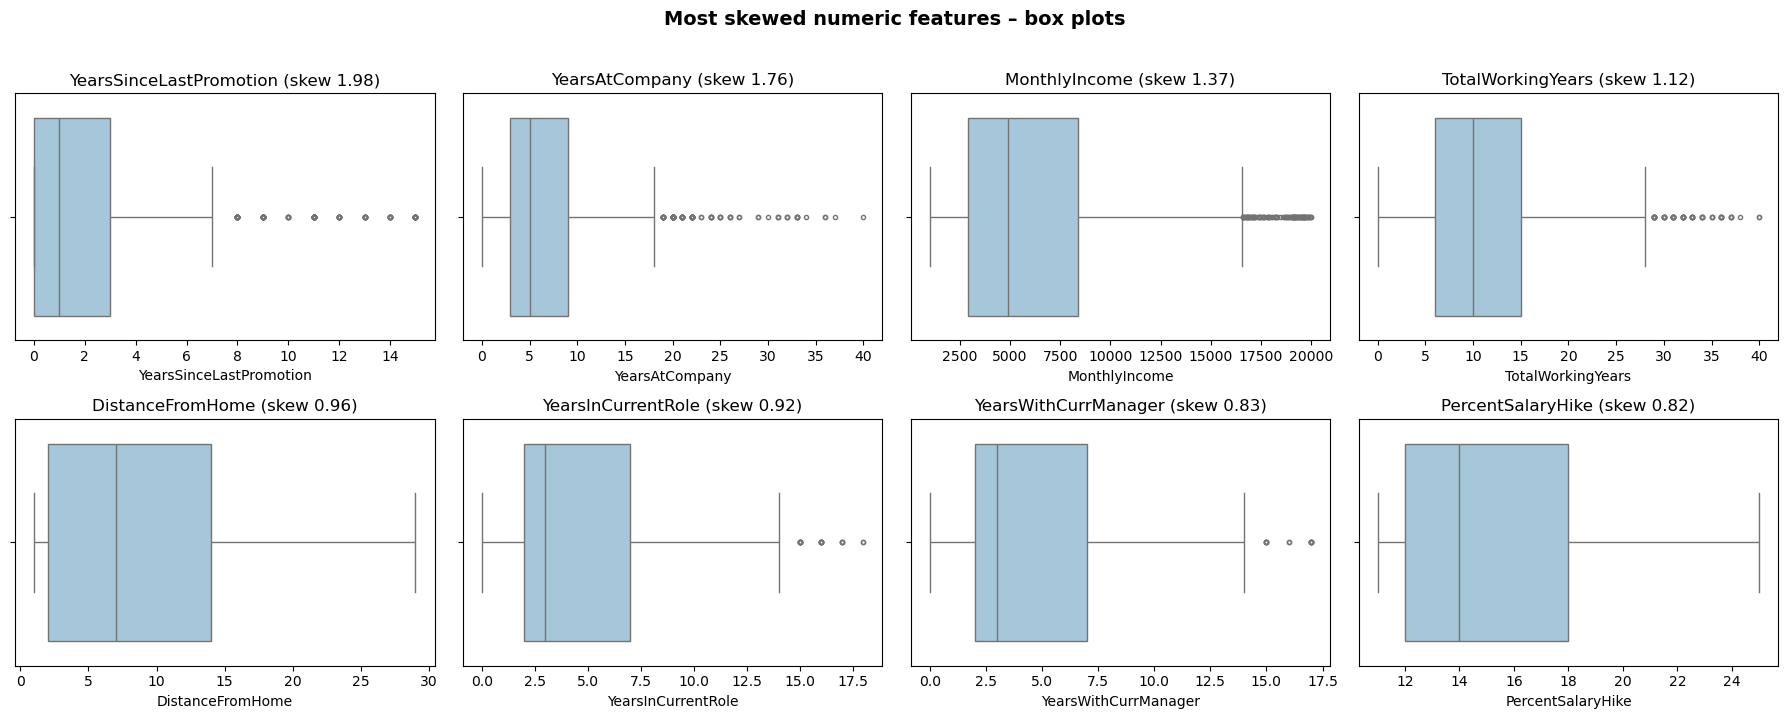

In [8]:
# 4.6 Outlier analysis -----------------------------------------------------------------
num_cols_all = [c for c in df.select_dtypes(include="number").columns if c != "Attrition" and df[c].nunique() > 10]

def outlier_table(frame, cols):
    out = []
    for c in cols:
        x = frame[c]
        q1, q3 = x.quantile([.25, .75]); iqr = q3 - q1
        lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        med = x.median(); mad = stats.median_abs_deviation(x, scale="normal")
        robust_z = (x - med) / mad if mad > 0 else pd.Series(0, index=x.index)
        out.append({"feature": c, "skew": x.skew(), "kurtosis": x.kurt(),
                    "IQR_outliers": int(((x < lo) | (x > hi)).sum()),
                    "pct_IQR_outliers": 100 * ((x < lo) | (x > hi)).mean(),
                    "robust_z>3.5": int((robust_z.abs() > 3.5).sum())})
    return pd.DataFrame(out).sort_values("skew", ascending=False).reset_index(drop=True)

out_tbl = outlier_table(df, num_cols_all)
display(out_tbl)

fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for ax, c in zip(axes.ravel(), out_tbl.head(8)["feature"]):
    sns.boxplot(x=df[c], ax=ax, color="#9ecae1", fliersize=3)
    ax.set_title(f"{c} (skew {df[c].skew():.2f})")
plt.suptitle("Most skewed numeric features – box plots", y=1.02, fontsize=14, fontweight="bold")
plt.tight_layout(); plt.show()

**Outlier decision.** The flagged points (high `MonthlyIncome`, long tenures, etc.) are **genuine, plausible employees** (senior managers, long-servers) – not data-entry errors. Deleting or capping them would erase real structure and bias the model against senior staff. Instead we:
* keep them,
* tame the skew mathematically with a **Yeo-Johnson power transform** (Section 8), and
* rely on tree models, which are invariant to monotone transforms and robust to outliers.

In [9]:
# 4.7 Final cleaned frame: target encoding + typed column groups ------------------------------
df["Attrition"] = df["Attrition"].map({"No": 0, "Yes": 1}).astype(int)

nominal_cols = ["BusinessTravel", "Department", "EducationField", "Gender", "JobRole", "MaritalStatus", "OverTime"]
ordinal_cols = list(expected_ranges.keys())
continuous_cols = [c for c in df.columns if c not in nominal_cols + ordinal_cols + ["Attrition"]]

print("Nominal    :", nominal_cols)
print("Ordinal    :", ordinal_cols)
print("Continuous :", continuous_cols)
log("Target encoding", "Attrition: No -> 0, Yes -> 1")
log("Outliers", "Retained (genuine values); handled by Yeo-Johnson transform / tree models")

print(f"\nCleaned shape: {df.shape}  |  attrition rate = {df.Attrition.mean():.3%}")
display(pd.DataFrame(cleaning_log))

Nominal    : ['BusinessTravel', 'Department', 'EducationField', 'Gender', 'JobRole', 'MaritalStatus', 'OverTime']
Ordinal    : ['Education', 'EnvironmentSatisfaction', 'JobInvolvement', 'JobLevel', 'JobSatisfaction', 'PerformanceRating', 'RelationshipSatisfaction', 'StockOptionLevel', 'WorkLifeBalance']
Continuous : ['Age', 'DailyRate', 'DistanceFromHome', 'HourlyRate', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'PercentSalaryHike', 'TotalWorkingYears', 'TrainingTimesLastYear', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager']

Cleaned shape: (1470, 31)  |  attrition rate = 16.122%


,step,action,detail
0,1,Whitespace stripping,"9 text columns checked, 0 cells modified"
1,2,Dropped constant columns,"['EmployeeCount', 'Over18', 'StandardHours'] –..."
2,3,Dropped identifier,"['EmployeeNumber'] – unique per row, would let..."
3,4,Ordinal range validation,0 out-of-range values in 9 ordinal columns
4,5,Logical-consistency rules,"9 rules tested, 0 violations"
5,6,Target encoding,"Attrition: No -> 0, Yes -> 1"
6,7,Outliers,Retained (genuine values); handled by Yeo-John...


---
# 5. Train / Test Split — *before* any learning

To keep the test set honest we split **now**, stratified on the target so both parts keep the same ≈16 % attrition rate. From here on:

* **EDA, statistical tests, feature statistics, scalers, selectors and models only ever see the training set.**
* The 20 % test set stays locked until Section 14.

> Why EDA on train only? Exploration drives decisions (which features to engineer/keep). If those decisions were informed by test rows, the test score would be optimistically biased — a subtle but very real form of leakage.

In [10]:
X = df.drop(columns="Attrition")
y = df["Attrition"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)

print(f"Train: {X_train.shape}  attrition = {y_train.mean():.3%}  ({y_train.sum()} leavers)")
print(f"Test : {X_test.shape}  attrition = {y_test.mean():.3%}  ({y_test.sum()} leavers)")

# Leakage sanity checks on the split itself
assert set(X_train.index).isdisjoint(X_test.index), "Index overlap between train and test!"
row_hash = lambda d: pd.util.hash_pandas_object(d, index=False)
overlap = np.intersect1d(row_hash(X_train).values, row_hash(X_test).values)
print(f"Exact duplicate feature-rows shared by train and test: {len(overlap)}")

train_df = X_train.assign(Attrition=y_train)       # EDA works on this frame only
SPW = (y_train == 0).sum() / (y_train == 1).sum()   # negatives/positives, from TRAIN labels only
print(f"Class-imbalance ratio (neg/pos) in train: {SPW:.2f}")

Train: (1176, 30)  attrition = 16.156%  (190 leavers)
Test : (294, 30)  attrition = 15.986%  (47 leavers)
Exact duplicate feature-rows shared by train and test: 0
Class-imbalance ratio (neg/pos) in train: 5.19


---
# 6. Exploratory Data Analysis & Visualisation

Statistical helpers used below:

* **Wilson score interval** for an attrition rate $\hat p = k/n$ (better than the normal approximation for small groups):
$$\hat p_{\pm} = \frac{\hat p + \frac{z^2}{2n} \pm z\sqrt{\frac{\hat p(1-\hat p)}{n} + \frac{z^2}{4n^2}}}{1 + \frac{z^2}{n}}$$
* **Cramér's V** (effect size for categorical association, $0 \to 1$): $\;V = \sqrt{\dfrac{\chi^2}{n\,\min(r-1,\,c-1)}}$
* **Rank-biserial correlation** from Mann-Whitney $U$ (effect size for numeric vs. binary target): $\;r_{rb} = 1 - \dfrac{2U}{n_1 n_0}$
* **Benjamini–Hochberg FDR** correction, because we run many tests at once.

In [11]:
# ---------- statistical helpers ----------
def wilson_ci(k, n, z=1.96):
    if n == 0: return (np.nan, np.nan)
    p = k / n
    denom = 1 + z**2 / n
    centre = (p + z**2 / (2 * n)) / denom
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / denom
    return centre - half, centre + half

def cramers_v(x, y):
    ct = pd.crosstab(x, y)
    chi2, p, dof, _ = stats.chi2_contingency(ct, correction=False)
    n = ct.values.sum()
    v = np.sqrt(chi2 / (n * (min(ct.shape) - 1)))
    return v, p

def rank_biserial(x, y):
    a, b = x[y == 1], x[y == 0]
    u, p = stats.mannwhitneyu(a, b, alternative="two-sided")
    r = 2 * u / (len(a) * len(b)) - 1          # >0: leavers have larger values
    return r, p

def rate_table(frame, col, target="Attrition"):
    g = frame.groupby(col, observed=True)[target].agg(["sum", "count"])
    g["rate"] = g["sum"] / g["count"]
    ci = g.apply(lambda r: wilson_ci(r["sum"], r["count"]), axis=1, result_type="expand")
    g["lo"], g["hi"] = ci[0], ci[1]
    return g

def rate_plot(frame, cols, ncols=4, figsize=(20, 4.6), order=None, title=""):
    base = frame["Attrition"].mean()
    nrows = int(np.ceil(len(cols) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(figsize[0], figsize[1] * nrows))
    for ax, c in zip(np.atleast_1d(axes).ravel(), cols):
        g = rate_table(frame, c)
        if c == "JobRole": g = g.sort_values("rate", ascending=False)
        yerr = np.vstack([g["rate"] - g["lo"], g["hi"] - g["rate"]])
        colors = ["#e4572e" if r > base else "#3b82c4" for r in g["rate"]]
        labels = [f"{i}\n(n={n})" for i, n in zip(g.index.astype(str), g["count"])]
        ax.bar(range(len(g)), g["rate"], yerr=yerr, color=colors, capsize=3, edgecolor="white")
        ax.axhline(base, ls="--", c="grey", lw=1)
        ax.set_xticks(range(len(g))); ax.set_xticklabels(labels, fontsize=8)
        ax.set_title(c); ax.set_ylabel("Attrition rate"); ax.set_xlabel("")
        long_labels = c in ("JobRole", "EducationField", "Department", "BusinessTravel")
        ax.tick_params(axis="x", rotation=40 if long_labels else 0)
        if long_labels: plt.setp(ax.get_xticklabels(), ha="right")
    for ax in np.atleast_1d(axes).ravel()[len(cols):]: ax.axis("off")
    plt.suptitle(title + "  (dashed line = overall rate, bars = 95% Wilson CI)", y=1.0, fontsize=13, fontweight="bold")
    plt.tight_layout(); plt.show()

### 6.1 Target distribution (class imbalance)

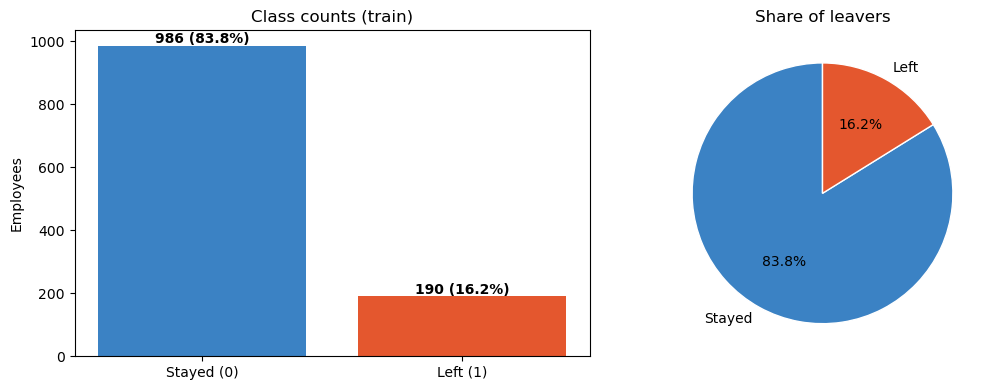

Accuracy of the trivial 'nobody leaves' model: 83.8%  ->  accuracy is a misleading metric here.
A random classifier has PR-AUC ≈ prevalence = 0.162  (ROC-AUC = 0.5)


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
vc = train_df["Attrition"].value_counts().sort_index()
axes[0].bar(["Stayed (0)", "Left (1)"], vc.values, color=[PALETTE[0], PALETTE[1]])
for i, v in enumerate(vc.values): axes[0].text(i, v + 8, f"{v} ({v / vc.sum():.1%})", ha="center", fontweight="bold")
axes[0].set_title("Class counts (train)"); axes[0].set_ylabel("Employees")
axes[1].pie(vc.values, labels=["Stayed", "Left"], colors=[PALETTE[0], PALETTE[1]], autopct="%1.1f%%", startangle=90,
            wedgeprops={"edgecolor": "white"})
axes[1].set_title("Share of leavers")
plt.tight_layout(); plt.show()

print(f"Accuracy of the trivial 'nobody leaves' model: {1 - y_train.mean():.1%}  ->  accuracy is a misleading metric here.")
print(f"A random classifier has PR-AUC ≈ prevalence = {y_train.mean():.3f}  (ROC-AUC = 0.5)")

### 6.2 Numeric features: distributions by outcome

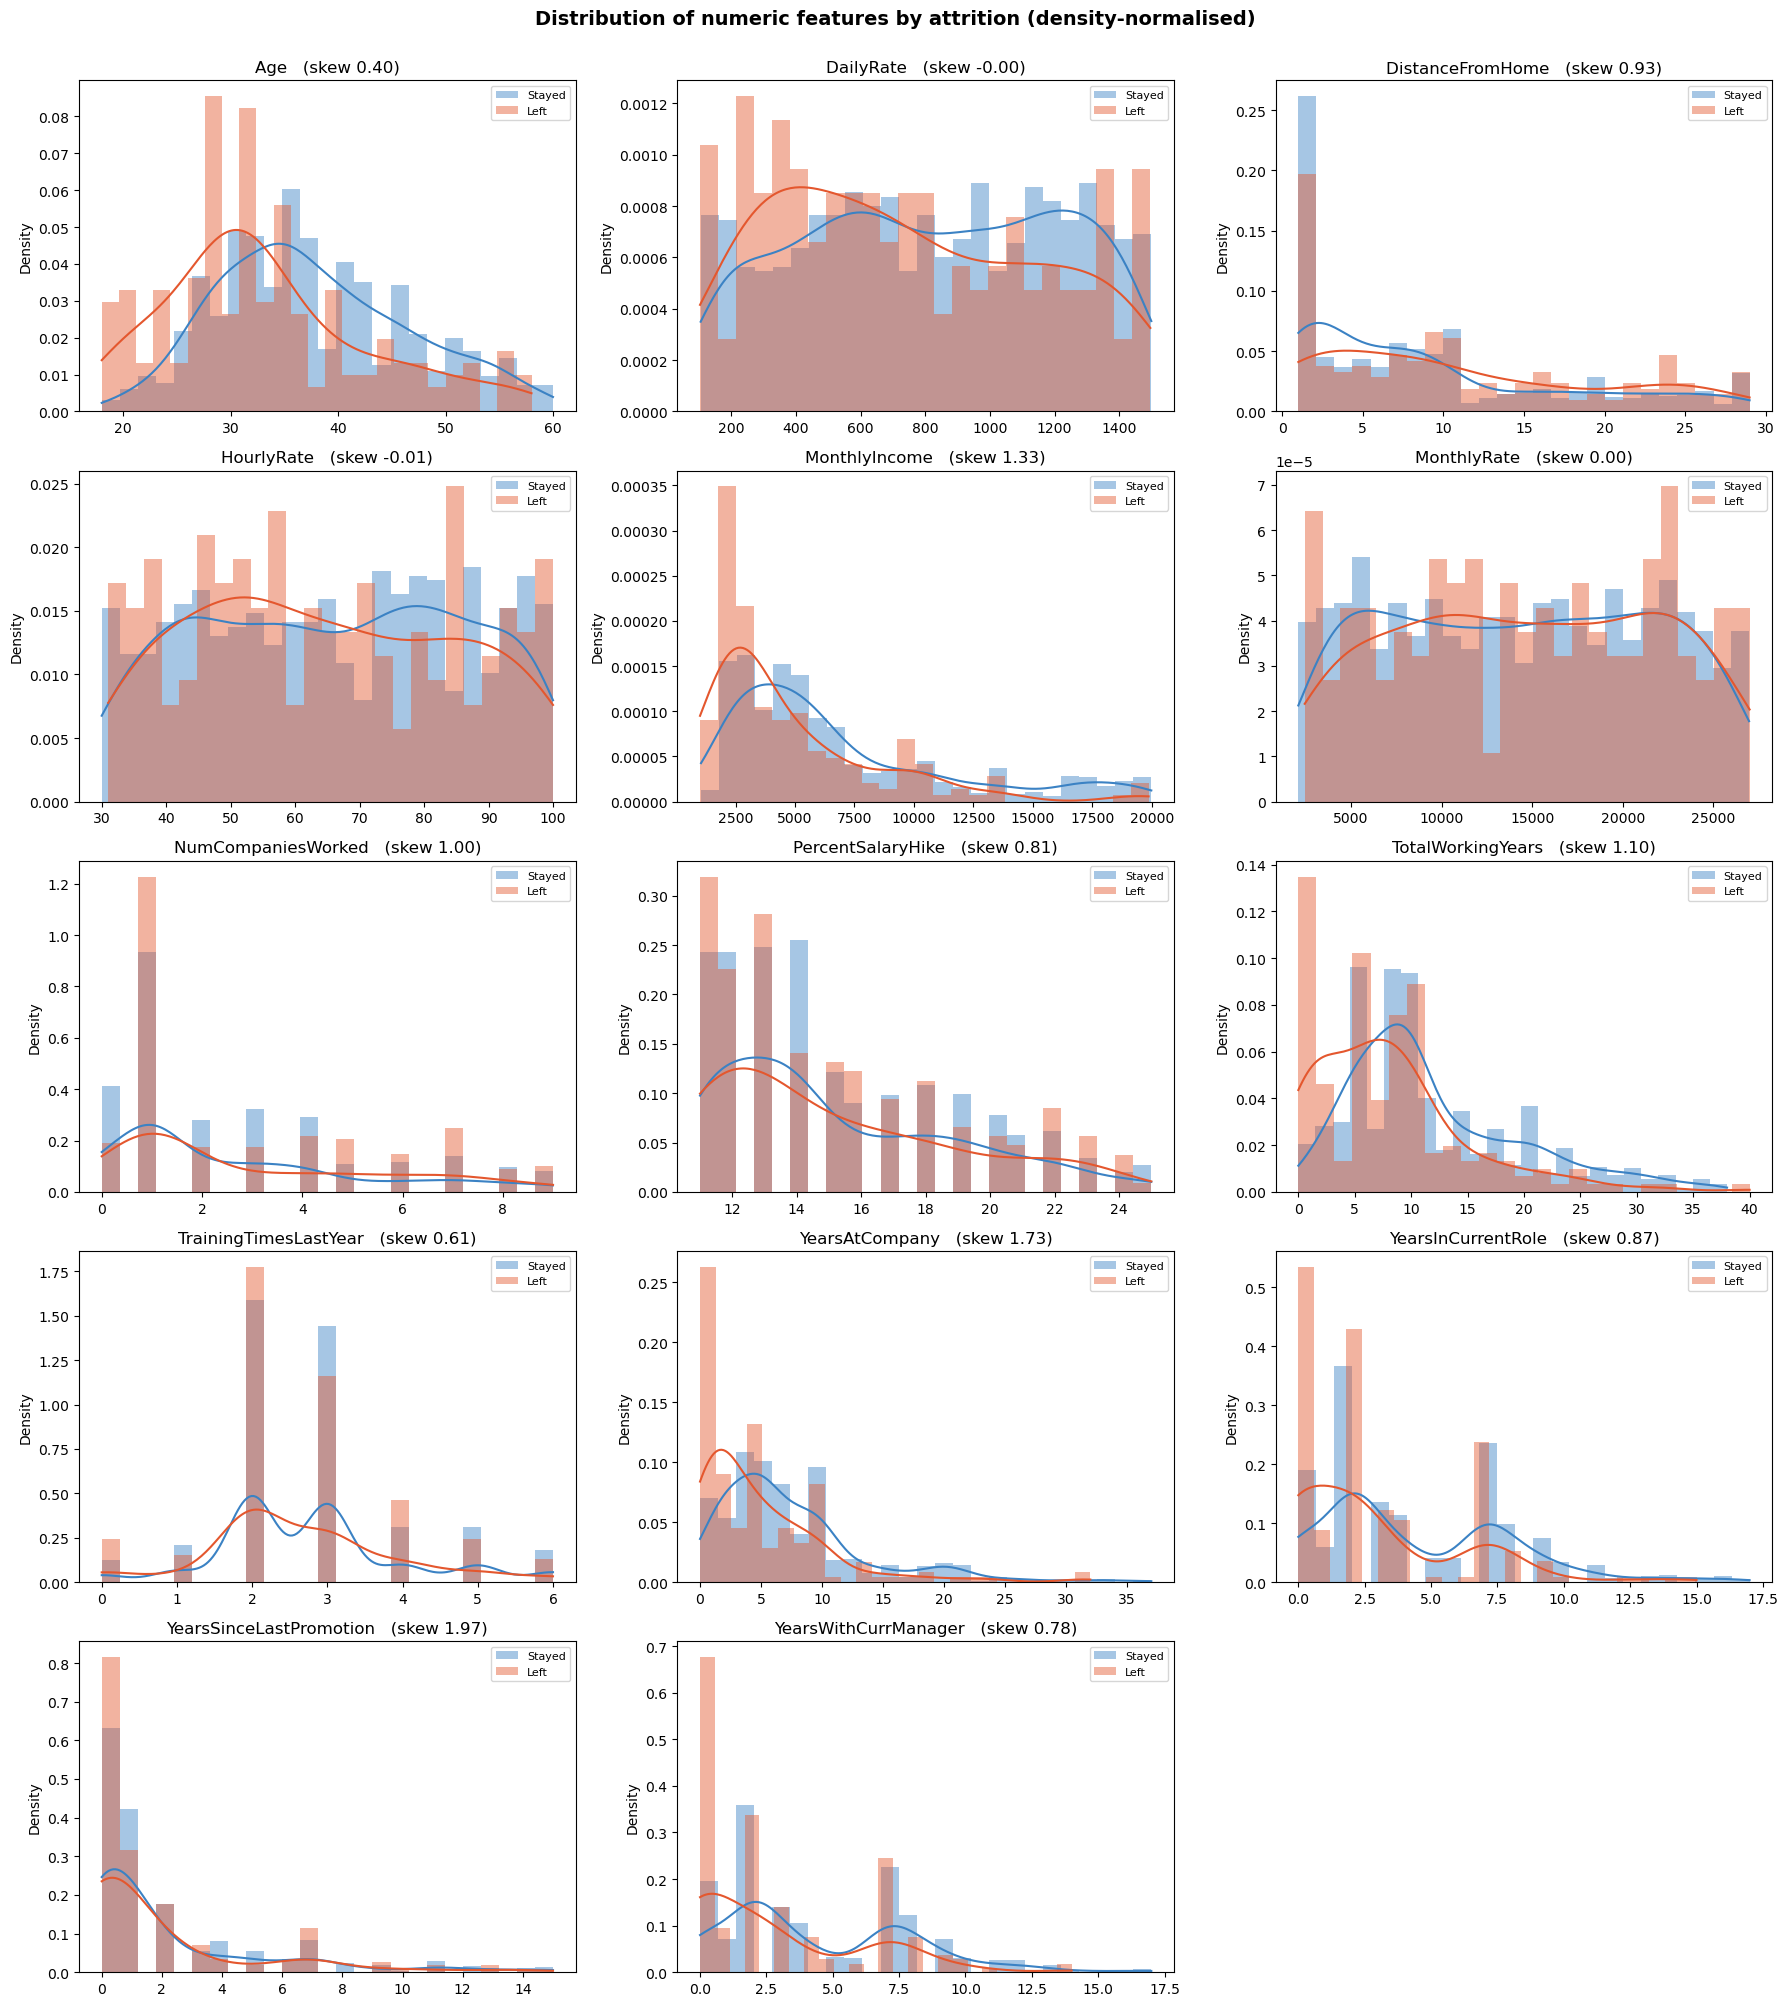

In [13]:
fig, axes = plt.subplots(5, 3, figsize=(18, 20))
for ax, c in zip(axes.ravel(), continuous_cols):
    for k, lab in [(0, "Stayed"), (1, "Left")]:
        sns.histplot(train_df.loc[train_df.Attrition == k, c], ax=ax, stat="density", common_norm=False, bins=25,
                     alpha=.45, color=PALETTE[k], label=lab, kde=True, edgecolor=None)
    ax.set_title(f"{c}   (skew {train_df[c].skew():.2f})"); ax.set_xlabel("")
    ax.legend(fontsize=8)
for ax in axes.ravel()[len(continuous_cols):]: ax.axis("off")
plt.suptitle("Distribution of numeric features by attrition (density-normalised)", y=1.001, fontsize=14, fontweight="bold")
plt.tight_layout(); plt.show()

### 6.3 Categorical & ordinal features: attrition rate by level

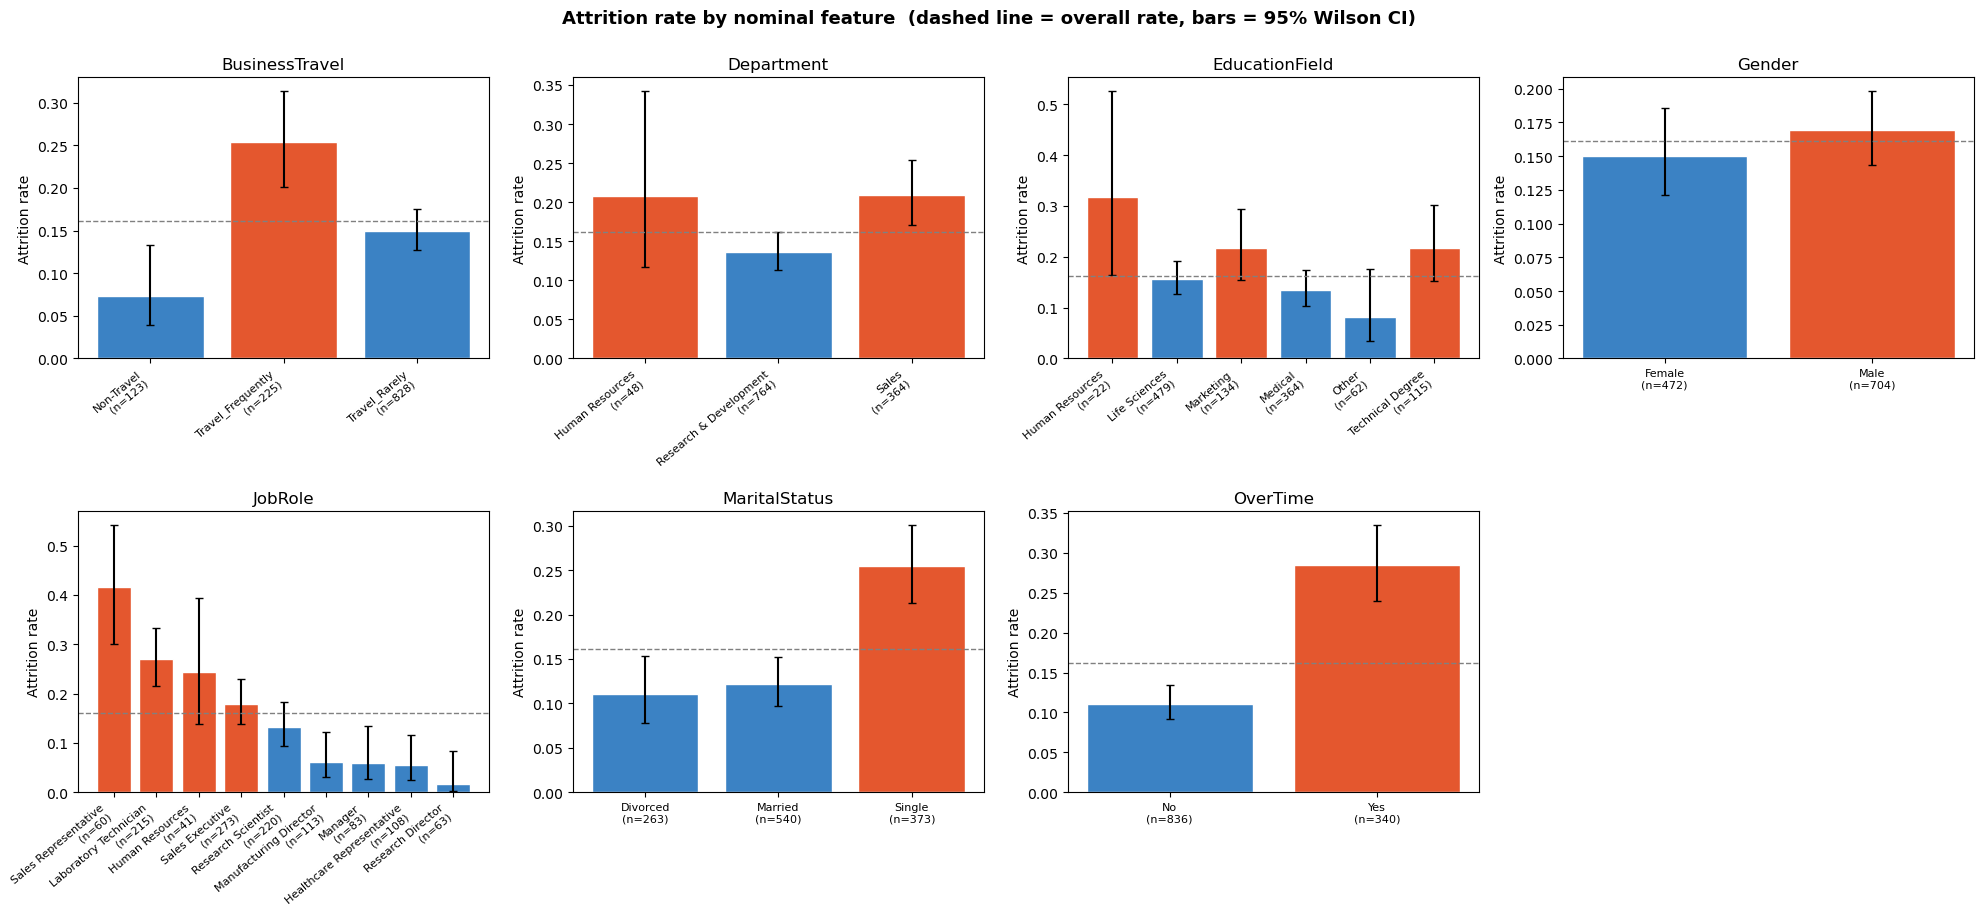

In [14]:
rate_plot(train_df, nominal_cols, ncols=4, title="Attrition rate by nominal feature")

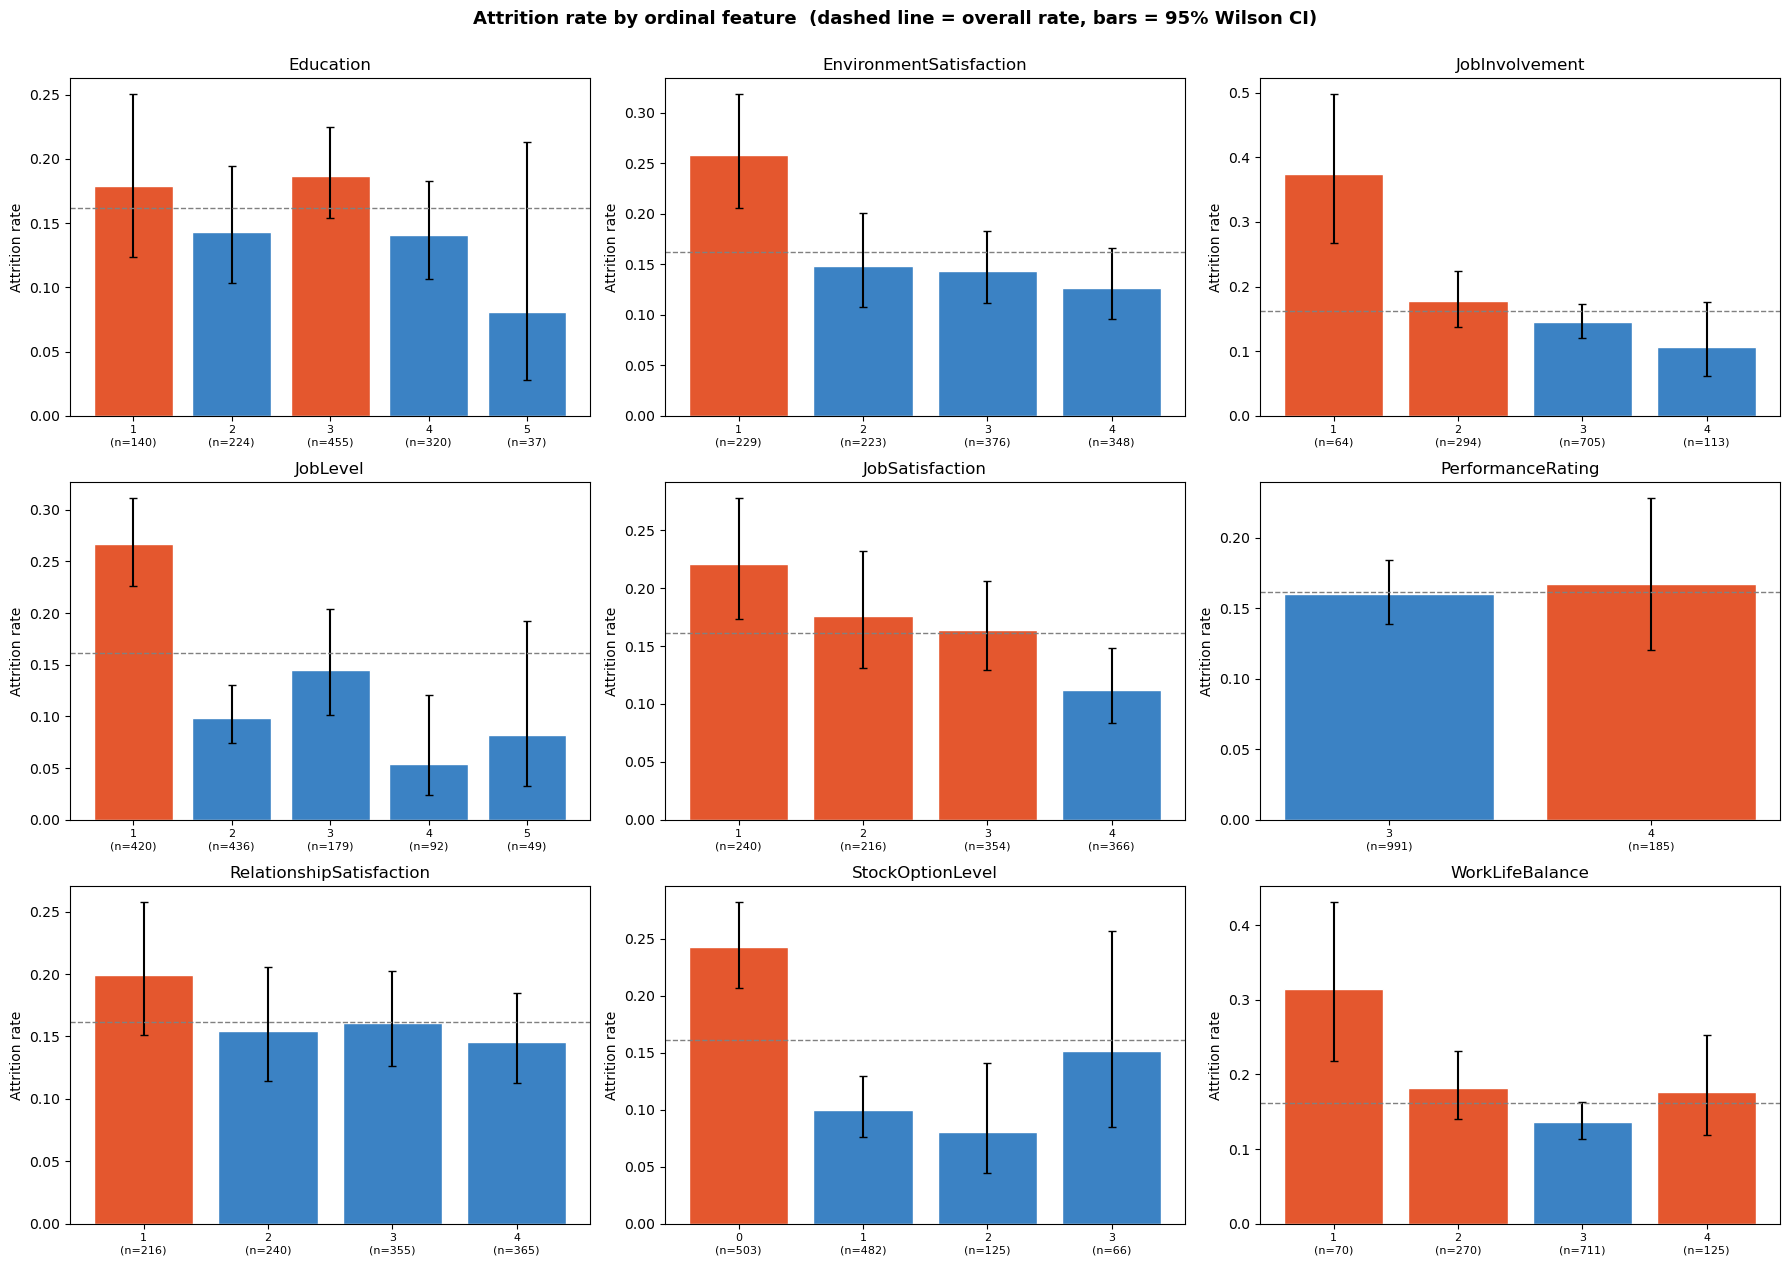

In [15]:
rate_plot(train_df, ordinal_cols, ncols=3, figsize=(18, 4.2), title="Attrition rate by ordinal feature")

### 6.4 Rigorous feature screening (effect sizes + FDR-corrected significance)

We test every feature against the target:
* numeric → Mann-Whitney $U$ (no normality assumption) with rank-biserial effect size,
* categorical / ordinal → $\chi^2$ test with Cramér's V,

then correct all $p$-values with Benjamini–Hochberg. **This table is for understanding only**; the actual feature selection happens *inside* cross-validation later.

,feature,type,test,effect_size,direction,p_value,p_adj_BH,significant_5%
0,TotalWorkingYears,continuous,Mann-Whitney,0.323113,↓ leavers lower,1.474945e-12,1.474945e-11,True
1,YearsAtCompany,continuous,Mann-Whitney,0.319713,↓ leavers lower,2.359153e-12,1.769364e-11,True
2,MonthlyIncome,continuous,Mann-Whitney,0.315544,↓ leavers lower,5.382906e-12,3.229743e-11,True
3,Age,continuous,Mann-Whitney,0.304873,↓ leavers lower,2.627988e-11,1.118263e-10,True
4,YearsWithCurrManager,continuous,Mann-Whitney,0.300630,↓ leavers lower,2.982035e-11,1.118263e-10,True
5,YearsInCurrentRole,continuous,Mann-Whitney,0.291641,↓ leavers lower,1.080131e-10,3.600438e-10,True
6,JobRole,nominal,Chi-square,0.268758,,4.919714e-15,1.475914e-13,True
7,JobLevel,ordinal,Chi-square,0.221064,,9.856956e-12,4.928478e-11,True
8,OverTime,nominal,Chi-square,0.214389,,1.952684e-13,2.929026e-12,True
9,StockOptionLevel,ordinal,Chi-square,0.193885,,1.363528e-09,4.090583e-09,True


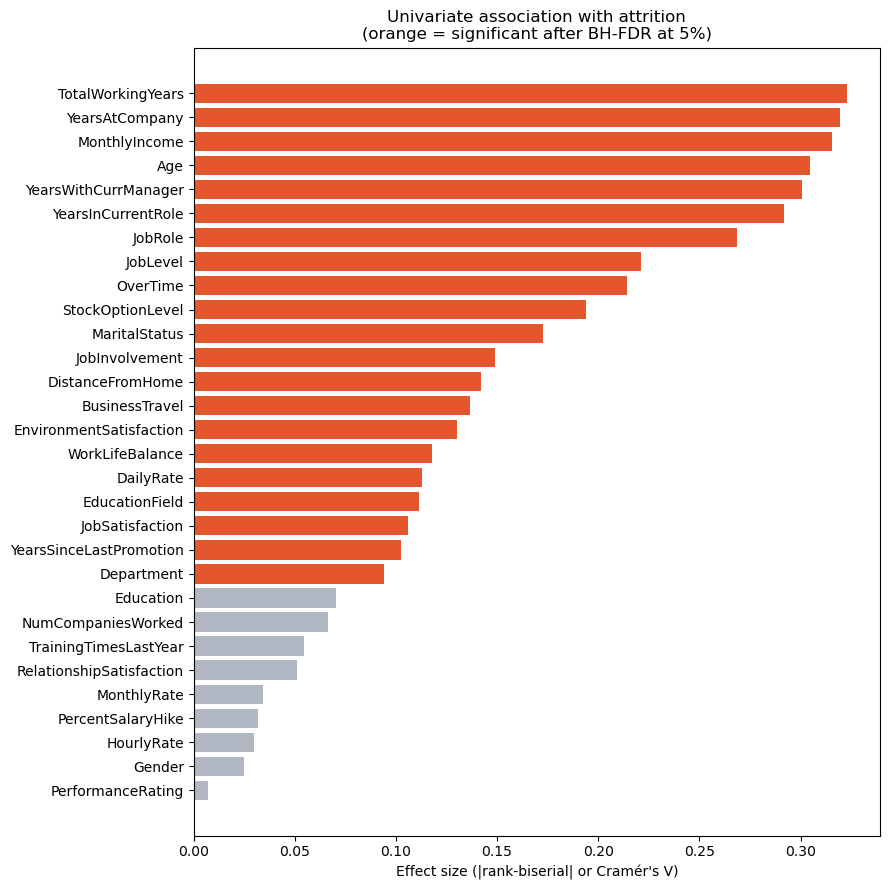

In [16]:
screen = []
for c in continuous_cols:
    r, p = rank_biserial(train_df[c], train_df["Attrition"])
    screen.append({"feature": c, "type": "continuous", "test": "Mann-Whitney", "effect_size": abs(r), "direction": "↑ leavers higher" if r > 0 else "↓ leavers lower", "p_value": p})
for c in nominal_cols + ordinal_cols:
    v, p = cramers_v(train_df[c], train_df["Attrition"])
    screen.append({"feature": c, "type": "nominal" if c in nominal_cols else "ordinal", "test": "Chi-square", "effect_size": v, "direction": "", "p_value": p})

screen = pd.DataFrame(screen)
screen["p_adj_BH"] = multipletests(screen["p_value"], method="fdr_bh")[1]
screen["significant_5%"] = screen["p_adj_BH"] < 0.05
screen = screen.sort_values("effect_size", ascending=False).reset_index(drop=True)
display(screen)

fig, ax = plt.subplots(figsize=(9, 9))
cols = screen["significant_5%"].map({True: "#e4572e", False: "#b0b7c3"})
ax.barh(screen["feature"][::-1], screen["effect_size"][::-1], color=cols[::-1])
ax.set_xlabel("Effect size (|rank-biserial| or Cramér's V)")
ax.set_title("Univariate association with attrition\n(orange = significant after BH-FDR at 5%)")
plt.tight_layout(); plt.show()

### 6.5 Correlation structure & multicollinearity

Spearman correlation (rank-based → robust to skew and valid for ordinal variables).

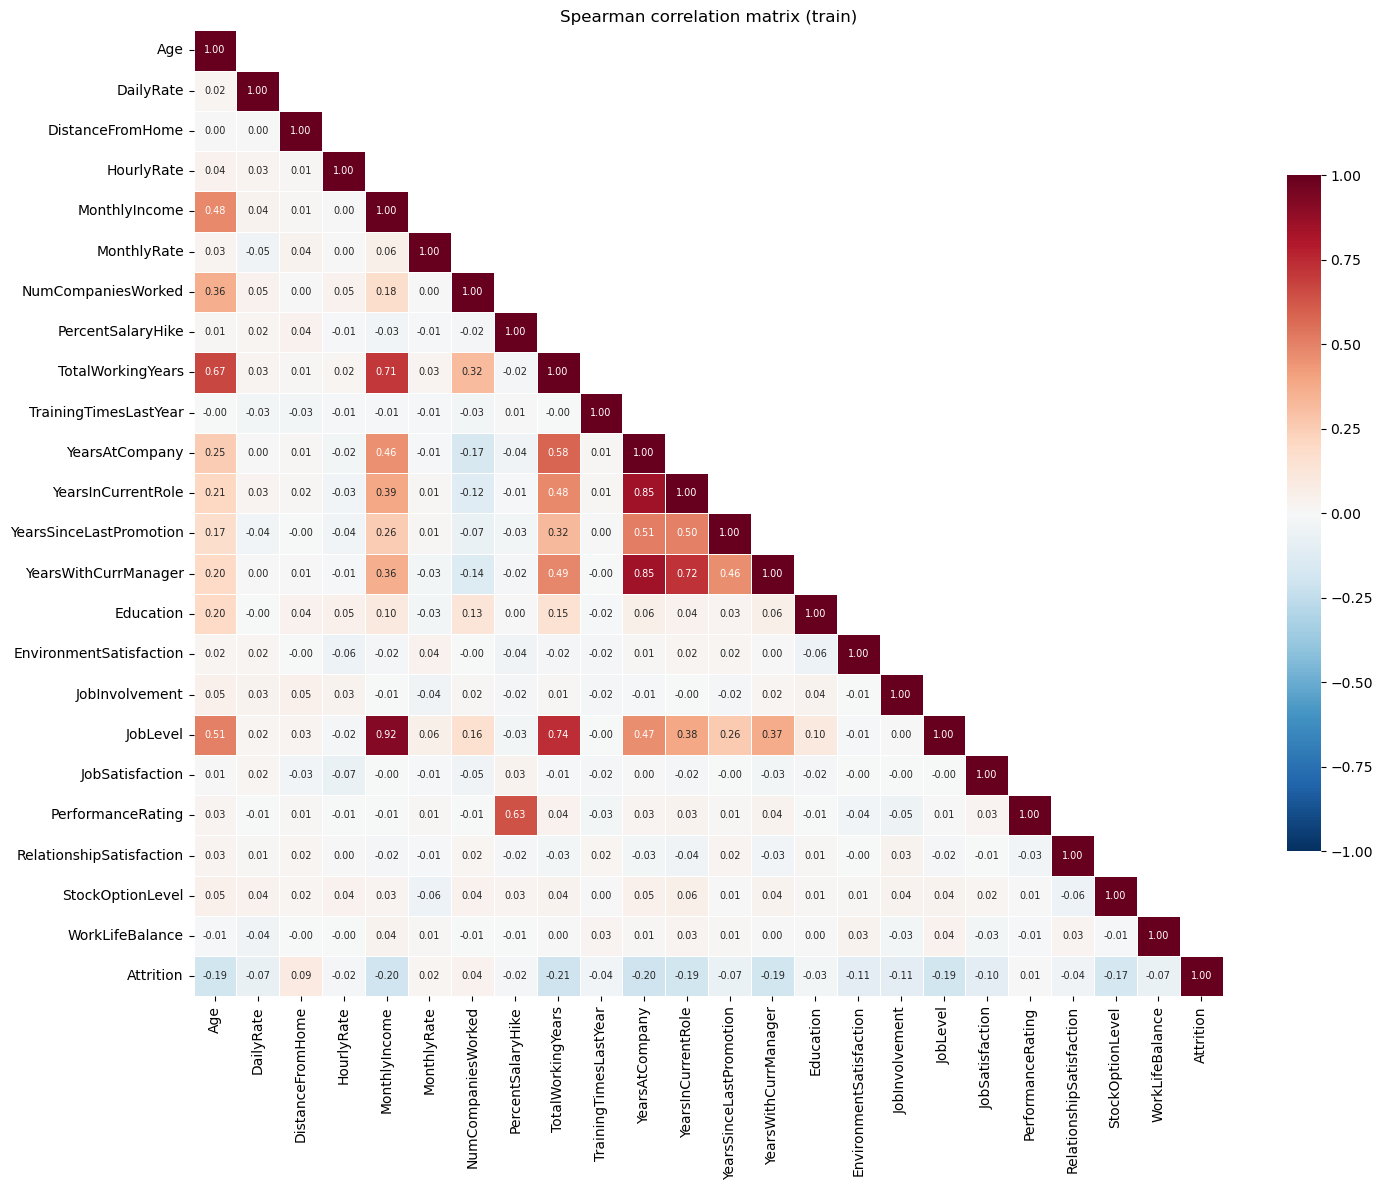

Highly correlated pairs (|ρ| > 0.65) – candidates for redundancy removal:


,feature_a,feature_b,rho
0,JobLevel,MonthlyIncome,0.920390
1,YearsWithCurrManager,YearsAtCompany,0.847037
2,YearsInCurrentRole,YearsAtCompany,0.845861
3,JobLevel,TotalWorkingYears,0.735212
4,YearsWithCurrManager,YearsInCurrentRole,0.724223
5,TotalWorkingYears,MonthlyIncome,0.708072
6,TotalWorkingYears,Age,0.669893



Correlation of each feature with the target (Spearman):


,rho
TotalWorkingYears,-0.206456
YearsAtCompany,-0.204547
MonthlyIncome,-0.201154
Age,-0.194472
YearsWithCurrManager,-0.193930
YearsInCurrentRole,-0.188324
JobLevel,-0.187813
StockOptionLevel,-0.172726
JobInvolvement,-0.109313
EnvironmentSatisfaction,-0.106582


In [17]:
corr_cols = continuous_cols + ordinal_cols
corr = train_df[corr_cols + ["Attrition"]].corr(method="spearman")
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
fig, ax = plt.subplots(figsize=(15, 12))
sns.heatmap(corr, mask=mask, cmap="RdBu_r", center=0, vmin=-1, vmax=1, annot=True, fmt=".2f", annot_kws={"size": 7},
            linewidths=.4, cbar_kws={"shrink": .7}, ax=ax)
ax.set_title("Spearman correlation matrix (train)")
plt.tight_layout(); plt.show()

pairs = (corr.where(~mask & (np.eye(len(corr)) == 0)).stack().rename("rho").reset_index())
pairs.columns = ["feature_a", "feature_b", "rho"]
pairs = pairs[(pairs.rho.abs() > 0.65) & (pairs.feature_a != "Attrition") & (pairs.feature_b != "Attrition")]
print("Highly correlated pairs (|ρ| > 0.65) – candidates for redundancy removal:")
display(pairs.sort_values("rho", key=abs, ascending=False).reset_index(drop=True))

print("\nCorrelation of each feature with the target (Spearman):")
display(corr["Attrition"].drop("Attrition").sort_values(key=abs, ascending=False).head(12).to_frame("rho"))

### 6.6 Deeper, multivariate views

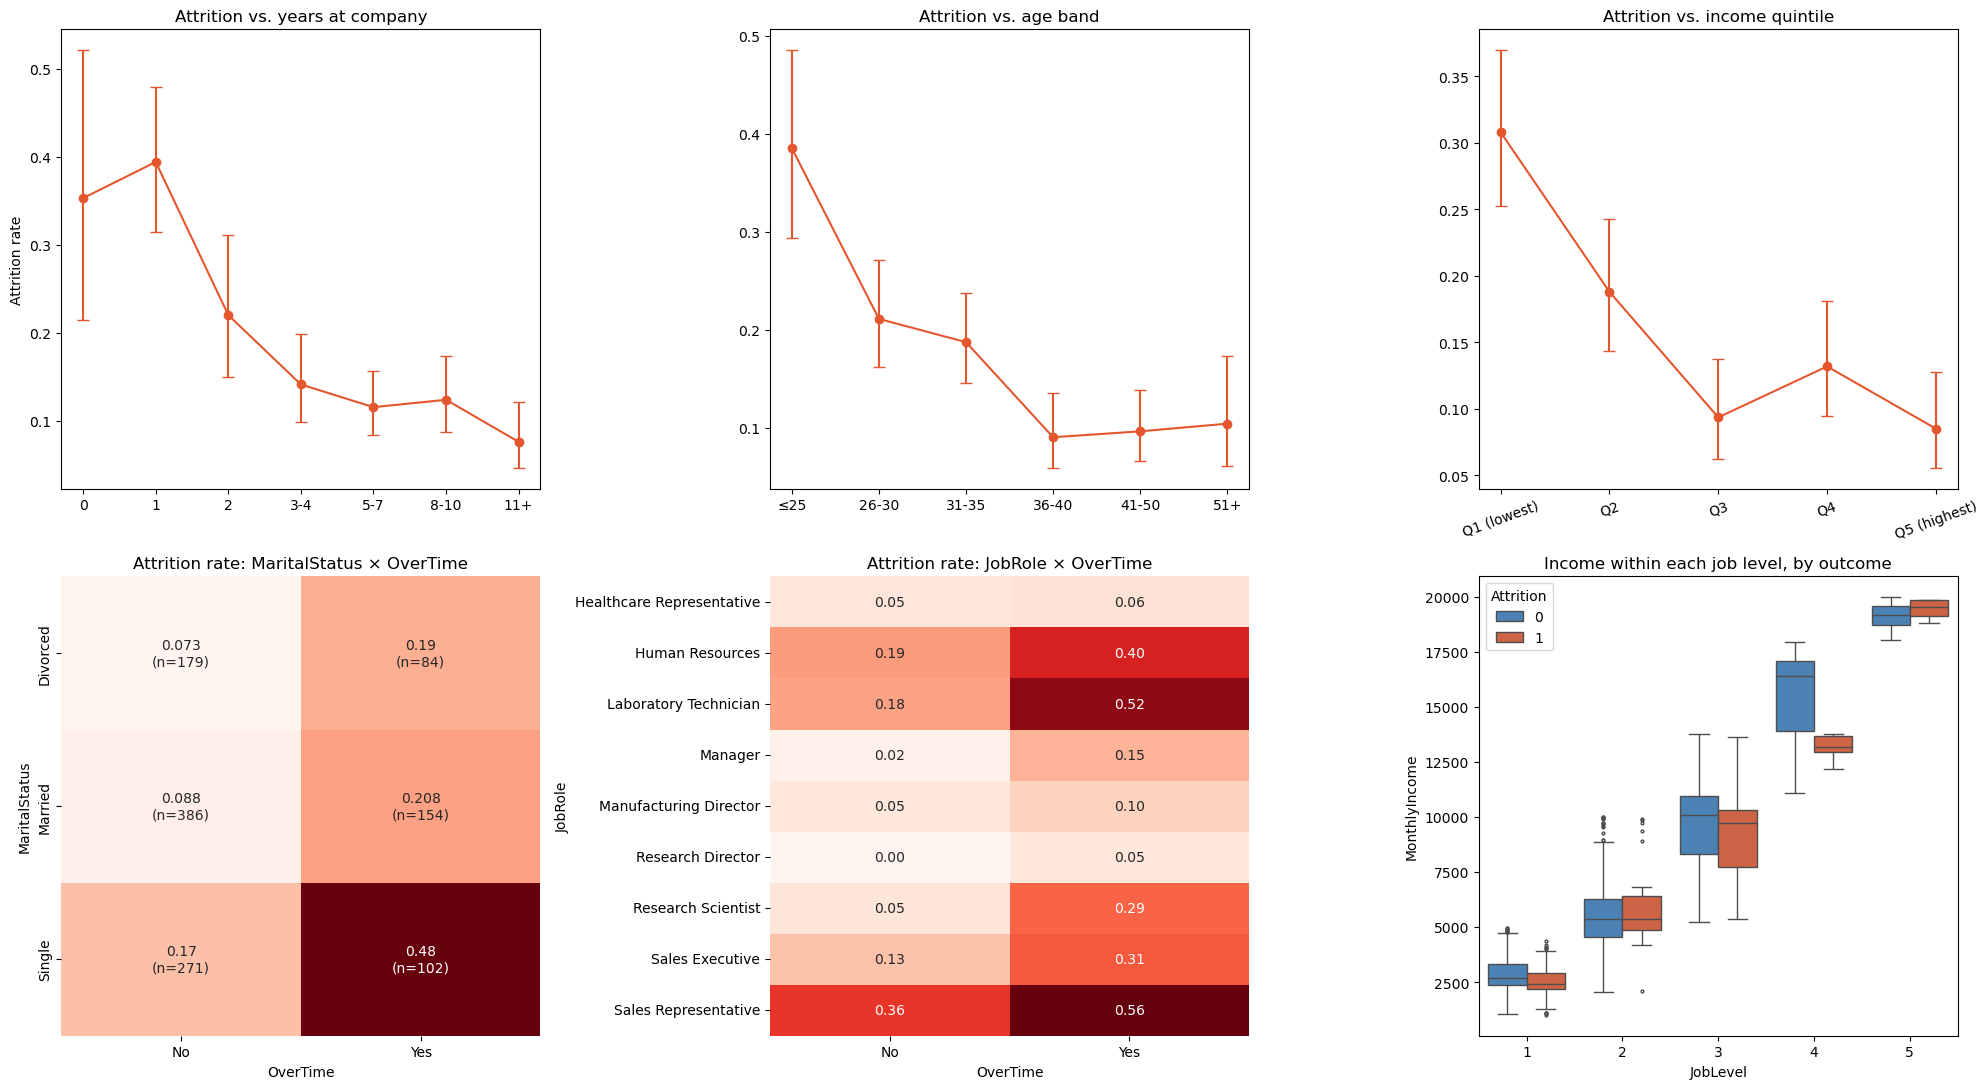

In [18]:
fig, axes = plt.subplots(2, 3, figsize=(20, 11))

# (a) Tenure bands – a "hazard curve" view of when people leave
b = pd.cut(train_df["YearsAtCompany"], [-1, 0, 1, 2, 4, 7, 10, 40], labels=["0", "1", "2", "3-4", "5-7", "8-10", "11+"])
g = rate_table(train_df.assign(Tenure=b), "Tenure")
axes[0, 0].errorbar(g.index.astype(str), g["rate"], yerr=[g["rate"] - g["lo"], g["hi"] - g["rate"]], fmt="o-", capsize=4, color="#e4572e")
axes[0, 0].set_title("Attrition vs. years at company"); axes[0, 0].set_ylabel("Attrition rate")

# (b) Age bands
b = pd.cut(train_df["Age"], [17, 25, 30, 35, 40, 50, 61], labels=["≤25", "26-30", "31-35", "36-40", "41-50", "51+"])
g = rate_table(train_df.assign(AgeBand=b), "AgeBand")
axes[0, 1].errorbar(g.index.astype(str), g["rate"], yerr=[g["rate"] - g["lo"], g["hi"] - g["rate"]], fmt="o-", capsize=4, color="#e4572e")
axes[0, 1].set_title("Attrition vs. age band")

# (c) Income quintiles
b = pd.qcut(train_df["MonthlyIncome"], 5, labels=["Q1 (lowest)", "Q2", "Q3", "Q4", "Q5 (highest)"])
g = rate_table(train_df.assign(IncomeQ=b), "IncomeQ")
axes[0, 2].errorbar(g.index.astype(str), g["rate"], yerr=[g["rate"] - g["lo"], g["hi"] - g["rate"]], fmt="o-", capsize=4, color="#e4572e")
axes[0, 2].set_title("Attrition vs. income quintile"); axes[0, 2].tick_params(axis="x", rotation=20)

# (d) OverTime x MaritalStatus heat-map
pv = train_df.pivot_table(index="MaritalStatus", columns="OverTime", values="Attrition", aggfunc="mean")
cnt = train_df.pivot_table(index="MaritalStatus", columns="OverTime", values="Attrition", aggfunc="count")
annot = pv.round(3).astype(str) + "\n(n=" + cnt.astype(str) + ")"
sns.heatmap(pv, annot=annot, fmt="", cmap="Reds", ax=axes[1, 0], cbar=False)
axes[1, 0].set_title("Attrition rate: MaritalStatus × OverTime")

# (e) JobRole x OverTime
pv = train_df.pivot_table(index="JobRole", columns="OverTime", values="Attrition", aggfunc="mean")
sns.heatmap(pv, annot=True, fmt=".2f", cmap="Reds", ax=axes[1, 1], cbar=False)
axes[1, 1].set_title("Attrition rate: JobRole × OverTime")

# (f) Income by job level, split by outcome
sns.boxplot(data=train_df, x="JobLevel", y="MonthlyIncome", hue="Attrition", palette=PALETTE, ax=axes[1, 2], fliersize=2)
axes[1, 2].set_title("Income within each job level, by outcome")
plt.tight_layout(); plt.show()

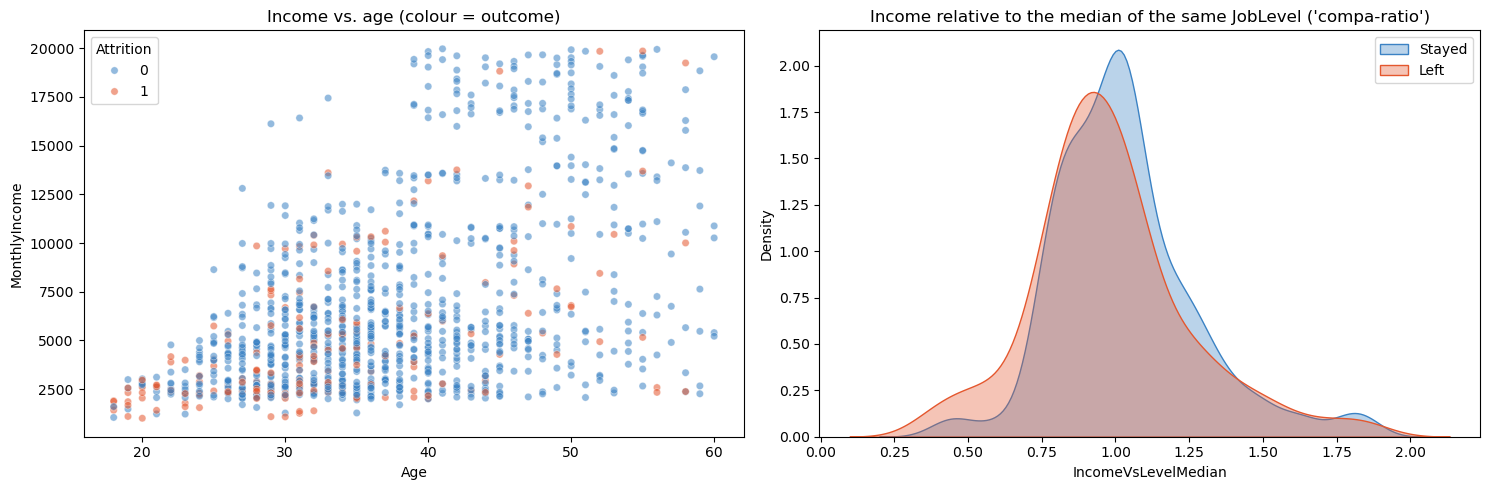

In [19]:
# Peer-relative pay: is it *relative* pay (vs. same job level) rather than absolute pay that matters?
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.scatterplot(data=train_df, x="Age", y="MonthlyIncome", hue="Attrition", palette=PALETTE, alpha=.55, s=28, ax=axes[0])
axes[0].set_title("Income vs. age (colour = outcome)")
tmp = train_df.assign(IncomeVsLevelMedian=train_df["MonthlyIncome"] / train_df.groupby("JobLevel")["MonthlyIncome"].transform("median"))
for k, lab in [(0, "Stayed"), (1, "Left")]:
    sns.kdeplot(tmp.loc[tmp.Attrition == k, "IncomeVsLevelMedian"], ax=axes[1], fill=True, alpha=.35, color=PALETTE[k], label=lab, clip=(0, 3))
axes[1].set_title("Income relative to the median of the same JobLevel ('compa-ratio')"); axes[1].legend()
plt.tight_layout(); plt.show()

### 6.7 EDA takeaways → modelling decisions

| Finding | Evidence | Decision |
|---|---|---|
| **Imbalance** (~16 % leavers) | Section 6.1 | Use ROC-AUC/PR-AUC, class weights, compare SMOTE, tune thresholds |
| **Overtime, low job level, single marital status, frequent travel, sales-rep role, no stock options, low involvement/work-life balance** show markedly higher attrition | Sections 6.3–6.4 | Keep; build interaction features (e.g. *single × overtime*, *overtime × travel*) |
| **Early tenure & young age** carry the highest risk; risk decays with tenure | 6.6 (a, b) | Tenure-ratio features, "early tenure" flag |
| **Lower income** among leavers – but income is tightly tied to *JobLevel* | 6.6 (c, f) | Engineer **peer-relative pay** (compa-ratio & shrunk z-score within role × level) |
| **Heavy right-skew** in income & tenure variables | 4.6, 6.2 | Yeo-Johnson power transform |
| **Strong redundancy**: income ↔ job level ↔ total working years ↔ age; tenure variables ↔ each other | 6.5 | Correlation filter + VIF pruning (inside CV) |
| **`HourlyRate` / `MonthlyRate` look like noise** (uncorrelated with income, no association with the target; `DailyRate` only weak) | 4.5, 6.4 | Let cross-validated selection decide |
| Gender, Education, PerformanceRating, PercentSalaryHike, TrainingTimes, RelationshipSatisfaction, NumCompaniesWorked are **not significant** after FDR correction (univariately) | 6.4 | Retain for now (they may matter in combination), let regularisation/selection prune |

---
# 7. Feature Engineering (with the math)

Raw columns describe *levels*; attrition is driven by *relationships* (pay **relative to peers**, tenure **relative to career length**, stagnation, satisfaction **profile**). Below, every engineered feature is defined mathematically.

Let $\varepsilon = 1$ (add-one smoothing) so ratios stay finite when a denominator is 0 and are stabilised when it is small.

### 7.1 Career-shape ratios
$$\text{TenureRatio}_i=\frac{\text{YearsAtCompany}_i}{\text{TotalWorkingYears}_i+\varepsilon},\qquad
\text{JobHopIndex}_i=\frac{\text{NumCompaniesWorked}_i}{\text{TotalWorkingYears}_i+\varepsilon}$$
$$\text{PromotionStagnation}_i=\frac{\text{YearsSinceLastPromotion}_i}{\text{YearsAtCompany}_i+\varepsilon},\quad
\text{RoleStagnation}_i=\frac{\text{YearsInCurrentRole}_i}{\text{YearsAtCompany}_i+\varepsilon},\quad
\text{ManagerShare}_i=\frac{\text{YearsWithCurrManager}_i}{\text{YearsAtCompany}_i+\varepsilon}$$
$$\text{IncomePerExpYear}_i=\frac{\text{MonthlyIncome}_i}{\text{TotalWorkingYears}_i+\varepsilon},\qquad \text{CareerStartAge}_i=\text{Age}_i-\text{TotalWorkingYears}_i$$

### 7.2 Peer-relative pay (fitted on the training data only)
For job level $\ell$ let $m_\ell$ be the **median** income of that level. The *compa-ratio* is
$$\text{CompaRatio}_i=\frac{\text{MonthlyIncome}_i}{m_{\ell(i)}}$$
Next, a **z-score of log-income inside the (role $r$ × level $\ell$) cell**. Cells can be tiny, so we apply *empirical-Bayes shrinkage* toward the level-wide statistics. With $n_c$ employees in the cell, cell mean/variance $(\mu_c,\sigma_c^2)$ of $\ln(\text{income})$, level-wide $(\mu_\ell,\sigma_\ell^2)$ and shrinkage strength $k$:
$$\tilde\mu_c=\frac{n_c\,\mu_c+k\,\mu_\ell}{n_c+k},\qquad
\tilde\sigma_c^2=\frac{n_c\,\sigma_c^2+k\,\sigma_\ell^2}{n_c+k},\qquad
z_i=\frac{\ln(\text{MonthlyIncome}_i)-\tilde\mu_{c(i)}}{\tilde\sigma_{c(i)}}$$
With $n_c\!\to\!0$ the estimate falls back to the level average; with large $n_c$ it trusts the cell. These statistics are **learned in `fit()`** (train folds only) – a textbook place where leakage sneaks in if done on the whole dataset.

### 7.3 Satisfaction profile (five 1–4 survey items $s_1,\dots,s_5$)
$$\text{Mean}=\frac1m\sum_j s_j,\qquad \text{Geo}=\exp\!\Big(\frac1m\sum_j\ln s_j\Big),\qquad \text{Min}=\min_j s_j,\qquad \text{Std}=\sqrt{\tfrac1m\sum_j (s_j-\bar s)^2},\qquad \text{LowCount}=\sum_j \mathbb 1[s_j\le 2]$$
The **geometric mean** is deliberately harsher than the arithmetic mean: by AM–GM, $\text{Geo}\le\text{Mean}$ with the gap growing as the profile becomes lopsided, so one terrible dimension (e.g. work-life balance = 1) is penalised.

### 7.4 Interactions & flags (motivated by Section 6)
$\text{OT}\times\text{Travel}=\mathbb 1[\text{OverTime}]\cdot \text{TravelLevel}$, $\;\text{SingleOvertime}=\mathbb 1[\text{Single}]\cdot\mathbb 1[\text{OverTime}]$, $\;\text{EarlyTenure}=\mathbb 1[\text{YearsAtCompany}\le 2]$.

### 7.5 Yeo–Johnson power transform (applied in the preprocessing step, Section 8)
Chooses $\lambda$ per feature by maximum likelihood so the transformed variable is as Gaussian as possible, and – unlike Box–Cox – is defined for zeros/negatives:
$$\psi(y;\lambda)=\begin{cases}
\dfrac{(y+1)^{\lambda}-1}{\lambda} & y\ge0,\ \lambda\ne0\\[2mm]
\ln(y+1) & y\ge0,\ \lambda=0\\[1mm]
-\dfrac{(-y+1)^{2-\lambda}-1}{2-\lambda} & y<0,\ \lambda\ne2\\[2mm]
-\ln(-y+1) & y<0,\ \lambda=2
\end{cases}$$
followed by standardisation $x'=(\psi-\mu_\psi)/\sigma_\psi$.

In [20]:
class HRFeatureEngineer(BaseEstimator, TransformerMixin):
    """Leakage-safe feature engineering.
    fit()      -> learns peer statistics (median / mean / variance of income by level and role x level)
    transform()-> deterministic row-wise features + the learned peer-relative features.
    add_features=False yields only the encoded raw columns (used for the ablation study)."""

    SAT_COLS = ["EnvironmentSatisfaction", "JobSatisfaction", "RelationshipSatisfaction", "WorkLifeBalance", "JobInvolvement"]
    TRAVEL_MAP = {"Non-Travel": 0, "Travel_Rarely": 1, "Travel_Frequently": 2}

    def __init__(self, add_features=True, shrink_k=5.0, eps=1.0):
        self.add_features = add_features
        self.shrink_k = shrink_k
        self.eps = eps

    @staticmethod
    def _sanitize(X):
        X = pd.DataFrame(X).copy()
        for c in ["Department", "EducationField", "JobRole", "MaritalStatus"]:
            X[c] = X[c].astype(str).str.replace(r"[^0-9A-Za-z]+", "_", regex=True)   # model-library-safe names
        return X

    def fit(self, X, y=None):                       # NOTE: y is deliberately ignored -> peer stats are label-free
        X = self._sanitize(X)
        inc = X["MonthlyIncome"].astype(float)
        li = np.log(inc)
        self.global_median_ = inc.median()
        self.global_mu_, self.global_var_ = li.mean(), li.var(ddof=1)
        self.level_median_ = inc.groupby(X["JobLevel"]).median().to_dict()
        self.level_mu_ = li.groupby(X["JobLevel"]).mean().to_dict()
        self.level_var_ = li.groupby(X["JobLevel"]).var(ddof=1).to_dict()
        self.cell_ = {k: (len(v), v.mean(), v.var(ddof=1) if len(v) > 1 else np.nan)
                      for k, v in li.groupby([X["JobRole"], X["JobLevel"]])}
        return self

    def transform(self, X):
        X = self._sanitize(X)
        o = pd.DataFrame(index=X.index)
        e = self.eps

        # ---- encoded raw columns -------------------------------------------------
        o["OverTime_bin"] = (X["OverTime"] == "Yes").astype(int)
        o["Gender_bin"] = (X["Gender"] == "Male").astype(int)
        o["BusinessTravel_ord"] = X["BusinessTravel"].map(self.TRAVEL_MAP).astype(int)
        raw_num = [c for c in X.columns if c not in ["OverTime", "Gender", "BusinessTravel"]]
        o = pd.concat([X[raw_num], o], axis=1)

        if not self.add_features:
            return o

        inc = X["MonthlyIncome"].astype(float)
        # ---- 7.1 career-shape ratios -----------------------------------------------
        o["TenureRatio"]         = X["YearsAtCompany"] / (X["TotalWorkingYears"] + e)
        o["JobHopIndex"]         = X["NumCompaniesWorked"] / (X["TotalWorkingYears"] + e)
        o["PromotionStagnation"] = X["YearsSinceLastPromotion"] / (X["YearsAtCompany"] + e)
        o["RoleStagnation"]      = X["YearsInCurrentRole"] / (X["YearsAtCompany"] + e)
        o["ManagerShare"]        = X["YearsWithCurrManager"] / (X["YearsAtCompany"] + e)
        o["IncomePerExpYear"]    = inc / (X["TotalWorkingYears"] + e)
        o["CareerStartAge"]      = X["Age"] - X["TotalWorkingYears"]

        # ---- 7.2 peer-relative pay (statistics learned in fit) -------------------------
        med = X["JobLevel"].map(self.level_median_).fillna(self.global_median_)
        o["CompaRatioLevel"] = inc / med
        li = np.log(inc).values
        mu, sd = np.empty(len(X)), np.empty(len(X))
        for i, (role, lvl) in enumerate(zip(X["JobRole"], X["JobLevel"])):
            mu_l = self.level_mu_.get(lvl, self.global_mu_)
            var_l = self.level_var_.get(lvl, self.global_var_)
            n, m, v = self.cell_.get((role, lvl), (0, mu_l, var_l))
            if not np.isfinite(v): v = var_l
            k = self.shrink_k
            mu[i] = (n * m + k * mu_l) / (n + k)
            sd[i] = np.sqrt((n * v + k * var_l) / (n + k))
        o["LogIncomeZ_RoleLevel"] = (li - mu) / sd

        # ---- 7.3 satisfaction profile -----------------------------------------------------
        S = X[self.SAT_COLS].astype(float)
        o["SatisfactionMean"] = S.mean(axis=1)
        o["SatisfactionGeo"]  = np.exp(np.log(S).mean(axis=1))
        o["SatisfactionMin"]  = S.min(axis=1)
        o["SatisfactionStd"]  = S.std(axis=1, ddof=0)
        o["LowSatCount"]      = (S <= 2).sum(axis=1)

        # ---- 7.4 interactions & flags ---------------------------------------------------------
        o["OT_x_Travel"]    = o["OverTime_bin"] * o["BusinessTravel_ord"]
        o["SingleOvertime"] = ((X["MaritalStatus"] == "Single") & (o["OverTime_bin"] == 1)).astype(int)
        o["EarlyTenure"]    = (X["YearsAtCompany"] <= 2).astype(int)
        return o

# quick demonstration on the TRAIN set only
fe_demo = HRFeatureEngineer().fit(X_train)
F_train = fe_demo.transform(X_train)
print("Engineered frame:", F_train.shape)
new_feats = [c for c in F_train.columns if c not in X_train.columns]
display(F_train[new_feats].describe().T)

Engineered frame: (1176, 47)


,count,mean,std,min,25%,50%,75%,max
OverTime_bin,1176.0,0.289116,0.453545,0.000000,0.000000,0.000000,1.000000,1.000000
Gender_bin,1176.0,0.598639,0.490382,0.000000,0.000000,1.000000,1.000000,1.000000
BusinessTravel_ord,1176.0,1.086735,0.537253,0.000000,1.000000,1.000000,1.000000,2.000000
TenureRatio,1176.0,0.584530,0.283479,0.000000,0.375000,0.639610,0.833333,0.972973
JobHopIndex,1176.0,0.276346,0.294117,0.000000,0.090909,0.166667,0.388889,2.250000
PromotionStagnation,1176.0,0.235569,0.269938,0.000000,0.000000,0.142857,0.428571,0.916667
RoleStagnation,1176.0,0.482579,0.273429,0.000000,0.333333,0.500000,0.666667,0.875000
ManagerShare,1176.0,0.473042,0.275585,0.000000,0.333333,0.500000,0.666667,0.894737
IncomePerExpYear,1176.0,588.269059,282.612484,95.285714,386.256303,552.795455,734.089932,1904.000000
CareerStartAge,1176.0,25.633503,6.755993,18.000000,20.000000,24.000000,30.000000,56.000000


In [21]:
# Does the AM–GM property hold?  Geo <= Mean, gap grows with dispersion
chk = F_train[["SatisfactionMean", "SatisfactionGeo", "SatisfactionStd"]]
print("Geo <= Mean for every row:", bool((chk.SatisfactionGeo <= chk.SatisfactionMean + 1e-12).all()))
print("corr(gap, Std) =", round(float(np.corrcoef(chk.SatisfactionMean - chk.SatisfactionGeo, chk.SatisfactionStd)[0, 1]), 3))

Geo <= Mean for every row: True
corr(gap, Std) = 0.947


### 7.6 Feature screening with information theory (train only, for insight)

Three complementary, label-aware yardsticks (all computed on the **training** set):

* **Weight of Evidence & Information Value** – for bin $k$ with $n^{1}_k$ leavers and $n^{0}_k$ stayers (totals $N^1, N^0$; +0.5 smoothing):
$$\text{WoE}_k=\ln\frac{n^{1}_k/N^{1}}{n^{0}_k/N^{0}},\qquad \text{IV}=\sum_k\Big(\frac{n^{1}_k}{N^{1}}-\frac{n^{0}_k}{N^{0}}\Big)\text{WoE}_k$$
  Rule of thumb: IV < 0.02 useless · 0.02–0.1 weak · 0.1–0.3 medium · 0.3–0.5 strong · > 0.5 suspiciously strong (check leakage!).
* **Mutual information** $I(X;Y)=\sum_{x,y}p(x,y)\ln\frac{p(x,y)}{p(x)p(y)}$ – captures non-linear dependence.
* **Single-feature AUC** – ranking power of one feature alone: $\max(\text{AUC},1-\text{AUC})$.

,feature,IV,single_AUC,MI,engineered
0,JobRole,0.557847,NaN,0.040965,False
1,TotalWorkingYears,0.428414,0.661557,0.028005,False
2,YearsAtCompany,0.413322,0.659856,0.019114,False
3,MonthlyIncome,0.403914,0.657772,0.035580,False
4,JobHopIndex,0.396563,0.676975,0.015683,True
5,SingleOvertime,0.370754,0.602071,0.027104,True
6,JobLevel,0.353546,0.639703,0.024373,False
7,EarlyTenure,0.353144,0.635038,0.024906,True
8,Age,0.338958,0.652437,0.017062,False
9,SatisfactionGeo,0.338321,0.659251,0.015650,True


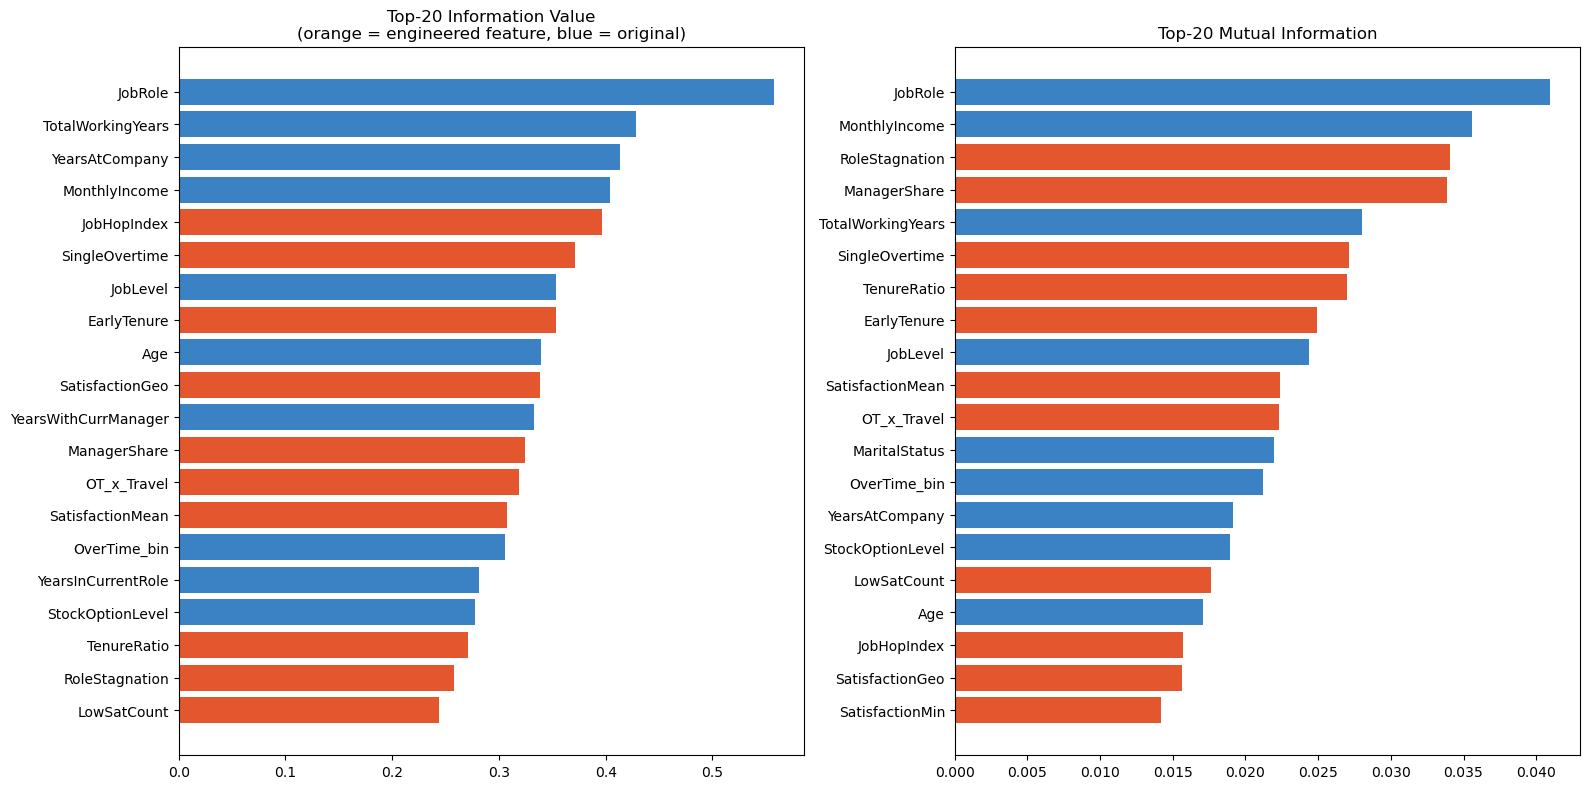

Max IV = 0.558 (JobRole). IV > 0.5 normally triggers a leakage review; here it is driven by a 9-level categorical with uneven group sizes, and IV is biased upward when only 190 positives are spread over many sparse bins. The review is completed in Section 12 with single-feature AUC (max ≈ 0.68 → no feature is a proxy for the target).


In [22]:
def information_value(feature, target, bins=10):
    f = feature.copy()
    if pd.api.types.is_numeric_dtype(f) and f.nunique() > bins:
        f = pd.qcut(f, bins, duplicates="drop")
    t = pd.crosstab(f, target).reindex(columns=[0, 1], fill_value=0) + 0.5
    p0, p1 = t[0] / t[0].sum(), t[1] / t[1].sum()
    woe = np.log(p1 / p0)
    return float(((p1 - p0) * woe).sum())

def single_feature_auc(feature, target):
    f = feature.astype(float).fillna(feature.median())
    a = roc_auc_score(target, f)
    return max(a, 1 - a)

Ftr = F_train.copy()
cat_for_mi = ["Department", "EducationField", "JobRole", "MaritalStatus"]
Ftr_num = pd.get_dummies(Ftr, columns=cat_for_mi, dtype=float)
mi = mutual_info_classif(Ftr_num, y_train, discrete_features=[Ftr_num[c].nunique() <= 10 for c in Ftr_num.columns], random_state=RANDOM_STATE)

rank_tbl = pd.DataFrame({
    "feature": Ftr.columns,
    "IV": [information_value(Ftr[c], y_train) for c in Ftr.columns],
    "single_AUC": [single_feature_auc(Ftr[c], y_train) if c not in cat_for_mi else np.nan for c in Ftr.columns],
})
mi_by_raw = pd.Series(mi, index=Ftr_num.columns)
rank_tbl["MI"] = [mi_by_raw.get(c, mi_by_raw[[k for k in mi_by_raw.index if k.startswith(c + "_")]].sum()) for c in rank_tbl.feature]
rank_tbl["engineered"] = ~rank_tbl.feature.isin(X_train.columns) & ~rank_tbl.feature.isin(["OverTime_bin", "Gender_bin", "BusinessTravel_ord"])
rank_tbl = rank_tbl.sort_values("IV", ascending=False).reset_index(drop=True)
display(rank_tbl.head(25))

fig, axes = plt.subplots(1, 2, figsize=(16, 8))
top = rank_tbl.head(20).iloc[::-1]
axes[0].barh(top.feature, top.IV, color=top.engineered.map({True: "#e4572e", False: "#3b82c4"}))
axes[0].set_title("Top-20 Information Value\n(orange = engineered feature, blue = original)")
top = rank_tbl.sort_values("MI", ascending=False).head(20).iloc[::-1]
axes[1].barh(top.feature, top.MI, color=top.engineered.map({True: "#e4572e", False: "#3b82c4"}))
axes[1].set_title("Top-20 Mutual Information")
plt.tight_layout(); plt.show()

print(f"Max IV = {rank_tbl.IV.max():.3f} ({rank_tbl.feature.iloc[0]}). IV > 0.5 normally triggers a leakage review; here it is driven by a 9-level categorical with uneven group sizes, "
      f"and IV is biased upward when only {int(y_train.sum())} positives are spread over many sparse bins. "
      f"The review is completed in Section 12 with single-feature AUC (max ≈ {rank_tbl.single_AUC.max():.2f} → no feature is a proxy for the target).")

---
# 8. Preprocessing, Scaling/Normalisation & Feature Reduction

## 8.1 Preprocessing blocks

| Block | Columns | Transformation | Why |
|---|---|---|---|
| Continuous | pay, tenure, ratios, … | **Yeo-Johnson → standardise** | de-skews and puts features on a common scale for linear/SVM models |
| Bounded ordinal | 1–4 / 1–5 survey scales, travel level, … | **Standardise** ($z=(x-\mu)/\sigma$) | keeps order, common scale |
| Binary flags | overtime, gender, interaction flags | pass-through | already 0/1 |
| Nominal | Department, EducationField, JobRole, MaritalStatus | **One-hot** (unknown-safe) | no artificial order |

Tree models are scale-invariant, so scaling is harmless for them and necessary for LR / SVM — one shared pipeline keeps the comparison fair.

## 8.2 Feature reduction (all *inside* cross-validation)

1. **Correlation filter** – for any pair with $|r|>0.85$ drop the feature with the larger mean absolute correlation to the rest.
2. **VIF pruning** – $\text{VIF}_j=\dfrac{1}{1-R_j^2}=\big[\mathbf R^{-1}\big]_{jj}$ where $\mathbf R$ is the correlation matrix; iteratively remove the highest-VIF feature until all VIF < 10. (Perfectly collinear sets – e.g. one-hot dummies that sum to 1 – have $\text{VIF}\to\infty$ and are resolved automatically.)
3. **L1 (LASSO) selection** – keep features with non-zero coefficient in $\min_\beta\ \sum_i \ell(y_i,\beta^\top x_i)+\tfrac1C\lVert\beta\rVert_1$.

These are implemented as scikit-learn transformers, so each CV fold learns its own feature subset from its own training portion — **no selection leakage**.

In [23]:
# ---------- column groups AFTER feature engineering ----------
NOM_COLS = ["Department", "EducationField", "JobRole", "MaritalStatus"]
BIN_COLS = ["OverTime_bin", "Gender_bin", "SingleOvertime", "EarlyTenure"]
ORD_COLS = ordinal_cols + ["BusinessTravel_ord", "SatisfactionMin", "LowSatCount", "OT_x_Travel"]
CONT_COLS = continuous_cols + ["TenureRatio", "JobHopIndex", "PromotionStagnation", "RoleStagnation", "ManagerShare",
                               "IncomePerExpYear", "CareerStartAge", "CompaRatioLevel", "LogIncomeZ_RoleLevel",
                               "SatisfactionMean", "SatisfactionGeo", "SatisfactionStd"]
class present:
    """Tolerant column selector (the ablation study uses fewer columns). A class, not a lambda, so pipelines can be pickled."""
    def __init__(self, cols): self.cols = cols
    def __call__(self, X): return [c for c in self.cols if c in X.columns]

def make_preprocessor():
    ct = ColumnTransformer([
        ("cont", PowerTransformer(method="yeo-johnson", standardize=True), present(CONT_COLS)),
        ("ord",  StandardScaler(), present(ORD_COLS)),
        ("bin",  "passthrough", present(BIN_COLS)),
        ("nom",  OneHotEncoder(handle_unknown="ignore", sparse_output=False), present(NOM_COLS)),
    ], verbose_feature_names_out=False)
    ct.set_output(transform="pandas")
    return ct

# ---------- custom, fit-in-fold feature reducers ----------
def vif_series(X, ridge=1e-6):
    R = np.nan_to_num(np.corrcoef(X.values, rowvar=False))
    return pd.Series(np.diag(np.linalg.inv(R + ridge * np.eye(R.shape[0]))), index=X.columns)

class CorrelationFilter(BaseEstimator, TransformerMixin):
    def __init__(self, threshold=0.85): self.threshold = threshold
    def fit(self, X, y=None):
        X = pd.DataFrame(X); cols = list(X.columns)
        C = np.nan_to_num(X.corr().abs().values); np.fill_diagonal(C, 0)
        keep = np.ones(len(cols), bool)
        while True:
            idx = np.where(keep)[0]; sub = C[np.ix_(idx, idx)]
            if sub.size == 0 or sub.max() <= self.threshold: break
            i, j = np.unravel_index(sub.argmax(), sub.shape)
            a, b = idx[i], idx[j]
            keep[a if C[a, idx].mean() >= C[b, idx].mean() else b] = False
        self.keep_ = [c for c, k in zip(cols, keep) if k]
        return self
    def transform(self, X): return pd.DataFrame(X)[self.keep_]
    def get_feature_names_out(self, input_features=None): return np.array(self.keep_)

class VIFFilter(BaseEstimator, TransformerMixin):
    def __init__(self, threshold=10.0): self.threshold = threshold
    def fit(self, X, y=None):
        X = pd.DataFrame(X); cols = list(X.columns)
        while len(cols) > 2:
            v = vif_series(X[cols])
            if v.max() <= self.threshold: break
            cols.remove(v.idxmax())
        self.keep_ = cols
        return self
    def transform(self, X): return pd.DataFrame(X)[self.keep_]
    def get_feature_names_out(self, input_features=None): return np.array(self.keep_)

def reducer_steps(kind):
    """Returns pipeline steps (flat list – imbalanced-learn forbids nested pipelines as intermediate steps)."""
    if kind == "full":
        return []
    steps = [("corr", CorrelationFilter(0.85)), ("vif", VIFFilter(10.0))]
    if kind == "filter_l1":
        l1 = LogisticRegression(penalty="l1", solver="liblinear", C=0.05, class_weight="balanced", random_state=RANDOM_STATE)
        steps.append(("l1", SelectFromModel(l1).set_output(transform="pandas")))
    return steps

print("Feature-set options: 'full' (all), 'filter' (corr + VIF), 'filter_l1' (corr + VIF + LASSO)")

Feature-set options: 'full' (all), 'filter' (corr + VIF), 'filter_l1' (corr + VIF + LASSO)


After encoding + scaling : 64 columns


,skew_before,skew_after_YJ,lambda
JobHopIndex,2.194049,0.182181,-2.660807
YearsSinceLastPromotion,1.970864,0.214962,-0.563380
YearsAtCompany,1.732897,-0.008537,0.113230
MonthlyIncome,1.332950,0.029391,-0.180732
TotalWorkingYears,1.103707,-0.010403,0.299322
CareerStartAge,1.090433,0.095236,-1.149685
IncomePerExpYear,1.082396,-0.002562,0.252287
NumCompaniesWorked,0.999071,0.012678,-0.060209
DistanceFromHome,0.928220,-0.015380,0.044334
PromotionStagnation,0.876464,0.288711,-2.651386


Mean |skew|: 0.77  ->  0.09


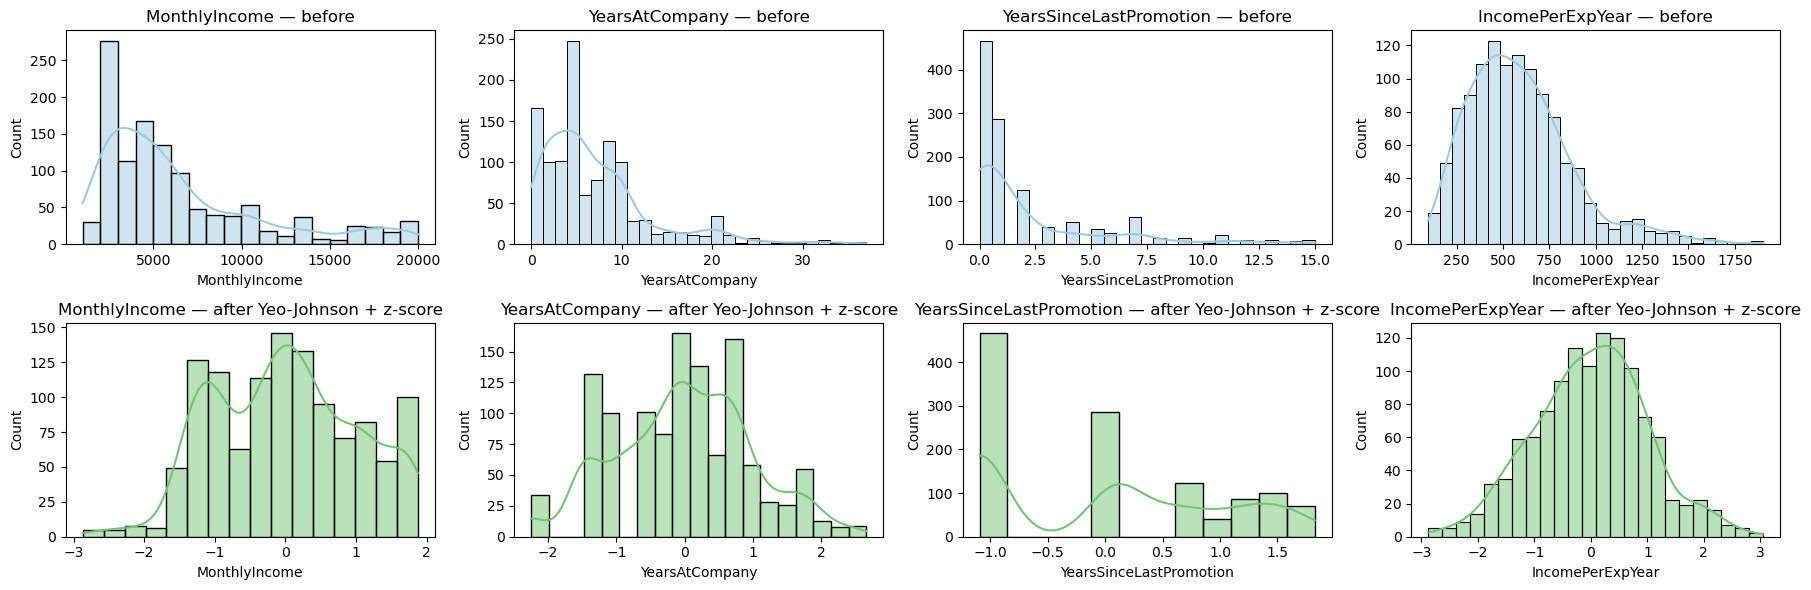

In [24]:
# ---- Inspect what each stage does, fitted on the training set (for illustration) ----
fe = HRFeatureEngineer().fit(X_train)
prep = make_preprocessor().fit(fe.transform(X_train))
Z = prep.transform(fe.transform(X_train))
print(f"After encoding + scaling : {Z.shape[1]} columns")

# Skewness before vs after Yeo-Johnson
cont_present = [c for c in CONT_COLS if c in fe.transform(X_train).columns]
before = fe.transform(X_train)[cont_present].skew()
after = Z[cont_present].skew()
sk = pd.DataFrame({"skew_before": before, "skew_after_YJ": after, "lambda": prep.named_transformers_["cont"].lambdas_},
                  index=cont_present).sort_values("skew_before", key=abs, ascending=False)
display(sk.head(15))
print(f"Mean |skew|: {before.abs().mean():.2f}  ->  {after.abs().mean():.2f}")

fig, axes = plt.subplots(2, 4, figsize=(18, 6))
for j, c in enumerate(["MonthlyIncome", "YearsAtCompany", "YearsSinceLastPromotion", "IncomePerExpYear"]):
    sns.histplot(fe.transform(X_train)[c], ax=axes[0, j], color="#9ecae1", kde=True); axes[0, j].set_title(f"{c} — before")
    sns.histplot(Z[c], ax=axes[1, j], color="#74c476", kde=True);                   axes[1, j].set_title(f"{c} — after Yeo-Johnson + z-score")
plt.tight_layout(); plt.show()

In [25]:
# ---- Multicollinearity: VIF before / after, condition number ----
vif_before = vif_series(Z).sort_values(ascending=False)
print("Features with VIF > 10 BEFORE reduction:", int((vif_before > 10).sum()), "of", len(vif_before))
display(vif_before.head(12).to_frame("VIF"))

R = np.corrcoef(Z.values, rowvar=False)
print(f"Condition number of correlation matrix before: {np.linalg.cond(R + 1e-6*np.eye(len(R))):,.0f}")

red = ImbPipeline(reducer_steps("filter")).fit(Z, y_train)
Zr = red.transform(Z)
vif_after = vif_series(Zr).sort_values(ascending=False)
print(f"\nAfter correlation filter + VIF pruning: {Zr.shape[1]} features, max VIF = {vif_after.max():.2f}")
print("Dropped:", sorted(set(Z.columns) - set(Zr.columns)))
Rr = np.corrcoef(Zr.values, rowvar=False)
print(f"Condition number after: {np.linalg.cond(Rr):,.1f}")

Features with VIF > 10 BEFORE reduction: 48 of 64


,VIF
Department_Research_Development,473709.690901
Department_Sales,444815.342582
MaritalStatus_Married,388912.891201
MaritalStatus_Single,339177.199337
EducationField_Life_Sciences,338765.406622
EducationField_Medical,299908.211956
MaritalStatus_Divorced,271912.253869
JobRole_Sales_Executive,210123.096773
JobRole_Research_Scientist,179265.274708
JobRole_Laboratory_Technician,176107.357365


Condition number of correlation matrix before: 6,702,071

After correlation filter + VIF pruning: 46 features, max VIF = 6.48
Dropped: ['Age', 'Department_Research_Development', 'Department_Sales', 'EducationField_Life_Sciences', 'JobRole_Human_Resources', 'JobRole_Sales_Executive', 'LogIncomeZ_RoleLevel', 'MaritalStatus_Married', 'MonthlyIncome', 'NumCompaniesWorked', 'OT_x_Travel', 'SatisfactionGeo', 'SatisfactionMean', 'TotalWorkingYears', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager']
Condition number after: 51.1


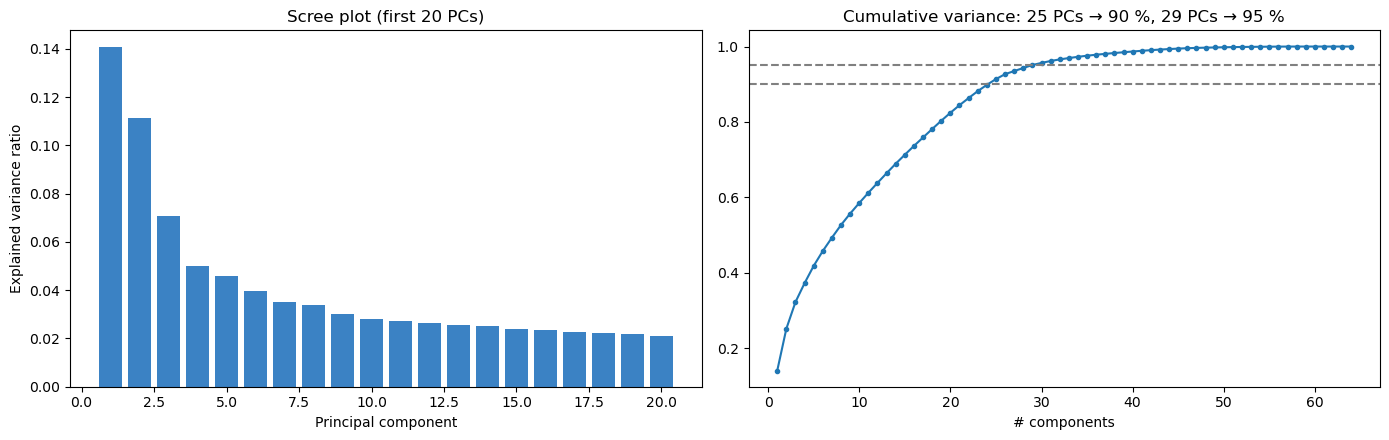

64 features need 25 components for 90% variance → information is spread out; aggressive PCA compression would blur interpretability.


In [26]:
# ---- PCA view of the feature space (for insight; the models use the original, interpretable features) ----
pca = PCA().fit(Z)
cum = np.cumsum(pca.explained_variance_ratio_)
n90, n95 = int(np.argmax(cum >= .90) + 1), int(np.argmax(cum >= .95) + 1)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].bar(range(1, 21), pca.explained_variance_ratio_[:20], color="#3b82c4"); axes[0].set_title("Scree plot (first 20 PCs)")
axes[0].set_xlabel("Principal component"); axes[0].set_ylabel("Explained variance ratio")
axes[1].plot(range(1, len(cum) + 1), cum, "o-", ms=3); axes[1].axhline(.9, ls="--", c="grey"); axes[1].axhline(.95, ls="--", c="grey")
axes[1].set_title(f"Cumulative variance: {n90} PCs → 90 %, {n95} PCs → 95 %"); axes[1].set_xlabel("# components")
plt.tight_layout(); plt.show()
print(f"{Z.shape[1]} features need {n90} components for 90% variance → information is spread out; aggressive PCA compression would blur interpretability.")

---
# 9. Model Benchmarking

## 9.1 Validation design
* **Repeated stratified 5-fold CV** on the training set (stratification preserves the 16 % rate in every fold; repetition reduces the variance of the estimate).
* `return_train_score=True` so we can measure the **train–validation gap** (over-fitting) for every model.
* Metrics: **ROC-AUC** (primary), **PR-AUC**, plus recall / precision / F1 / balanced accuracy at the model's default decision rule.

$$\text{ROC-AUC}=P\big(\hat p(x^{+})>\hat p(x^{-})\big),\qquad
\text{PR-AUC}\approx\sum_n (R_n-R_{n-1})\,P_n,\qquad
F_\beta=\frac{(1+\beta^2)\,P\,R}{\beta^2 P+R}$$

## 9.2 Imbalance handling
* **Cost-sensitive learning**: `class_weight='balanced'` $\Rightarrow w_c = \dfrac{N}{2N_c}$ (or `scale_pos_weight` $=N_0/N_1$ for boosting).
* **SMOTE** (synthetic minority over-sampling): $x_{new}=x_i+\lambda\,(x_{nn}-x_i),\ \lambda\sim U(0,1)$ – applied **only to training folds** via an imbalanced-learn pipeline. We compare both.

In [27]:
CV_SCREEN = RepeatedStratifiedKFold(n_splits=5, n_repeats=1 if QUICK_RUN else 2, random_state=RANDOM_STATE)
CV_VALID  = RepeatedStratifiedKFold(n_splits=5, n_repeats=1 if QUICK_RUN else 2, random_state=RANDOM_STATE + 1)  # different folds
SCORING = {"roc_auc": "roc_auc", "pr_auc": "average_precision", "recall": "recall", "precision": "precision",
           "f1": "f1", "bal_acc": "balanced_accuracy"}

def get_models():
    return {
        "LogReg_L2": LogisticRegression(C=0.1, class_weight="balanced", max_iter=5000, random_state=RANDOM_STATE),
        "LogReg_L1": LogisticRegression(penalty="l1", solver="liblinear", C=0.1, class_weight="balanced", random_state=RANDOM_STATE),
        "SVC_RBF": SVC(C=1.0, kernel="rbf", gamma="scale", class_weight="balanced", random_state=RANDOM_STATE),
        "RandomForest": RandomForestClassifier(n_estimators=300, min_samples_leaf=5, max_features="sqrt",
                                               class_weight="balanced_subsample", n_jobs=1, random_state=RANDOM_STATE),
        "ExtraTrees": ExtraTreesClassifier(n_estimators=300, min_samples_leaf=5, max_features="sqrt",
                                           class_weight="balanced_subsample", n_jobs=1, random_state=RANDOM_STATE),
        "HistGB": HistGradientBoostingClassifier(learning_rate=0.05, max_depth=3, max_iter=150, l2_regularization=1.0,
                                                 class_weight="balanced", early_stopping=False, random_state=RANDOM_STATE),
        "XGBoost": XGBClassifier(n_estimators=200, learning_rate=0.05, max_depth=3, subsample=0.8, colsample_bytree=0.8,
                                 scale_pos_weight=SPW, eval_metric="logloss", tree_method="hist", n_jobs=1,
                                 verbosity=0, random_state=RANDOM_STATE),
        "LightGBM": LGBMClassifier(n_estimators=200, learning_rate=0.05, num_leaves=8, min_child_samples=20, subsample=0.8,
                                   subsample_freq=1, colsample_bytree=0.8, scale_pos_weight=SPW, n_jobs=1, verbose=-1,
                                   random_state=RANDOM_STATE),
    }

def make_pipeline(model, featureset="full", engineer=True, sampler=None):
    """fe -> preprocessing -> reducer -> (sampler) -> classifier. Every step is fitted on training folds only."""
    steps = [("fe", HRFeatureEngineer(add_features=engineer)),
             ("prep", make_preprocessor())] + reducer_steps(featureset)
    if sampler is not None:
        steps.append(("sampler", sampler))
    steps.append(("clf", clone(model)))
    return ImbPipeline(steps)

def evaluate(pipe, label, cv=CV_SCREEN, extra=None):
    t0 = time.time()
    res = cross_validate(pipe, X_train, y_train, cv=cv, scoring=SCORING, return_train_score=True, n_jobs=1, error_score="raise")
    row = dict(extra or {}, name=label)
    for m in SCORING:
        row[f"cv_{m}"] = res[f"test_{m}"].mean()
        row[f"train_{m}"] = res[f"train_{m}"].mean()
    row["cv_auc_std"] = res["test_roc_auc"].std()
    row["auc_gap"] = row["train_roc_auc"] - row["cv_roc_auc"]
    row["seconds"] = time.time() - t0
    return row

# --- sanity: the full pipeline runs end-to-end and the dummy baseline sits at chance level ---
dummy = evaluate(ImbPipeline([("fe", HRFeatureEngineer()), ("prep", make_preprocessor()),
                              ("clf", DummyClassifier(strategy="prior"))]), "Dummy (prior)")
print({k: round(v, 3) for k, v in dummy.items() if k in ("cv_roc_auc", "cv_pr_auc", "cv_recall")})

{'cv_roc_auc': np.float64(0.5), 'cv_pr_auc': np.float64(0.162), 'cv_recall': np.float64(0.0)}


## 9.3 Ablation A does feature engineering actually help?
Same models, same folds: *raw encoded columns only* vs. *engineered features*.

,model,features,cv_roc_auc,cv_auc_std,cv_pr_auc,cv_recall,auc_gap
0,LogReg_L2,raw,0.838205,0.025437,0.648493,0.747368,0.043232
1,LogReg_L2,engineered,0.842827,0.028667,0.647171,0.752632,0.051562
2,RandomForest,raw,0.799300,0.027250,0.548237,0.360526,0.194461
3,RandomForest,engineered,0.814322,0.032245,0.590155,0.397368,0.181627
4,LightGBM,raw,0.815072,0.031809,0.605327,0.563158,0.183613
5,LightGBM,engineered,0.817346,0.028847,0.602415,0.571053,0.182258


features,engineered,raw,Δ AUC (engineered − raw)
model,,,
LightGBM,0.817346,0.815072,0.002274
LogReg_L2,0.842827,0.838205,0.004622
RandomForest,0.814322,0.799300,0.015022


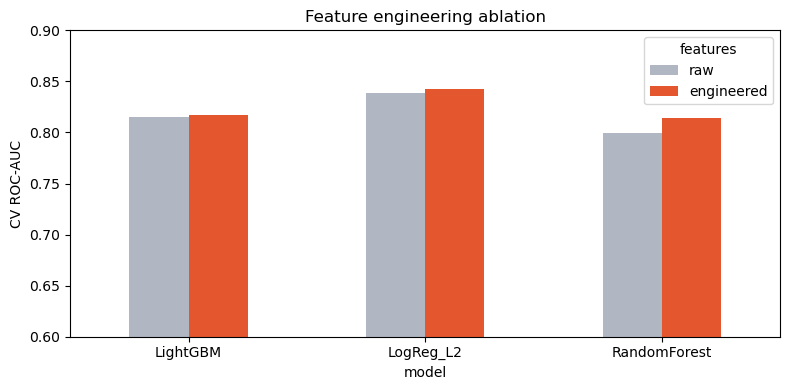

Engineered features change CV ROC-AUC by +0.002 … +0.015 across the three algorithms; typical fold-to-fold std is 0.029.
→ The gain is within fold-to-fold noise: on this clean, small dataset the raw columns already carry most of the signal. We keep the engineered set because it never hurts materially and adds business-meaningful, interpretable levers (peer-relative pay, stagnation, satisfaction profile).


In [28]:
abl_models = {k: v for k, v in get_models().items() if k in ("LogReg_L2", "RandomForest", "LightGBM")}
abl = []
for name, m in abl_models.items():
    abl.append(evaluate(make_pipeline(m, "full", engineer=False), f"{name} | raw features", extra={"model": name, "features": "raw"}))
    abl.append(evaluate(make_pipeline(m, "full", engineer=True),  f"{name} | engineered",  extra={"model": name, "features": "engineered"}))
abl = pd.DataFrame(abl)
display(abl[["model", "features", "cv_roc_auc", "cv_auc_std", "cv_pr_auc", "cv_recall", "auc_gap"]])

piv = abl.pivot(index="model", columns="features", values="cv_roc_auc")
piv["Δ AUC (engineered − raw)"] = piv["engineered"] - piv["raw"]
display(piv)
ax = piv[["raw", "engineered"]].plot.bar(figsize=(8, 4), color=["#b0b7c3", "#e4572e"], rot=0)
ax.set_ylim(0.6, 0.9); ax.set_ylabel("CV ROC-AUC"); ax.set_title("Feature engineering ablation"); plt.tight_layout(); plt.show()

d = piv["Δ AUC (engineered − raw)"]; noise = abl.cv_auc_std.mean()
print(f"Engineered features change CV ROC-AUC by {d.min():+.3f} … {d.max():+.3f} across the three algorithms; typical fold-to-fold std is {noise:.3f}.")
if d.abs().max() < noise:
    print("→ The gain is within fold-to-fold noise: on this clean, small dataset the raw columns already carry most of the signal. "
          "We keep the engineered set because it never hurts materially and adds business-meaningful, interpretable levers (peer-relative pay, stagnation, satisfaction profile).")
else:
    print("→ At least one algorithm benefits by more than the fold-to-fold noise.")

## 9.4 Ablation B — full benchmark: 8 algorithms × 3 feature sets
`full` = all engineered features · `filter` = + correlation/VIF pruning · `filter_l1` = + LASSO selection.

In [29]:
bench = [dummy | {"model": "Dummy", "featureset": "-"}]
models = get_models()
for fs in ["full", "filter", "filter_l1"]:
    for name, m in models.items():
        r = evaluate(make_pipeline(m, fs), f"{name} | {fs}", extra={"model": name, "featureset": fs})
        bench.append(r)
        print(f"{name:13s} {fs:10s} AUC={r['cv_roc_auc']:.3f}±{r['cv_auc_std']:.3f}  PR={r['cv_pr_auc']:.3f}  gap={r['auc_gap']:+.3f}  ({r['seconds']:.0f}s)")
bench = pd.DataFrame(bench)

LogReg_L2     full       AUC=0.843±0.029  PR=0.647  gap=+0.052  (8s)
LogReg_L1     full       AUC=0.832±0.029  PR=0.641  gap=+0.042  (7s)
SVC_RBF       full       AUC=0.818±0.036  PR=0.606  gap=+0.175  (11s)
RandomForest  full       AUC=0.814±0.032  PR=0.590  gap=+0.182  (29s)
ExtraTrees    full       AUC=0.822±0.032  PR=0.591  gap=+0.177  (19s)


  File "C:\Users\SKYTECH\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "C:\Users\SKYTECH\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\SKYTECH\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
                        pass_fds, cwd, env,
                        ^^^^^^^^^^^^^^^^^^^
    ...<5 lines>...
                        gid, gids, uid, umask,
                        ^^^^^^^^^^^^^^^^^^^^^^
                        start_new_session, process_group)
                        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\SKYTECH\anaconda3\Lib\sub

HistGB        full       AUC=0.803±0.025  PR=0.586  gap=+0.187  (13s)
XGBoost       full       AUC=0.814±0.022  PR=0.604  gap=+0.183  (10s)
LightGBM      full       AUC=0.817±0.029  PR=0.602  gap=+0.182  (9s)
LogReg_L2     filter     AUC=0.839±0.031  PR=0.641  gap=+0.048  (8s)
LogReg_L1     filter     AUC=0.826±0.031  PR=0.610  gap=+0.044  (9s)
SVC_RBF       filter     AUC=0.815±0.039  PR=0.588  gap=+0.181  (12s)
RandomForest  filter     AUC=0.810±0.036  PR=0.580  gap=+0.187  (30s)
ExtraTrees    filter     AUC=0.818±0.035  PR=0.576  gap=+0.180  (20s)
HistGB        filter     AUC=0.805±0.024  PR=0.583  gap=+0.181  (13s)
XGBoost       filter     AUC=0.820±0.029  PR=0.604  gap=+0.176  (11s)
LightGBM      filter     AUC=0.817±0.037  PR=0.604  gap=+0.182  (9s)
LogReg_L2     filter_l1  AUC=0.823±0.035  PR=0.600  gap=+0.044  (8s)
LogReg_L1     filter_l1  AUC=0.821±0.033  PR=0.599  gap=+0.044  (8s)
SVC_RBF       filter_l1  AUC=0.798±0.042  PR=0.552  gap=+0.181  (11s)
RandomForest  filter_l1  A

LogReg_L1     full       AUC=0.832±0.029  PR=0.641  gap=+0.042  (2s)


SVC_RBF       full       AUC=0.818±0.036  PR=0.606  gap=+0.175  (3s)


RandomForest  full       AUC=0.814±0.032  PR=0.590  gap=+0.182  (8s)


... (16 outputs left out)

ExtraTrees    filter_l1  AUC=0.805±0.039  PR=0.564  gap=+0.188  (6s)


HistGB        filter_l1  AUC=0.806±0.031  PR=0.577  gap=+0.172  (3s)


XGBoost       filter_l1  AUC=0.805±0.040  PR=0.575  gap=+0.186  (3s)


LightGBM      filter_l1  AUC=0.802±0.041  PR=0.571  gap=+0.194  (3s)


,model,featureset,cv_roc_auc,cv_auc_std,cv_pr_auc,cv_recall,cv_precision,cv_f1,cv_bal_acc,train_roc_auc,auc_gap
0,LogReg_L2,full,0.842827,0.028667,0.647171,0.752632,0.405548,0.526357,0.770072,0.894389,0.051562
1,LogReg_L2,filter,0.839453,0.031369,0.641482,0.742105,0.405967,0.523921,0.766075,0.887831,0.048378
2,LogReg_L1,full,0.831687,0.029036,0.640614,0.763158,0.389076,0.514208,0.765434,0.873964,0.042277
3,LogReg_L1,filter,0.826467,0.030506,0.610492,0.750000,0.385824,0.508514,0.759126,0.870924,0.044456
4,LogReg_L2,filter_l1,0.823040,0.034806,0.600370,0.728947,0.402825,0.518065,0.760009,0.866559,0.043519
5,ExtraTrees,full,0.821861,0.032102,0.591413,0.526316,0.542032,0.528010,0.719540,0.998440,0.176579
6,LogReg_L1,filter_l1,0.821206,0.033287,0.599386,0.750000,0.383612,0.506618,0.758106,0.864850,0.043643
7,XGBoost,filter,0.820046,0.028852,0.603806,0.586842,0.542673,0.560304,0.744731,0.995775,0.175729
8,SVC_RBF,full,0.817879,0.036073,0.606363,0.592105,0.514578,0.549161,0.741796,0.992970,0.175091
9,ExtraTrees,filter,0.817519,0.034885,0.575837,0.542105,0.537001,0.533006,0.724132,0.997240,0.179721


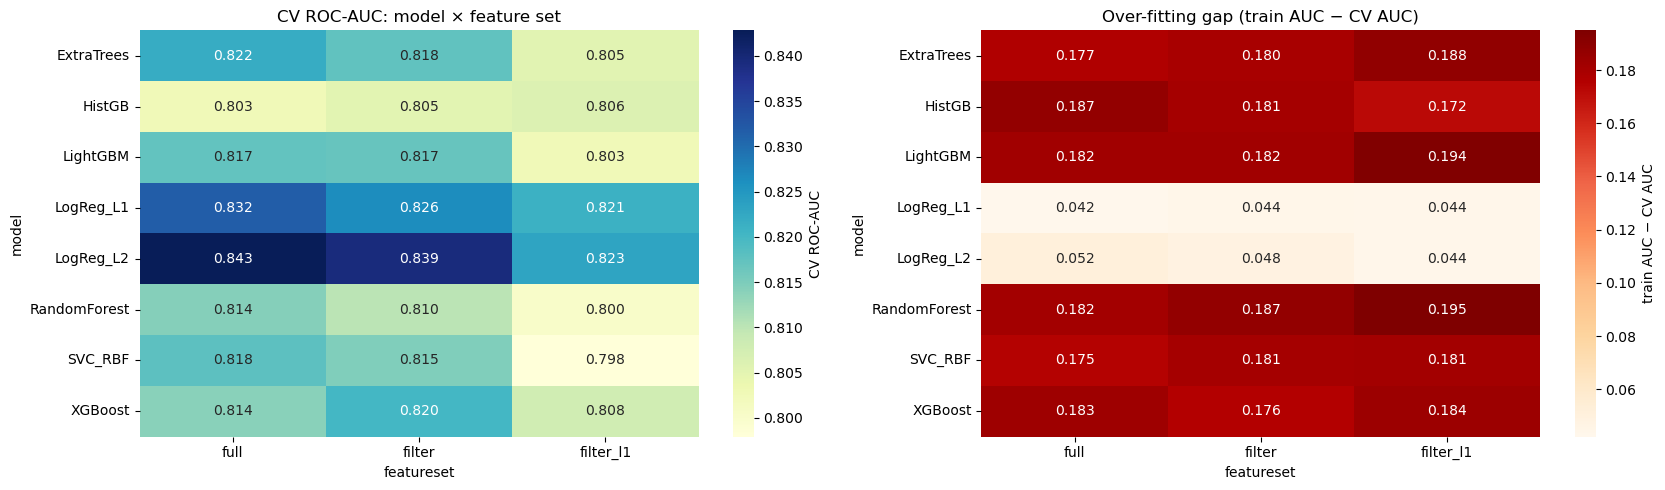

Mean CV ROC-AUC by feature set : {'filter': 0.8188, 'filter_l1': 0.808, 'full': 0.8203}
Mean train–CV AUC gap by family: {'linear': 0.046, 'non-linear': 0.183}
→ Feature reduction mainly buys stability/interpretability (lower collinearity); check above whether it also moved accuracy. Flexible models reach near-perfect training AUC but a much lower CV AUC – the signature of variance (over-fitting) on a small sample.


In [30]:
cols = ["model", "featureset", "cv_roc_auc", "cv_auc_std", "cv_pr_auc", "cv_recall", "cv_precision", "cv_f1", "cv_bal_acc", "train_roc_auc", "auc_gap"]
leader = bench.sort_values("cv_roc_auc", ascending=False).reset_index(drop=True)
display(leader[cols].head(15))

fig, axes = plt.subplots(1, 2, figsize=(17, 5))
pv = bench[bench.model != "Dummy"].pivot(index="model", columns="featureset", values="cv_roc_auc")[["full", "filter", "filter_l1"]]
sns.heatmap(pv, annot=True, fmt=".3f", cmap="YlGnBu", ax=axes[0], cbar_kws={"label": "CV ROC-AUC"})
axes[0].set_title("CV ROC-AUC: model × feature set")
pv2 = bench[bench.model != "Dummy"].pivot(index="model", columns="featureset", values="auc_gap")[["full", "filter", "filter_l1"]]
sns.heatmap(pv2, annot=True, fmt=".3f", cmap="OrRd", ax=axes[1], cbar_kws={"label": "train AUC − CV AUC"})
axes[1].set_title("Over-fitting gap (train AUC − CV AUC)")
plt.tight_layout(); plt.show()

b = bench[bench.model != "Dummy"]
print("Mean CV ROC-AUC by feature set :", b.groupby("featureset").cv_roc_auc.mean().round(4).to_dict())
print("Mean train–CV AUC gap by family:", b.assign(family=np.where(b.model.str.startswith("LogReg"), "linear", "non-linear")).groupby("family").auc_gap.mean().round(3).to_dict())
print("→ Feature reduction mainly buys stability/interpretability (lower collinearity); check above whether it also moved accuracy. "
      "Flexible models reach near-perfect training AUC but a much lower CV AUC – the signature of variance (over-fitting) on a small sample.")

## 9.5 Ablation C — imbalance strategy (none vs. class weights vs. SMOTE)
Run for one linear and one tree model, on the `filter` feature set.

In [31]:
imb_rows = []
for name in ["LogReg_L2", "RandomForest"]:
    base = get_models()[name]
    nw = clone(base).set_params(class_weight=None)
    for label, mdl, smp in [("none", nw, None), ("class_weight", base, None),
                            ("SMOTE", nw, SMOTE(k_neighbors=5, random_state=RANDOM_STATE))]:
        r = evaluate(make_pipeline(mdl, "filter", sampler=smp), f"{name}|{label}", extra={"model": name, "strategy": label})
        imb_rows.append(r)
imb = pd.DataFrame(imb_rows)
display(imb[["model", "strategy", "cv_roc_auc", "cv_pr_auc", "cv_recall", "cv_precision", "cv_f1", "auc_gap"]])
for m_ in imb.model.unique():
    t = imb[imb.model == m_].set_index("strategy")
    print(f"{m_}: CV AUC  none={t.loc['none','cv_roc_auc']:.3f} | class_weight={t.loc['class_weight','cv_roc_auc']:.3f} | SMOTE={t.loc['SMOTE','cv_roc_auc']:.3f}")
print("Note: recall/precision/F1 above use each model's *default* cut-off, so they move a lot with resampling/weights;")
print("ROC-AUC/PR-AUC measure ranking quality independent of the cut-off, and we tune the cut-off explicitly in Section 13.")

,model,strategy,cv_roc_auc,cv_pr_auc,cv_recall,cv_precision,cv_f1,auc_gap
0,LogReg_L2,none,0.844356,0.659689,0.373684,0.793995,0.502970,0.035369
1,LogReg_L2,class_weight,0.839453,0.641482,0.742105,0.405967,0.523921,0.048378
2,LogReg_L2,SMOTE,0.819528,0.593766,0.718421,0.389398,0.504605,0.050510
3,RandomForest,none,0.812364,0.584834,0.136842,0.978409,0.234146,0.181135
4,RandomForest,class_weight,0.810133,0.580077,0.381579,0.646781,0.474669,0.187437
5,RandomForest,SMOTE,0.791641,0.545339,0.318421,0.661159,0.427326,0.204874


LogReg_L2: CV AUC  none=0.844 | class_weight=0.839 | SMOTE=0.820
RandomForest: CV AUC  none=0.812 | class_weight=0.810 | SMOTE=0.792
Note: recall/precision/F1 above use each model's *default* cut-off, so they move a lot with resampling/weights;
ROC-AUC/PR-AUC measure ranking quality independent of the cut-off, and we tune the cut-off explicitly in Section 13.


---
# 10. Hyper-parameter Tuning & Nested Cross-Validation

**Strategy**
1. From the benchmark, take the best feature set *per algorithm* and keep the **top-3 algorithms**.
2. Tune each with a **randomised search** (5-fold CV, ROC-AUC) over regularisation/complexity parameters – regularisation is our main weapon against over-fitting on a small ($n\approx1{,}176$) training set.
3. Because the search's best score is **optimistically biased** (we picked the maximum of many noisy estimates), re-score every tuned model on *fresh CV folds* (different seed).
4. Choose the final model with the **one-standard-error rule**: among models within one standard error of the best AUC, prefer the *simplest* (lower variance, easier to explain).
5. Estimate the *whole procedure's* generalisation honestly with **nested CV** (outer loop evaluates; inner loop tunes).

In [32]:
# ---- search spaces (complexity / regularisation parameters) ----
PARAM_SPACES = {
    "LogReg_L2": {"clf__C": loguniform(1e-3, 1e2)},
    "LogReg_L1": {"clf__C": loguniform(1e-3, 1e2)},
    "SVC_RBF":   {"clf__C": loguniform(1e-2, 1e2), "clf__gamma": loguniform(1e-4, 1e-1)},
    "RandomForest": {"clf__n_estimators": randint(200, 500), "clf__max_depth": [3, 4, 5, 6, 8, 12],
                     "clf__min_samples_leaf": randint(3, 25), "clf__max_features": ["sqrt", "log2", 0.3, 0.5],
                     "clf__class_weight": ["balanced", "balanced_subsample"]},
    "ExtraTrees": {"clf__n_estimators": randint(200, 500), "clf__max_depth": [3, 4, 5, 6, 8, 12],
                   "clf__min_samples_leaf": randint(3, 25), "clf__max_features": ["sqrt", "log2", 0.3, 0.5]},
    "HistGB": {"clf__learning_rate": loguniform(0.01, 0.2), "clf__max_iter": randint(60, 300), "clf__max_depth": [2, 3, 4],
               "clf__max_leaf_nodes": randint(4, 20), "clf__min_samples_leaf": randint(15, 60),
               "clf__l2_regularization": loguniform(1e-2, 20)},
    "XGBoost": {"clf__n_estimators": randint(80, 400), "clf__learning_rate": loguniform(0.01, 0.2), "clf__max_depth": randint(2, 5),
                "clf__min_child_weight": randint(1, 12), "clf__subsample": uniform(0.6, 0.4), "clf__colsample_bytree": uniform(0.5, 0.5),
                "clf__reg_lambda": loguniform(0.5, 30), "clf__gamma": uniform(0, 2)},
    "LightGBM": {"clf__n_estimators": randint(80, 400), "clf__learning_rate": loguniform(0.01, 0.2), "clf__num_leaves": randint(4, 20),
                 "clf__min_child_samples": randint(15, 60), "clf__subsample": uniform(0.6, 0.4), "clf__colsample_bytree": uniform(0.5, 0.5),
                 "clf__reg_lambda": loguniform(0.5, 30)},
}
COMPLEXITY_RANK = {"LogReg_L2": 1, "LogReg_L1": 1, "SVC_RBF": 2, "RandomForest": 3, "ExtraTrees": 3, "HistGB": 4, "XGBoost": 4, "LightGBM": 4}

# ---- choose the top-3 algorithms (best feature set each) ----
cand = (bench[bench.model != "Dummy"].sort_values("cv_roc_auc", ascending=False)
        .groupby("model", as_index=False).first().sort_values("cv_roc_auc", ascending=False).head(3))
display(cand[["model", "featureset", "cv_roc_auc", "cv_pr_auc", "auc_gap"]])

N_ITER = 8 if QUICK_RUN else 30
CV_TUNE = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
searches = {}
for _, r in cand.iterrows():
    t0 = time.time()
    rs = RandomizedSearchCV(make_pipeline(get_models()[r.model], r.featureset), PARAM_SPACES[r.model], n_iter=N_ITER,
                            scoring="roc_auc", cv=CV_TUNE, random_state=RANDOM_STATE, n_jobs=1, refit=True,
                            return_train_score=True, error_score="raise")
    rs.fit(X_train, y_train)
    searches[r.model] = (rs, r.featureset)
    print(f"{r.model:13s} [{r.featureset}]  best inner-CV AUC = {rs.best_score_:.4f}   ({time.time() - t0:.0f}s)")
    print("    best params:", {k.replace('clf__', ''): (round(v, 4) if isinstance(v, float) else v) for k, v in rs.best_params_.items()})

,model,featureset,cv_roc_auc,cv_pr_auc,auc_gap
4,LogReg_L2,full,0.842827,0.647171,0.051562
3,LogReg_L1,full,0.831687,0.640614,0.042277
0,ExtraTrees,full,0.821861,0.591413,0.176579


LogReg_L2     [full]  best inner-CV AUC = 0.8448   (80s)
    best params: {'C': np.float64(0.9847)}
LogReg_L1     [full]  best inner-CV AUC = 0.8421   (111s)
    best params: {'C': np.float64(1.1462)}
ExtraTrees    [full]  best inner-CV AUC = 0.8213   (262s)
    best params: {'max_depth': 8, 'max_features': 'sqrt', 'min_samples_leaf': 9, 'n_estimators': 321}


LogReg_L1     [full]  best inner-CV AUC = 0.8421   (35s)
    best params: {'C': np.float64(1.1462)}


ExtraTrees    [full]  best inner-CV AUC = 0.8213   (77s)
    best params: {'max_depth': 8, 'max_features': 'sqrt', 'min_samples_leaf': 9, 'n_estimators': 321}


In [33]:
# ---- re-score tuned models on FRESH folds (removes the "winner's curse" optimism) ----
tuned_rows = []
for name, (rs, fs) in searches.items():
    r = evaluate(clone(rs.best_estimator_), f"{name} | tuned", cv=CV_VALID, extra={"model": name, "featureset": fs})
    r["inner_search_auc"] = rs.best_score_
    tuned_rows.append(r)
tuned = pd.DataFrame(tuned_rows)
tuned["default_cv_auc"] = [bench[(bench.model == m) & (bench.featureset == f)].cv_roc_auc.iloc[0] for m, f in zip(tuned.model, tuned.featureset)]
display(tuned[["model", "featureset", "default_cv_auc", "inner_search_auc", "cv_roc_auc", "cv_auc_std", "cv_pr_auc", "train_roc_auc", "auc_gap"]])

# ---- one-standard-error rule ----
n_folds = CV_VALID.get_n_splits()
best_row = tuned.loc[tuned.cv_roc_auc.idxmax()]
se = best_row.cv_auc_std / np.sqrt(n_folds)
eligible = tuned[tuned.cv_roc_auc >= best_row.cv_roc_auc - se].copy()
eligible["complexity"] = eligible.model.map(COMPLEXITY_RANK)
winner = eligible.sort_values(["complexity", "cv_roc_auc"], ascending=[True, False]).iloc[0]

final_name, final_fs = winner.model, winner.featureset
final_search = searches[final_name][0]
final_pipe = clone(final_search.best_estimator_)          # un-fitted, tuned pipeline
print(f"Best AUC {best_row.cv_roc_auc:.4f} ({best_row.model}), 1-SE band = [{best_row.cv_roc_auc - se:.4f}, {best_row.cv_roc_auc:.4f}]")
print(f"Eligible: {list(eligible.model)}")
print(f"\nFINAL MODEL: {final_name}  |  feature set = {final_fs}  |  fresh-fold CV AUC = {winner.cv_roc_auc:.4f}")
final_pipe

,model,featureset,default_cv_auc,inner_search_auc,cv_roc_auc,cv_auc_std,cv_pr_auc,train_roc_auc,auc_gap
0,LogReg_L2,full,0.842827,0.844753,0.841570,0.040991,0.640101,0.905100,0.063530
1,LogReg_L1,full,0.831687,0.842057,0.840018,0.041206,0.644702,0.904696,0.064678
2,ExtraTrees,full,0.821861,0.821255,0.817040,0.040002,0.603986,0.969184,0.152144


Best AUC 0.8416 (LogReg_L2), 1-SE band = [0.8286, 0.8416]
Eligible: ['LogReg_L2', 'LogReg_L1']

✅ FINAL MODEL: LogReg_L2  |  feature set = full  |  fresh-fold CV AUC = 0.8416


Pipeline(steps=[('fe', HRFeatureEngineer()),
                ('prep',
                 ColumnTransformer(transformers=[('cont', PowerTransformer(),
                                                  <__main__.present object at 0x0000019B80969590>),
                                                 ('ord', StandardScaler(),
                                                  <__main__.present object at 0x0000019B8434B390>),
                                                 ('bin', 'passthrough',
                                                  <__main__.present object at 0x0000019B84348460>),
                                                 ('nom',
                                                  OneHotEncoder(handle_unknown='ignore',
                                                                sparse_output=False),
                                                  <__main__.present object at 0x0000019B8434A0D0>)],
                                   verbose_feature_names_out=False)),
                ('clf',
                 LogisticRegression(C=np.float64(0.9846738873614566),
                                    class_weight='balanced', max_iter=5000,
                                    random_state=42))])

In [34]:
# ---- nested CV: honest estimate of "tune + fit" generalisation for the chosen algorithm ----
inner = RandomizedSearchCV(make_pipeline(get_models()[final_name], final_fs), PARAM_SPACES[final_name],
                           n_iter=5 if QUICK_RUN else 12, scoring="roc_auc",
                           cv=StratifiedKFold(3, shuffle=True, random_state=RANDOM_STATE), random_state=RANDOM_STATE,
                           n_jobs=1, error_score="raise")
outer = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE + 7)
nested_auc = cross_val_score(inner, X_train, y_train, cv=outer, scoring="roc_auc", n_jobs=1)
nested_ap = cross_val_score(inner, X_train, y_train, cv=outer, scoring="average_precision", n_jobs=1)
print(f"Nested CV ROC-AUC : {nested_auc.mean():.4f} ± {nested_auc.std():.4f}   folds = {np.round(nested_auc, 3)}")
print(f"Nested CV PR-AUC  : {nested_ap.mean():.4f} ± {nested_ap.std():.4f}   (chance level = {y_train.mean():.3f})")
print(f"Non-nested search score was {final_search.best_score_:.4f}  ->  optimism ≈ {final_search.best_score_ - nested_auc.mean():+.4f}")

Nested CV ROC-AUC : 0.8327 ± 0.0291   folds = [0.836 0.825 0.843 0.875 0.785]
Nested CV PR-AUC  : 0.6238 ± 0.0630   (chance level = 0.162)
Non-nested search score was 0.8448  ->  optimism ≈ +0.0121


---
# 11. Under-fitting & Over-fitting Diagnostics

| Symptom | Training score | Validation score | Remedy |
|---|---|---|---|
| **Under-fitting (high bias)** | low | low (≈ train) | richer features/model, less regularisation |
| **Over-fitting (high variance)** | very high | much lower | stronger regularisation, simpler model, more data |
| **Good fit** | high | slightly lower, both stable | – |

We use five independent lines of evidence:
1. **Train-vs-CV gap** of the final model,
2. **Learning curve** (does more data still help? do the curves converge?),
3. **Validation curve** over a complexity parameter (is the chosen setting near the sweet spot?),
4. **Benchmark ladder** (Dummy → simple linear → final) to rule out under-fitting,
5. **Label-permutation test** (is performance real signal, not chance?).

In [35]:
# 11.1 Train vs validation gap for the final model (fresh folds) -----------------------------
fin = tuned[tuned.model == final_name].iloc[0]
gap_tbl = pd.DataFrame({
    "metric": ["ROC-AUC", "PR-AUC", "Balanced accuracy", "Recall (default cut-off)"],
    "train": [fin.train_roc_auc, fin.train_pr_auc, fin.train_bal_acc, fin.train_recall],
    "validation": [fin.cv_roc_auc, fin.cv_pr_auc, fin.cv_bal_acc, fin.cv_recall],
})
gap_tbl["gap"] = gap_tbl.train - gap_tbl.validation
display(gap_tbl)

if fin.train_roc_auc < 0.70 and fin.cv_roc_auc < 0.70:
    verdict = "UNDER-FITTING (both scores low)"
elif fin.auc_gap > 0.15:
    verdict = "NOTABLE OVER-FITTING (large train–validation gap) – consider stronger regularisation"
elif fin.auc_gap > 0.07:
    verdict = "MILD variance (moderate gap, validation score still strong) – acceptable, monitor"
else:
    verdict = "GOOD FIT (small gap, strong validation score)"
print("Automatic verdict ->", verdict)

,metric,train,validation,gap
0,ROC-AUC,0.905100,0.841570,0.063530
1,PR-AUC,0.722604,0.640101,0.082503
2,Balanced accuracy,0.824014,0.768470,0.055544
3,Recall (default cut-off),0.835526,0.747368,0.088158


Automatic verdict -> GOOD FIT (small gap, strong validation score)


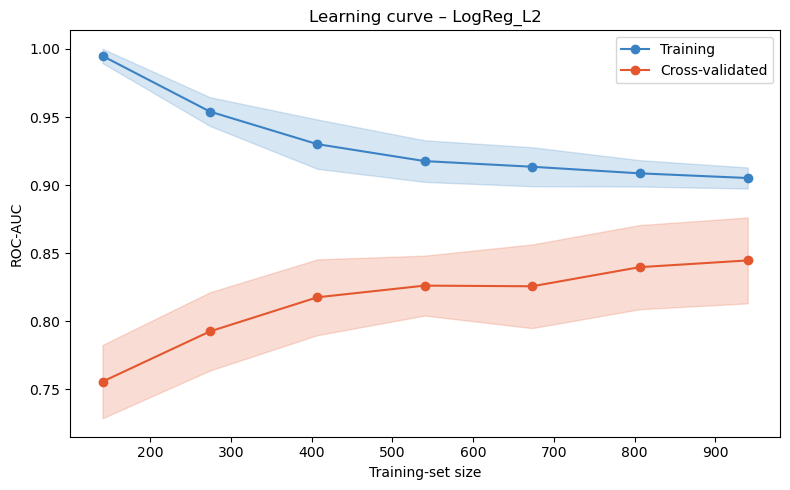

Final gap at full size: +0.061;  CV-AUC change over the last two sizes: +0.0050


In [36]:
# 11.2 Learning curve ------------------------------------------------------------------------------
sizes, tr, va = learning_curve(final_pipe, X_train, y_train, cv=StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE),
                               train_sizes=np.linspace(0.15, 1.0, 5 if QUICK_RUN else 7), scoring="roc_auc",
                               shuffle=True, random_state=RANDOM_STATE, n_jobs=1)
fig, ax = plt.subplots(figsize=(8, 5))
for arr, lab, c in [(tr, "Training", "#3b82c4"), (va, "Cross-validated", "#e4572e")]:
    ax.plot(sizes, arr.mean(1), "o-", c=c, label=lab); ax.fill_between(sizes, arr.mean(1) - arr.std(1), arr.mean(1) + arr.std(1), alpha=.2, color=c)
ax.set_xlabel("Training-set size"); ax.set_ylabel("ROC-AUC"); ax.set_title(f"Learning curve – {final_name}"); ax.legend()
plt.tight_layout(); plt.show()
print(f"Final gap at full size: {tr.mean(1)[-1] - va.mean(1)[-1]:+.3f};  CV-AUC change over the last two sizes: {va.mean(1)[-1] - va.mean(1)[-2]:+.4f}")

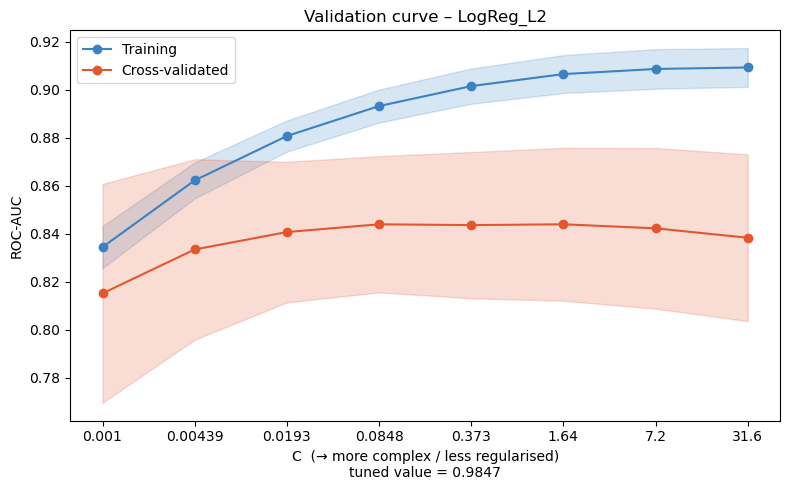

Left of the peak = under-fitting (both curves low); far right = over-fitting (train ↑, validation ↓).


In [37]:
# 11.3 Validation curve over the main complexity parameter -----------------------------------------------
COMPLEXITY = {
    "LogReg_L2": ("clf__C", np.logspace(-3, 1.5, 8)), "LogReg_L1": ("clf__C", np.logspace(-3, 1.5, 8)),
    "SVC_RBF": ("clf__C", np.logspace(-2, 2, 8)),
    "RandomForest": ("clf__max_depth", [1, 2, 3, 4, 6, 8, 12, 20]), "ExtraTrees": ("clf__max_depth", [1, 2, 3, 4, 6, 8, 12, 20]),
    "HistGB": ("clf__max_iter", [10, 25, 50, 100, 200, 400]),
    "XGBoost": ("clf__n_estimators", [10, 25, 50, 100, 200, 400]), "LightGBM": ("clf__n_estimators", [10, 25, 50, 100, 200, 400]),
}
pname, prange = COMPLEXITY[final_name]
tr_s, va_s = validation_curve(final_pipe, X_train, y_train, param_name=pname, param_range=prange,
                              cv=StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE), scoring="roc_auc", n_jobs=1)
fig, ax = plt.subplots(figsize=(8, 5))
xs = np.arange(len(prange))
for arr, lab, c in [(tr_s, "Training", "#3b82c4"), (va_s, "Cross-validated", "#e4572e")]:
    ax.plot(xs, arr.mean(1), "o-", c=c, label=lab); ax.fill_between(xs, arr.mean(1) - arr.std(1), arr.mean(1) + arr.std(1), alpha=.2, color=c)
ax.set_xticks(xs); ax.set_xticklabels([f"{v:.3g}" for v in prange]); ax.set_xlabel(pname.replace("clf__", "") + "  (→ more complex / less regularised)")
ax.set_ylabel("ROC-AUC"); ax.set_title(f"Validation curve – {final_name}"); ax.legend()
cur = final_pipe.get_params()[pname]
ax.set_xlabel(ax.get_xlabel() + f"\ntuned value = {cur if not isinstance(cur, float) else round(cur, 4)}")
plt.tight_layout(); plt.show()
print("Left of the peak = under-fitting (both curves low); far right = over-fitting (train ↑, validation ↓).")

,model,cv_roc_auc,cv_pr_auc
0,Dummy (prior),0.500000,0.161565
1,"Simple logistic regression, raw features",0.835802,0.651503
2,"FINAL: LogReg_L2 (tuned, engineered)",0.841570,0.640101


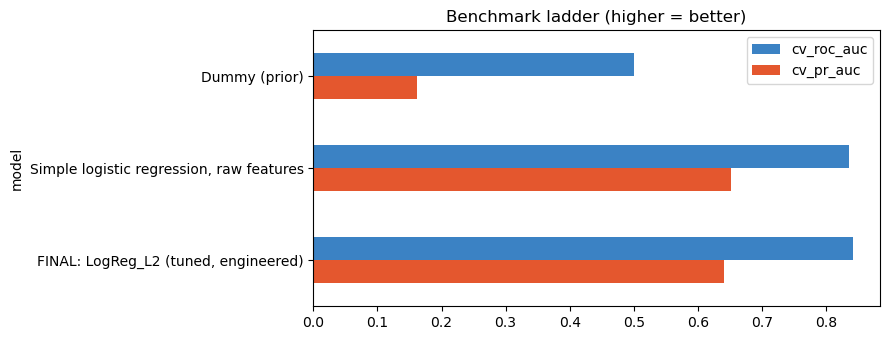

In [38]:
# 11.4 Benchmark ladder: rules out under-fitting ------------------------------------------------------------
simple_lr = evaluate(make_pipeline(get_models()["LogReg_L2"], "filter", engineer=False), "Simple LR (raw features)", cv=CV_VALID)
ladder = pd.DataFrame([
    {"model": "Dummy (prior)", "cv_roc_auc": dummy["cv_roc_auc"], "cv_pr_auc": dummy["cv_pr_auc"]},
    {"model": "Simple logistic regression, raw features", "cv_roc_auc": simple_lr["cv_roc_auc"], "cv_pr_auc": simple_lr["cv_pr_auc"]},
    {"model": f"FINAL: {final_name} (tuned, engineered)", "cv_roc_auc": fin.cv_roc_auc, "cv_pr_auc": fin.cv_pr_auc},
])
display(ladder)
ax = ladder.set_index("model")[["cv_roc_auc", "cv_pr_auc"]].plot.barh(figsize=(9, 3.5), color=["#3b82c4", "#e4572e"])
ax.set_title("Benchmark ladder (higher = better)"); ax.invert_yaxis(); plt.tight_layout(); plt.show()

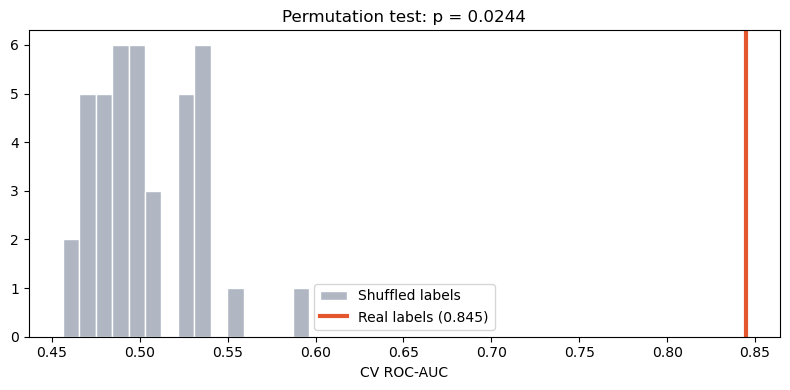

Real AUC 0.845  vs. shuffled-label AUC 0.503 ± 0.029  ->  p-value = 0.0244


In [39]:
# 11.5 Label-permutation test: is the signal real? ----------------------------------------------------------------
n_perm = 8 if QUICK_RUN else 40
score, perm_scores, pval = permutation_test_score(final_pipe, X_train, y_train, scoring="roc_auc",
                                                  cv=StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE),
                                                  n_permutations=n_perm, random_state=RANDOM_STATE, n_jobs=1)
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(perm_scores, bins=15, color="#b0b7c3", edgecolor="white", label="Shuffled labels")
ax.axvline(score, c="#e4572e", lw=3, label=f"Real labels ({score:.3f})"); ax.legend(); ax.set_xlabel("CV ROC-AUC")
ax.set_title(f"Permutation test: p = {pval:.4f}")
plt.tight_layout(); plt.show()
print(f"Real AUC {score:.3f}  vs. shuffled-label AUC {perm_scores.mean():.3f} ± {perm_scores.std():.3f}  ->  p-value = {pval:.4f}")

---
# 12. Data-Leakage Audit

*Data leakage* = information from outside the training fold (the test set, the future, or the target itself) sneaking into model building and inflating scores. We audit **seven** potential leak paths.

| # | Leak path | Control in this notebook |
|---|---|---|
| 1 | Target (or a proxy) among the features | Programmatic check + single-feature AUC scan (below) |
| 2 | Row identifiers | `EmployeeNumber` dropped (4.3) |
| 3 | Train/test contamination | Stratified split **before** EDA; index & duplicate-row checks (Section 5) |
| 4 | Preprocessing statistics (means, YJ-λ, one-hot vocab) fitted on all data | All inside `Pipeline` → refit per fold |
| 5 | Feature-engineering statistics (peer medians, shrunk z-scores) | Learned in `HRFeatureEngineer.fit()`, label-free |
| 6 | Feature **selection** using the full dataset | Correlation/VIF/LASSO filters are pipeline steps; demo below |
| 7 | Resampling (SMOTE) before splitting | Sampler is a pipeline step (only touches training folds) |

In [40]:
# 12.1 Structural checks ---------------------------------------------------------------------------
assert "Attrition" not in X_train.columns and "Attrition" not in X_test.columns
assert "EmployeeNumber" not in X_train.columns
print("✔ Target and ID are not among the features")
print("✔ Pipeline steps (all fitted per fold):", [n for n, _ in final_pipe.steps])
assert set(X_train.index).isdisjoint(X_test.index); print("✔ Train/test indices are disjoint")
print(f"✔ Exact duplicate feature-rows across train/test: {len(overlap)}")

# 12.2 Single-feature 'too good to be true' scan (on engineered train features) -----------------------
scan = rank_tbl.dropna(subset=["single_AUC"]).sort_values("single_AUC", ascending=False)[["feature", "single_AUC", "IV"]].head(8)
display(scan)
assert scan.single_AUC.max() < 0.85, "A single feature this predictive would be suspicious!"
print(f"✔ Best single-feature AUC = {scan.single_AUC.max():.3f} (< 0.85): no single feature behaves like a proxy for the target.")
print(f"ℹ Highest IV = {rank_tbl.feature.iloc[0]} ({rank_tbl.IV.iloc[0]:.3f}); IV is inflated by many-level categoricals and sparse bins (only {int(y_train.sum())} positives). "
      f"The more robust yardsticks – single-feature AUC ≤ {scan.single_AUC.max():.2f} and Cramér's V ≤ {screen.effect_size.max():.2f} – show only moderate individual signal, as expected for genuine HR drivers.")

✔ Target and ID are not among the features
✔ Pipeline steps (all fitted per fold): ['fe', 'prep', 'clf']
✔ Train/test indices are disjoint
✔ Exact duplicate feature-rows across train/test: 0


,feature,single_AUC,IV
4,JobHopIndex,0.676975,0.396563
1,TotalWorkingYears,0.661557,0.428414
2,YearsAtCompany,0.659856,0.413322
9,SatisfactionGeo,0.659251,0.338321
3,MonthlyIncome,0.657772,0.403914
8,Age,0.652437,0.338958
13,SatisfactionMean,0.651164,0.307976
10,YearsWithCurrManager,0.650315,0.332669


✔ Best single-feature AUC = 0.677 (< 0.85): no single feature behaves like a proxy for the target.
ℹ Highest IV = JobRole (0.558); IV is inflated by many-level categoricals and sparse bins (only 190 positives). The more robust yardsticks – single-feature AUC ≤ 0.68 and Cramér's V ≤ 0.32 – show only moderate individual signal, as expected for genuine HR drivers.


In [41]:
# 12.3 Demonstration: WHY selecting features outside CV is leakage -------------------------------------------
# Pure noise features cannot predict anything. If we select the "best 15 of 300" using ALL labels first
# and cross-validate afterwards, the CV score looks better than chance -- a leak. Doing it inside a pipeline fixes it.
rng = np.random.default_rng(RANDOM_STATE)
noise = rng.normal(size=(len(y_train), 300))
cv5 = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)

leaky_X = SelectKBest(f_classif, k=15).fit_transform(noise, y_train)                       # selection sees all labels
auc_leaky = cross_val_score(LogisticRegression(max_iter=1000), leaky_X, y_train, cv=cv5, scoring="roc_auc").mean()
right = ImbPipeline([("sel", SelectKBest(f_classif, k=15)), ("lr", LogisticRegression(max_iter=1000))])  # inside CV
auc_right = cross_val_score(right, noise, y_train, cv=cv5, scoring="roc_auc").mean()
print(f"Noise-only features -> leaky selection AUC = {auc_leaky:.3f}   |   selection inside pipeline AUC = {auc_right:.3f}  (truth = 0.5)")
print("Our pipeline performs every selection step inside the folds, so this inflation cannot occur.")

Noise-only features -> leaky selection AUC = 0.682   |   selection inside pipeline AUC = 0.528  (truth = 0.5)
Our pipeline performs every selection step inside the folds, so this inflation cannot occur.


### 12.4 Residual risk we cannot remove from a snapshot dataset
* **Temporal leakage / label-proximity.** The file has no dates. Features such as `YearsSinceLastPromotion`, `YearsAtCompany` or satisfaction scores may, for leavers, have been recorded *at the time of leaving* rather than months earlier. In production the model must be fed features measured **before** the decision window (e.g. use the HRIS snapshot from 3–6 months ago and a label "left in the next 6 months"). Reported scores are therefore a best-case estimate.
* **Synthetic data.** Real HR data is noisier; expect lower performance.

---
# 13. Probability Calibration & Decision Threshold

Class-weighted models over-state the probability of the minority class, so raw scores are *rankings*, not *probabilities*. For HR to reason in "expected cost" terms we need **calibrated** probabilities:
$$\hat p_{cal}=\sigma(a\,s+b)\quad\text{(Platt / sigmoid calibration, fitted by CV on training data only)}$$
Quality is summarised by the **Brier score** $\frac1n\sum_i(\hat p_i-y_i)^2$ and **Expected Calibration Error** $\text{ECE}=\sum_b \frac{n_b}{n}\,\lvert \text{acc}_b-\text{conf}_b\rvert$.

The **decision threshold** is chosen on **out-of-fold training predictions** (never on the test set), either to maximise $F_1$ or to maximise *expected business value* (Section 16).

,version,ROC-AUC,PR-AUC,Brier,ECE,mean predicted
0,raw (class-weighted),0.847555,0.625596,0.144455,0.175310,0.336874
1,calibrated (sigmoid),0.846648,0.625184,0.093333,0.030428,0.162556


True prevalence in train: 0.162  (a calibrated model's mean prediction should be close to this)


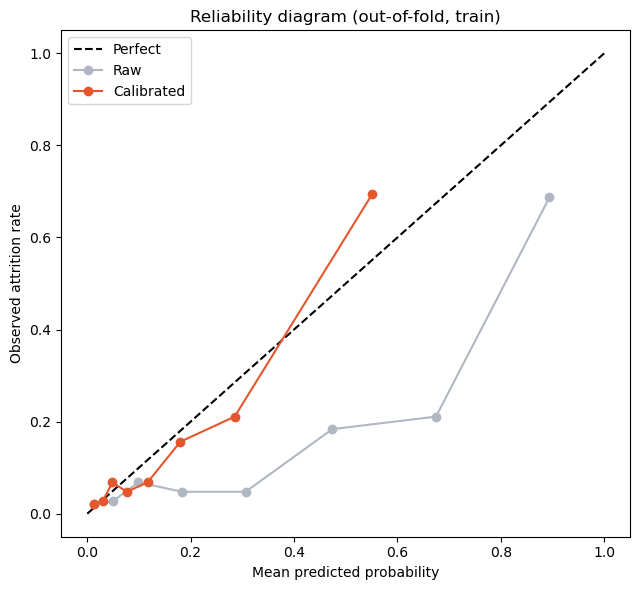

In [42]:
CV_THR = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE + 3)

def score_of(est, X_):
    """probability if available, else decision function"""
    return est.predict_proba(X_)[:, 1] if hasattr(est, "predict_proba") else est.decision_function(X_)

def ece_score(y_true, p, bins=10):
    edges = np.linspace(0, 1, bins + 1); idx = np.clip(np.digitize(p, edges) - 1, 0, bins - 1); e = 0
    for b in range(bins):
        m = idx == b
        if m.any(): e += m.mean() * abs(y_true[m].mean() - p[m].mean())
    return e

final_cal = CalibratedClassifierCV(clone(final_pipe), method="sigmoid", cv=5)

# out-of-fold predictions on TRAIN (calibrated and, when possible, raw)
oof_cal = cross_val_predict(final_cal, X_train, y_train, cv=CV_THR, method="predict_proba")[:, 1]
has_proba = hasattr(final_pipe, "predict_proba")
oof_raw = cross_val_predict(clone(final_pipe), X_train, y_train, cv=CV_THR, method="predict_proba")[:, 1] if has_proba else None

ytr = y_train.values
rows = [{"version": "calibrated (sigmoid)", "ROC-AUC": roc_auc_score(ytr, oof_cal), "PR-AUC": average_precision_score(ytr, oof_cal),
         "Brier": brier_score_loss(ytr, oof_cal), "ECE": ece_score(ytr, oof_cal), "mean predicted": oof_cal.mean()}]
if has_proba:
    rows.insert(0, {"version": "raw (class-weighted)", "ROC-AUC": roc_auc_score(ytr, oof_raw), "PR-AUC": average_precision_score(ytr, oof_raw),
                    "Brier": brier_score_loss(ytr, oof_raw), "ECE": ece_score(ytr, oof_raw), "mean predicted": oof_raw.mean()})
display(pd.DataFrame(rows))
print(f"True prevalence in train: {ytr.mean():.3f}  (a calibrated model's mean prediction should be close to this)")

fig, ax = plt.subplots(figsize=(6.5, 6))
ax.plot([0, 1], [0, 1], "k--", label="Perfect")
for lab, p, c in ([("Raw", oof_raw, "#b0b7c3")] if has_proba else []) + [("Calibrated", oof_cal, "#e4572e")]:
    fr, mp = calibration_curve(ytr, p, n_bins=8, strategy="quantile")
    ax.plot(mp, fr, "o-", label=lab, color=c)
ax.set_xlabel("Mean predicted probability"); ax.set_ylabel("Observed attrition rate"); ax.set_title("Reliability diagram (out-of-fold, train)"); ax.legend()
plt.tight_layout(); plt.show()

Max-F1 threshold = 0.37   |   Max-F2 (recall-weighted) threshold = 0.15


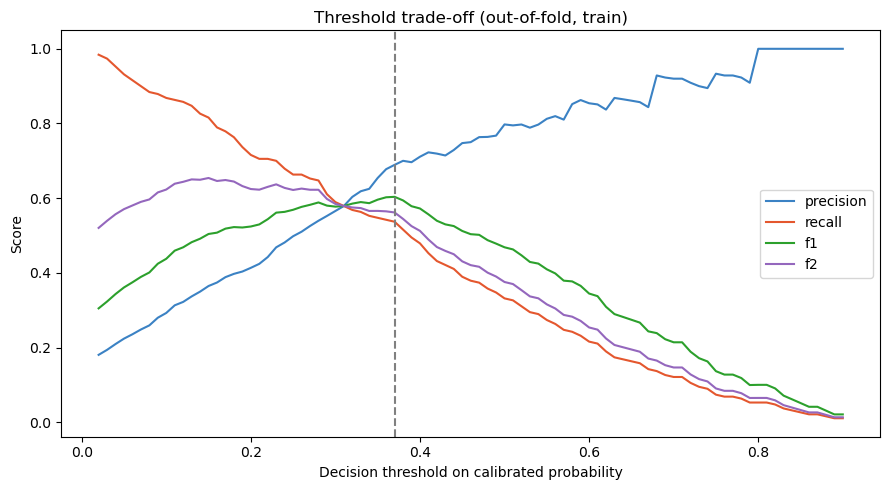

In [43]:
# ---- operating points chosen on OUT-OF-FOLD TRAIN predictions ----
grid = np.linspace(0.02, 0.90, 89)
def curve(y_true, p):
    out = []
    for t in grid:
        pred = (p >= t).astype(int)
        out.append({"thr": t, "precision": precision_score(y_true, pred, zero_division=0), "recall": recall_score(y_true, pred),
                    "f1": f1_score(y_true, pred), "f2": fbeta_score(y_true, pred, beta=2), "flagged": pred.mean()})
    return pd.DataFrame(out)
thr_tbl = curve(ytr, oof_cal)
THR_F1 = float(thr_tbl.loc[thr_tbl.f1.idxmax(), "thr"])
THR_F2 = float(thr_tbl.loc[thr_tbl.f2.idxmax(), "thr"])
print(f"Max-F1 threshold = {THR_F1:.2f}   |   Max-F2 (recall-weighted) threshold = {THR_F2:.2f}")

fig, ax = plt.subplots(figsize=(9, 5))
for c, col in [("precision", "#3b82c4"), ("recall", "#e4572e"), ("f1", "#2ca02c"), ("f2", "#9467bd")]:
    ax.plot(thr_tbl.thr, thr_tbl[c], label=c, color=col)
ax.axvline(THR_F1, ls="--", c="grey"); ax.set_xlabel("Decision threshold on calibrated probability"); ax.set_ylabel("Score")
ax.set_title("Threshold trade-off (out-of-fold, train)"); ax.legend(); plt.tight_layout(); plt.show()

---
# 14. Final, One-Time Evaluation on the Held-Out Test Set

Everything (features, hyper-parameters, calibration, thresholds) is now **frozen**. The model is fitted on the training set and scored on the 294 never-seen employees – once.

In [44]:
final_cal_fit = clone(final_cal).fit(X_train, y_train)
p_test = final_cal_fit.predict_proba(X_test)[:, 1]
yte = y_test.values

auc_t, ap_t = roc_auc_score(yte, p_test), average_precision_score(yte, p_test)
print(f"TEST  ROC-AUC = {auc_t:.4f}   PR-AUC = {ap_t:.4f}   Brier = {brier_score_loss(yte, p_test):.4f}   "
      f"LogLoss = {log_loss(yte, p_test):.4f}   ECE = {ece_score(yte, p_test):.4f}")

# ---- bootstrap confidence intervals ----
rng = np.random.default_rng(RANDOM_STATE)
B = 300 if QUICK_RUN else 2000
boots = {"ROC-AUC": [], "PR-AUC": []}
for _ in range(B):
    i = rng.integers(0, len(yte), len(yte))
    if yte[i].sum() == 0: continue
    boots["ROC-AUC"].append(roc_auc_score(yte[i], p_test[i])); boots["PR-AUC"].append(average_precision_score(yte[i], p_test[i]))
ci = {k: np.percentile(v, [2.5, 97.5]) for k, v in boots.items()}
print(f"95% bootstrap CI  ROC-AUC [{ci['ROC-AUC'][0]:.3f}, {ci['ROC-AUC'][1]:.3f}]   PR-AUC [{ci['PR-AUC'][0]:.3f}, {ci['PR-AUC'][1]:.3f}]")

# ---- consistency: CV vs nested CV vs test ----
cons = pd.DataFrame({"estimate": ["Fresh-fold CV (tuned)", "Nested CV (tune+fit)", "HELD-OUT TEST"],
                     "ROC-AUC": [fin.cv_roc_auc, nested_auc.mean(), auc_t]})
display(cons)
print(f"|Test − nested CV| = {abs(auc_t - nested_auc.mean()):.3f}  (within ~1–2 CV standard deviations ⇒ no sign of over-fitting to the validation folds)")

TEST  ROC-AUC = 0.8064   PR-AUC = 0.5258   Brier = 0.1053   LogLoss = 0.3494   ECE = 0.0333
95% bootstrap CI  ROC-AUC [0.731, 0.871]   PR-AUC [0.388, 0.663]


,estimate,ROC-AUC
0,Fresh-fold CV (tuned),0.841570
1,Nested CV (tune+fit),0.832681
2,HELD-OUT TEST,0.806443


|Test − nested CV| = 0.026  (within ~1–2 CV standard deviations ⇒ no sign of over-fitting to the validation folds)


|Test − nested CV| = 0.026  (within ~1–2 CV standard deviations ⇒ no sign of over-fitting to the validation folds)


,threshold,flagged %,TP,FP,FN,TN,precision,recall,F1,F2,balanced acc,MCC,accuracy
max-F1 point,0.37,10.544218,17.0,14.0,30.0,233.0,0.548387,0.361702,0.435897,0.388128,0.652511,0.363974,0.850340
max-F2 (recall-first) point,0.15,32.993197,34.0,63.0,13.0,184.0,0.350515,0.723404,0.472222,0.596491,0.734172,0.365042,0.741497


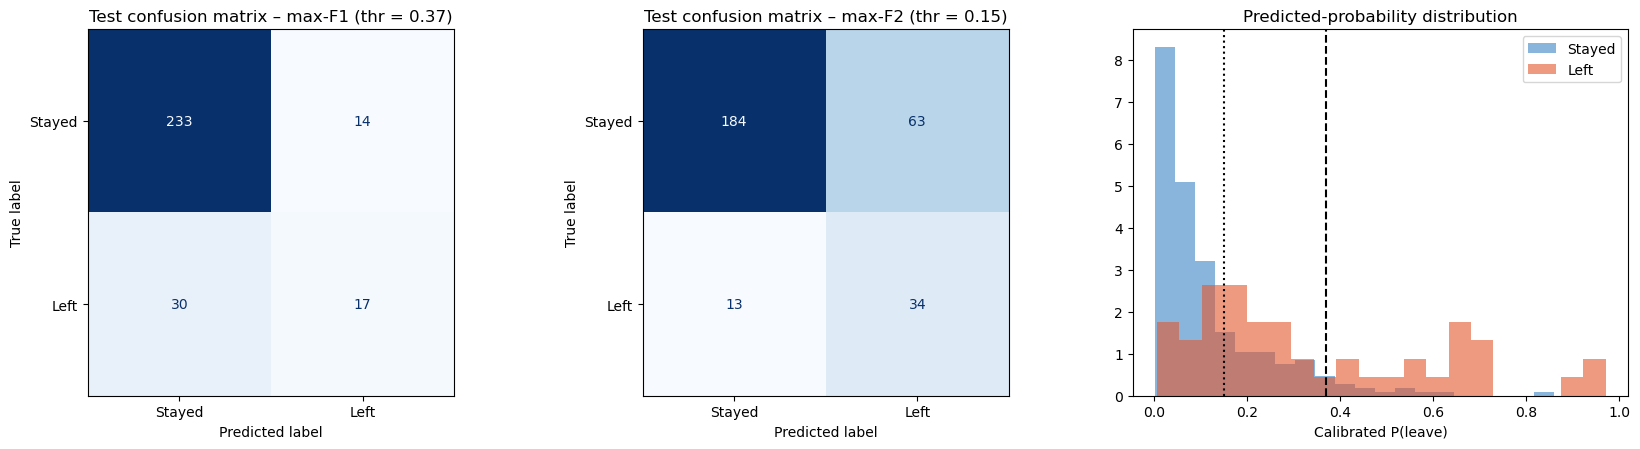

In [45]:
# ---- operating-point metrics on the TEST set ----
def op_metrics(y_true, p, thr):
    pred = (p >= thr).astype(int); tn, fp, fn, tp = confusion_matrix(y_true, pred).ravel()
    return {"threshold": thr, "flagged %": pred.mean() * 100, "TP": tp, "FP": fp, "FN": fn, "TN": tn,
            "precision": precision_score(y_true, pred, zero_division=0), "recall": recall_score(y_true, pred),
            "F1": f1_score(y_true, pred), "F2": fbeta_score(y_true, pred, beta=2), "balanced acc": balanced_accuracy_score(y_true, pred),
            "MCC": matthews_corrcoef(y_true, pred), "accuracy": (pred == y_true).mean()}

ops = pd.DataFrame({"max-F1 point": op_metrics(yte, p_test, THR_F1), "max-F2 (recall-first) point": op_metrics(yte, p_test, THR_F2)}).T
display(ops)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
for ax, (lab, thr) in zip(axes[:2], [("max-F1", THR_F1), ("max-F2", THR_F2)]):
    ConfusionMatrixDisplay(confusion_matrix(yte, (p_test >= thr).astype(int)), display_labels=["Stayed", "Left"]).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(f"Test confusion matrix – {lab} (thr = {thr:.2f})"); ax.grid(False)
for k, c in [(0, PALETTE[0]), (1, PALETTE[1])]:
    axes[2].hist(p_test[yte == k], bins=20, alpha=.6, color=c, label=["Stayed", "Left"][k], density=True)
axes[2].axvline(THR_F1, ls="--", c="k"); axes[2].axvline(THR_F2, ls=":", c="k")
axes[2].set_title("Predicted-probability distribution"); axes[2].set_xlabel("Calibrated P(leave)"); axes[2].legend()
plt.tight_layout(); plt.show()

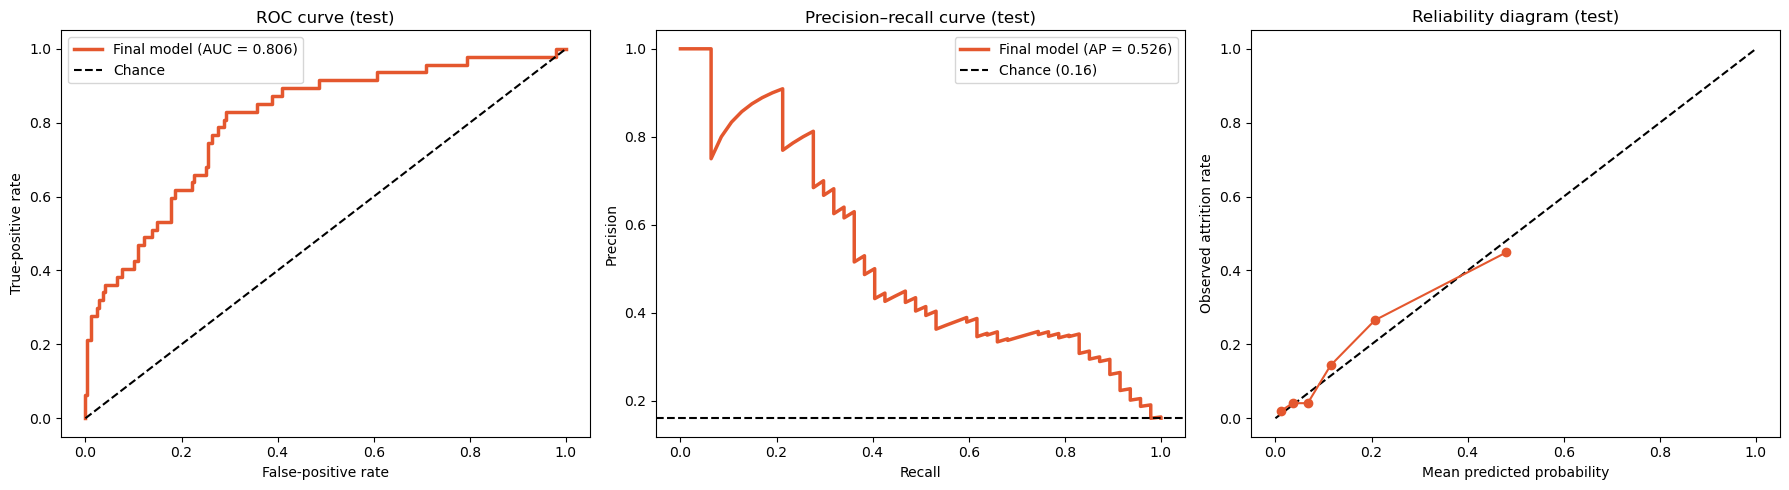

,employees,leavers,avg_pred,attrition_rate,lift,cum_leavers_captured_%
decile,,,,,,
1,30,17,0.580345,0.566667,3.544681,36.170213
2,29,7,0.304385,0.241379,1.509905,51.063830
3,29,7,0.202249,0.241379,1.509905,65.957447
4,30,8,0.140726,0.266667,1.668085,82.978723
5,29,3,0.102561,0.103448,0.647102,89.361702
6,29,1,0.074886,0.034483,0.215701,91.489362
7,30,1,0.052976,0.033333,0.208511,93.617021
8,29,1,0.035646,0.034483,0.215701,95.744681
9,29,1,0.020617,0.034483,0.215701,97.872340


Top 10% highest-risk employees contain 36% of all leavers; top 30% contain 66%.


In [46]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
# ROC
fpr, tpr, _ = roc_curve(yte, p_test)
axes[0].plot(fpr, tpr, c="#e4572e", lw=2.5, label=f"Final model (AUC = {auc_t:.3f})"); axes[0].plot([0, 1], [0, 1], "k--", label="Chance")
axes[0].set_xlabel("False-positive rate"); axes[0].set_ylabel("True-positive rate"); axes[0].set_title("ROC curve (test)"); axes[0].legend()
# PR
pr, rc, _ = precision_recall_curve(yte, p_test)
axes[1].plot(rc, pr, c="#e4572e", lw=2.5, label=f"Final model (AP = {ap_t:.3f})"); axes[1].axhline(yte.mean(), c="k", ls="--", label=f"Chance ({yte.mean():.2f})")
axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision"); axes[1].set_title("Precision–recall curve (test)"); axes[1].legend()
# Calibration
fr, mp = calibration_curve(yte, p_test, n_bins=6, strategy="quantile")
axes[2].plot([0, 1], [0, 1], "k--"); axes[2].plot(mp, fr, "o-", c="#e4572e"); axes[2].set_title("Reliability diagram (test)")
axes[2].set_xlabel("Mean predicted probability"); axes[2].set_ylabel("Observed attrition rate")
plt.tight_layout(); plt.show()

# ---- cumulative gains / lift by risk decile ----
d = pd.DataFrame({"p": p_test, "y": yte}).sort_values("p", ascending=False).reset_index(drop=True)
d["decile"] = pd.qcut(d.index, 10, labels=range(1, 11))
gl = d.groupby("decile", observed=True).agg(employees=("y", "size"), leavers=("y", "sum"), avg_pred=("p", "mean"))
gl["attrition_rate"] = gl.leavers / gl.employees
gl["lift"] = gl.attrition_rate / yte.mean()
gl["cum_leavers_captured_%"] = gl.leavers.cumsum() / gl.leavers.sum() * 100
display(gl)
print(f"Top 10% highest-risk employees contain {gl['cum_leavers_captured_%'].iloc[0]:.0f}% of all leavers; top 30% contain {gl['cum_leavers_captured_%'].iloc[2]:.0f}%.")

### 14.1 Side-by-side with pre-declared baselines (test set)
Only two baselines, fixed in advance – nothing here is used for model selection.

In [47]:
base_dummy = ImbPipeline([("fe", HRFeatureEngineer()), ("prep", make_preprocessor()), ("clf", DummyClassifier(strategy="prior"))]).fit(X_train, y_train)
base_lr = make_pipeline(get_models()["LogReg_L2"], "filter", engineer=False).fit(X_train, y_train)
cmp = pd.DataFrame({
    "Dummy": [roc_auc_score(yte, score_of(base_dummy, X_test)), average_precision_score(yte, score_of(base_dummy, X_test))],
    "Simple LR (raw)": [roc_auc_score(yte, score_of(base_lr, X_test)), average_precision_score(yte, score_of(base_lr, X_test))],
    f"FINAL {final_name}": [auc_t, ap_t]}, index=["ROC-AUC", "PR-AUC"]).T
display(cmp)

# ---- who do we miss? (error analysis) ----
pred_f1 = (p_test >= THR_F1).astype(int)
err = X_test.assign(y=yte, pred=pred_f1, p=p_test)
err["outcome"] = np.select([(err.y == 1) & (err.pred == 1), (err.y == 1) & (err.pred == 0), (err.y == 0) & (err.pred == 1)], ["TP", "FN (missed)", "FP"], "TN")
prof = err.groupby("outcome").agg(n=("y", "size"), mean_p=("p", "mean"), age=("Age", "median"), income=("MonthlyIncome", "median"),
                                  tenure=("YearsAtCompany", "median"), overtime=("OverTime", lambda s: (s == "Yes").mean()),
                                  single=("MaritalStatus", lambda s: (s == "Single").mean()), job_sat=("JobSatisfaction", "mean"))
display(prof)

,ROC-AUC,PR-AUC
Dummy,0.500000,0.159864
Simple LR (raw),0.791972,0.535892
FINAL LogReg_L2,0.806443,0.525850


,n,mean_p,age,income,tenure,overtime,single,job_sat
outcome,,,,,,,,
FN (missed),30,0.171425,36.0,3031.0,4.0,0.500000,0.400000,2.666667
FP,14,0.491525,33.0,3603.5,1.5,0.642857,0.714286,3.285714
TN,233,0.094514,36.0,5093.0,5.0,0.158798,0.266094,2.785408
TP,17,0.641118,31.0,3140.0,3.0,0.882353,0.764706,2.235294


---
# 15. Model Interpretation — *why* do people leave?

Three lenses: **permutation importance** (model-agnostic, measured on the test set in terms of AUC lost, on the final model), **SHAP / odds ratios** (direction + magnitude per feature and per employee) and **partial dependence** (shape of the effect).

> **Note on collinearity.** Income, job level, age and total experience move together (Section 6.5). Attributions to such features are unstable in the full-feature model, so SHAP and odds ratios are computed on an *interpretation twin*: the same algorithm and hyper-parameters on the VIF-pruned feature set, which we verify has the same predictive power.

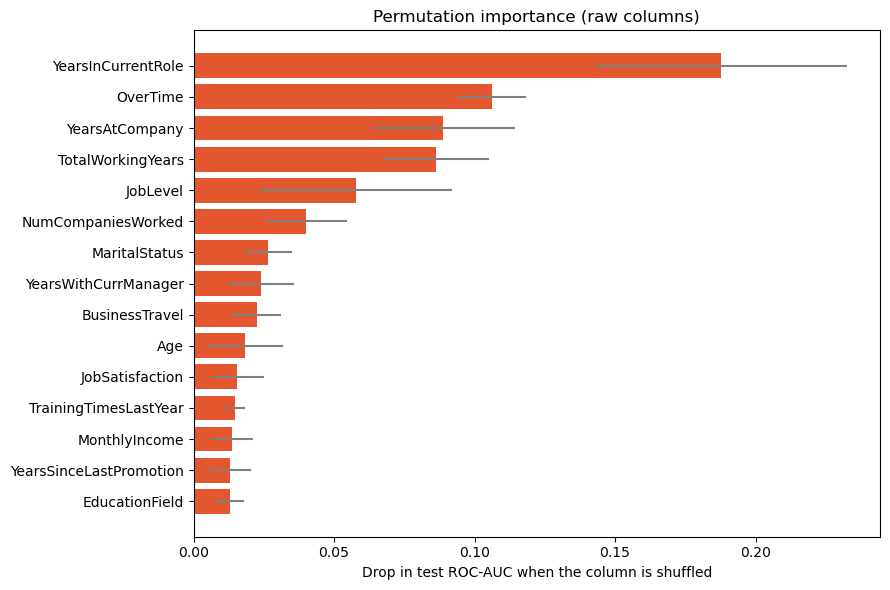

,feature,mean,std
0,YearsInCurrentRole,0.187716,0.044943
1,OverTime,0.106207,0.012153
2,YearsAtCompany,0.088907,0.025400
3,TotalWorkingYears,0.086292,0.018777
4,JobLevel,0.057924,0.034188
5,NumCompaniesWorked,0.040162,0.014490
6,MaritalStatus,0.026603,0.008481
7,YearsWithCurrManager,0.024002,0.011612
8,BusinessTravel,0.022424,0.008646
9,Age,0.018406,0.013418


In [48]:
final_fit = clone(final_pipe).fit(X_train, y_train)      # un-calibrated pipeline for interpretation

# ---- 15.1 permutation importance on RAW input columns (so derived features are credited to their sources) ----
pi = permutation_importance(final_fit, X_test, y_test, scoring="roc_auc", n_repeats=5 if QUICK_RUN else 25,
                            random_state=RANDOM_STATE, n_jobs=1)
imp = pd.DataFrame({"feature": X_test.columns, "mean": pi.importances_mean, "std": pi.importances_std}).sort_values("mean", ascending=False)
top = imp.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(top.feature, top["mean"], xerr=top["std"], color="#e4572e", ecolor="grey")
ax.set_xlabel("Drop in test ROC-AUC when the column is shuffled"); ax.set_title("Permutation importance (raw columns)")
plt.tight_layout(); plt.show()
display(imp.head(12).reset_index(drop=True))

Final model          : CV ROC-AUC = 0.8416
Interpretation model : CV ROC-AUC = 0.8401   (difference -0.0015 – essentially the same predictive content, far less collinearity)


Background dataset has 1176 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=1176 when initializing the masker.


Model sees 46 features after reduction: ['DailyRate', 'DistanceFromHome', 'HourlyRate', 'MonthlyRate', 'PercentSalaryHike', 'TrainingTimesLastYear', 'TenureRatio', 'JobHopIndex', 'PromotionStagnation', 'RoleStagnation', 'ManagerShare', 'IncomePerExpYear', 'CareerStartAge', 'CompaRatioLevel', 'SatisfactionStd', 'Education', 'EnvironmentSatisfaction', 'JobInvolvement', 'JobLevel', 'JobSatisfaction', 'PerformanceRating', 'RelationshipSatisfaction', 'StockOptionLevel', 'WorkLifeBalance', 'BusinessTravel_ord', 'SatisfactionMin', 'LowSatCount', 'OverTime_bin', 'Gender_bin', 'SingleOvertime', 'EarlyTenure', 'Department_Human_Resources', 'EducationField_Human_Resources', 'EducationField_Marketing', 'EducationField_Medical', 'EducationField_Other', 'EducationField_Technical_Degree', 'JobRole_Healthcare_Representative', 'JobRole_Laboratory_Technician', 'JobRole_Manager', 'JobRole_Manufacturing_Director', 'JobRole_Research_Director', 'JobRole_Research_Scientist', 'JobRole_Sales_Representative', '

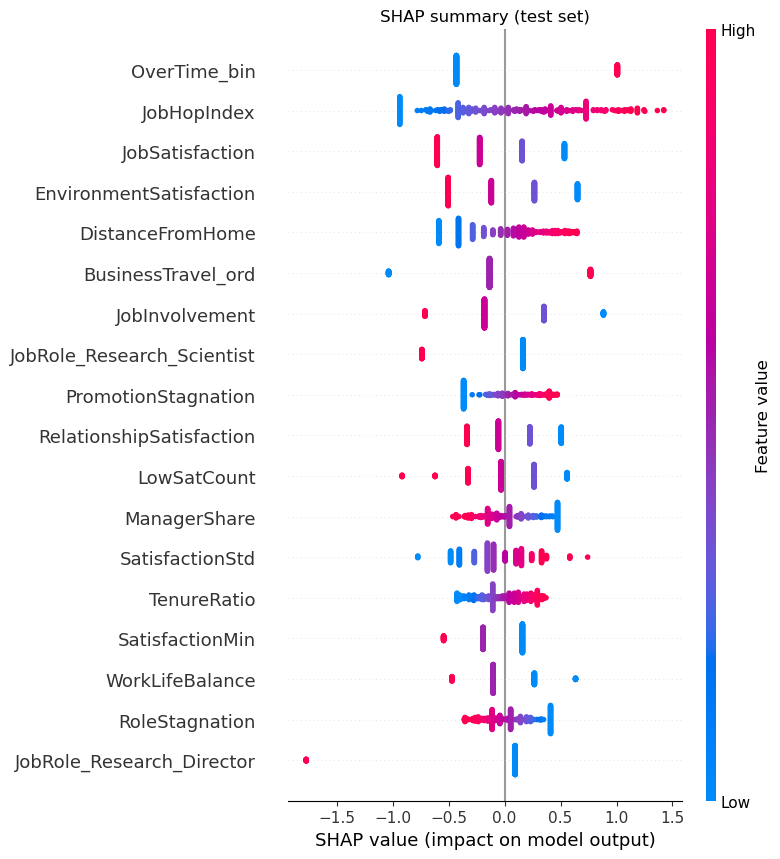

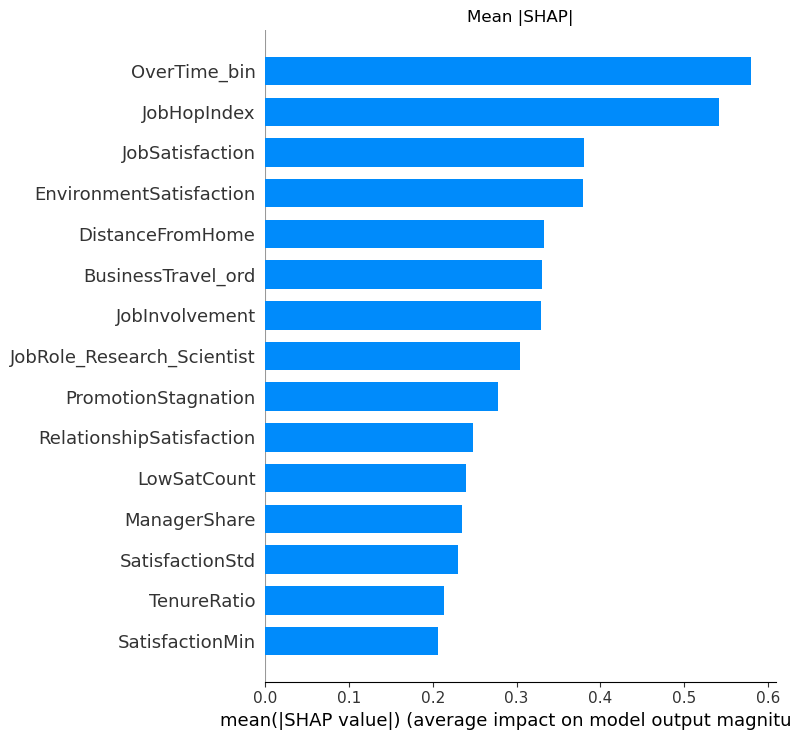

In [51]:
# ---- 15.2 Interpretation model (VIF-pruned twin) ----
# Coefficients/SHAP values of strongly collinear inputs (e.g. MonthlyIncome ~ JobLevel, r = 0.92) are unstable: credit gets split
# arbitrarily and signs can flip. For *explanation* we therefore use the same algorithm + hyper-parameters on the VIF-pruned feature set.
if final_fs == "full":
    interp_pipe = make_pipeline(final_pipe.named_steps["clf"], "filter")
else:
    interp_pipe = clone(final_pipe)
interp_cv = evaluate(clone(interp_pipe), "interpretation model", cv=CV_VALID)
print(f"Final model          : CV ROC-AUC = {fin.cv_roc_auc:.4f}")
print(f"Interpretation model : CV ROC-AUC = {interp_cv['cv_roc_auc']:.4f}   (difference {interp_cv['cv_roc_auc'] - fin.cv_roc_auc:+.4f} – essentially the same predictive content, far less collinearity)")
interp_fit = clone(interp_pipe).fit(X_train, y_train)

# ---- 15.3 SHAP ----
import shap
pre = interp_fit[:-1]
Xtr_t, Xte_t = pre.transform(X_train), pre.transform(X_test)
clf = interp_fit.named_steps["clf"]
print(f"Model sees {Xtr_t.shape[1]} features after reduction:", list(Xtr_t.columns))
try:
    explainer = shap.Explainer(clf, Xtr_t)
    sv = explainer(Xte_t)
    if sv.values.ndim == 3: sv = sv[..., 1]
    shap.summary_plot(sv.values, Xte_t, show=False, max_display=18); plt.title("SHAP summary (test set)"); plt.tight_layout(); plt.show()
    shap.summary_plot(sv.values, Xte_t, plot_type="bar", show=False, max_display=15); plt.title("Mean |SHAP|"); plt.tight_layout(); plt.show()
except Exception as ex:
    print("SHAP skipped:", repr(ex))
    sv = None

Test employee #911: predicted P(leave) = 0.97, actual = Left


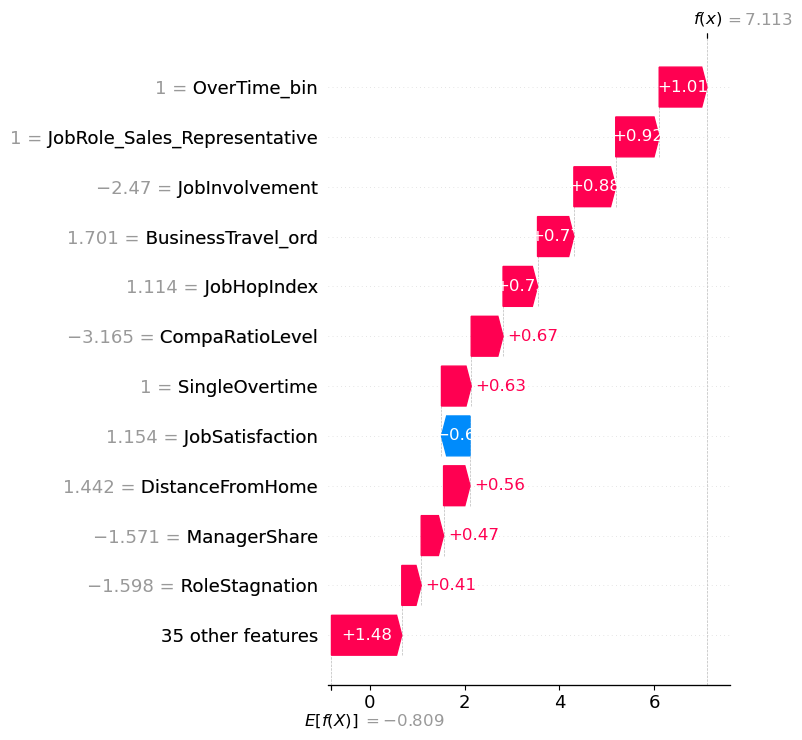

,coef,odds_ratio_per_SD
JobRole_Research_Director,-1.867997,0.154433
OverTime_bin,1.438441,4.214122
JobRole_Healthcare_Representative,-1.040330,0.353338
JobRole_Sales_Representative,0.935933,2.549592
JobRole_Research_Scientist,-0.902962,0.405367
JobRole_Manufacturing_Director,-0.748437,0.473105
EducationField_Human_Resources,0.737997,2.091741
SingleOvertime,0.674933,1.963902
EducationField_Technical_Degree,0.645568,1.907071
JobHopIndex,0.632498,1.882307


In [52]:
# ---- 15.4 local explanation for the highest-risk test employee ----
if sv is not None:
    i = int(np.argmax(p_test))
    print(f"Test employee #{X_test.index[i]}: predicted P(leave) = {p_test[i]:.2f}, actual = {'Left' if yte[i] else 'Stayed'}")
    try:
        shap.plots.waterfall(sv[i], max_display=12, show=False); plt.tight_layout(); plt.show()
    except Exception as ex:
        print("waterfall skipped:", repr(ex))

# ---- 15.5 linear models: odds ratios per +1 SD (interpretation model) ----
if hasattr(clf, "coef_"):
    coefs = pd.Series(clf.coef_.ravel(), index=Xtr_t.columns)
    orr = pd.DataFrame({"coef": coefs, "odds_ratio_per_SD": np.exp(coefs)}).sort_values("coef", key=abs, ascending=False)
    display(orr.head(15))

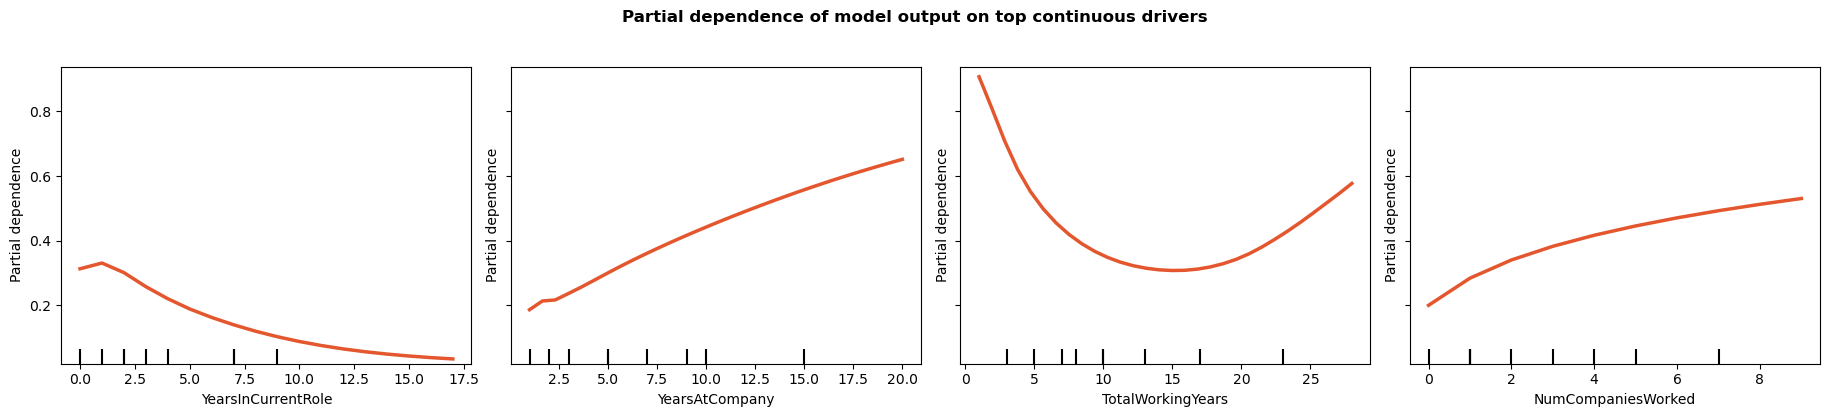

In [53]:
# ---- 15.6 partial dependence of the key continuous drivers (average effect on raw predicted probability) ----
from sklearn.inspection import PartialDependenceDisplay
pd_feats = [f for f in imp.feature if f in continuous_cols][:4]
try:
    fig, ax = plt.subplots(1, len(pd_feats), figsize=(4.6 * len(pd_feats), 4), sharey=True)
    X_pdp = X_train.copy(); X_pdp[pd_feats] = X_pdp[pd_feats].astype(float)      # float grid values need float columns
    PartialDependenceDisplay.from_estimator(final_fit, X_pdp, pd_feats, kind="average", ax=ax, grid_resolution=30,
                                            line_kw={"color": "#e4572e", "lw": 2.5})
    plt.suptitle("Partial dependence of model output on top continuous drivers", y=1.03, fontweight="bold"); plt.tight_layout(); plt.show()
except Exception as ex:
    print("PDP skipped:", repr(ex))

---
# 16. Business Impact (illustrative)

> **These cost parameters are assumptions, not facts from the dataset.** Replace them with your organisation's numbers; everything below recalculates.

For a flagged employee with annual salary $S_i=12\times\text{MonthlyIncome}_i$:
$$\mathbb E[\text{value}_i]=\begin{cases}
\;s\cdot c_{rep}\cdot S_i-c_{int}\cdot S_i & \text{if the employee would have left (true positive)}\\
\;-\,c_{int}\cdot S_i & \text{if not (false positive)}
\end{cases}$$
with replacement cost $c_{rep}$ (fraction of salary), intervention cost $c_{int}$ and intervention success rate $s$. With calibrated probabilities, flag an employee iff $\;\hat p_i\,s\,c_{rep}>c_{int}$, i.e. $\hat p_i>\dfrac{c_{int}}{s\,c_{rep}}$.

Theoretical break-even threshold  c_int/(s·c_rep) = 0.222;  empirical optimum on OOF train = 0.28


,strategy,employees flagged,net value on test
0,Do nothing,0,$0
1,Flag everyone,294,"$-539,771"
2,"Model, max-F1 (thr 0.37)",31,"$106,855"
3,"Model, cost-optimal (thr 0.28)",51,"$100,847"


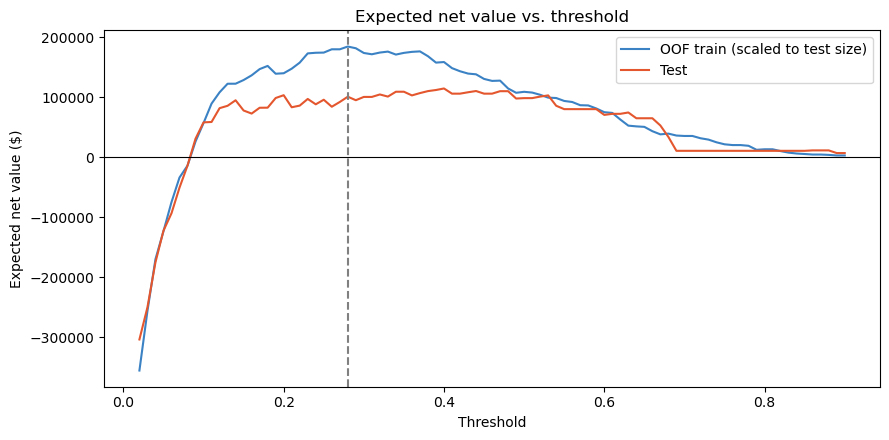

,employees,leavers,actual attrition rate,share of all leavers
tier,,,,
Low,192,11,5.7%,23.4%
Medium,51,14,27.5%,29.8%
High,51,22,43.1%,46.8%


In [54]:
REPLACEMENT_COST = 0.75       # c_rep : cost to replace a leaver, as a fraction of annual salary
INTERVENTION_COST = 0.05      # c_int : cost of a retention action per flagged employee, fraction of annual salary
INTERVENTION_SUCCESS = 0.30   # s     : share of would-be leavers retained when targeted

def net_value(y_true, p, salary, thr):
    flag = p >= thr
    tp = flag & (y_true == 1)
    return float((INTERVENTION_SUCCESS * REPLACEMENT_COST * salary[tp]).sum() - (INTERVENTION_COST * salary[flag]).sum())

sal_tr = 12 * X_train["MonthlyIncome"].values.astype(float)
sal_te = 12 * X_test["MonthlyIncome"].values.astype(float)
theory_thr = INTERVENTION_COST / (INTERVENTION_SUCCESS * REPLACEMENT_COST)

val_tr = np.array([net_value(ytr, oof_cal, sal_tr, t) for t in grid])
THR_COST = float(grid[val_tr.argmax()])               # chosen on OUT-OF-FOLD TRAIN predictions
print(f"Theoretical break-even threshold  c_int/(s·c_rep) = {theory_thr:.3f};  empirical optimum on OOF train = {THR_COST:.2f}")

val_te = np.array([net_value(yte, p_test, sal_te, t) for t in grid])
scen = pd.DataFrame({
    "strategy": ["Do nothing", "Flag everyone", f"Model, max-F1 (thr {THR_F1:.2f})", f"Model, cost-optimal (thr {THR_COST:.2f})"],
    "employees flagged": [0, len(yte), int((p_test >= THR_F1).sum()), int((p_test >= THR_COST).sum())],
    "net value on test": [0.0, net_value(yte, p_test, sal_te, 0.0), net_value(yte, p_test, sal_te, THR_F1), net_value(yte, p_test, sal_te, THR_COST)]})
display(scen.style.format({"net value on test": "${:,.0f}"}))

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(grid, val_tr / len(ytr) * len(yte), label="OOF train (scaled to test size)", color="#3b82c4")
ax.plot(grid, val_te, label="Test", color="#e4572e"); ax.axvline(THR_COST, ls="--", c="grey"); ax.axhline(0, c="k", lw=.8)
ax.set_xlabel("Threshold"); ax.set_ylabel("Expected net value ($)"); ax.set_title("Expected net value vs. threshold"); ax.legend()
plt.tight_layout(); plt.show()

# ---- risk tiers ----
tier = pd.cut(p_test, [-0.01, THR_COST / 2, THR_COST, 1.01], labels=["Low", "Medium", "High"])
tiers = pd.DataFrame({"tier": tier, "y": yte}).groupby("tier", observed=True).agg(employees=("y", "size"), leavers=("y", "sum"))
tiers["actual attrition rate"] = tiers.leavers / tiers.employees
tiers["share of all leavers"] = tiers.leavers / tiers.leavers.sum()
display(tiers.style.format({"actual attrition rate": "{:.1%}", "share of all leavers": "{:.1%}"}))

In [55]:
# ---- profile of the model's high-risk group vs. everyone else (test) ----
hr = X_test.assign(high_risk=(p_test >= THR_COST))
prof2 = hr.groupby("high_risk").agg(n=("Age", "size"), median_age=("Age", "median"), median_income=("MonthlyIncome", "median"),
                                    median_tenure=("YearsAtCompany", "median"), overtime_rate=("OverTime", lambda s: (s == "Yes").mean()),
                                    single_rate=("MaritalStatus", lambda s: (s == "Single").mean()),
                                    frequent_travel=("BusinessTravel", lambda s: (s == "Travel_Frequently").mean()),
                                    no_stock_options=("StockOptionLevel", lambda s: (s == 0).mean()),
                                    avg_job_satisfaction=("JobSatisfaction", "mean"), avg_work_life_balance=("WorkLifeBalance", "mean"))
display(prof2.T)

high_risk,False,True
n,243.000000,51.000000
median_age,36.000000,31.000000
median_income,5056.000000,3447.000000
median_tenure,6.000000,3.000000
overtime_rate,0.193416,0.568627
single_rate,0.255144,0.686275
frequent_travel,0.148148,0.313725
no_stock_options,0.362140,0.784314
avg_job_satisfaction,2.765432,2.764706
avg_work_life_balance,2.781893,2.745098


---
# 17. Recommendations & Solution Summary

In [56]:
display(Markdown(f"""
### Solution summary (all numbers computed above)
| Item | Result |
|---|---|
| Data | {len(df):,} employees, {df.shape[1]-1} usable features after cleaning, {df.Attrition.mean():.1%} attrition |
| Final model | **{final_name}** (tuned, class-weighted, sigmoid-calibrated), feature set `{final_fs}` |
| Cross-validated ROC-AUC (fresh folds) | {fin.cv_roc_auc:.3f} |
| Nested-CV ROC-AUC | {nested_auc.mean():.3f} ± {nested_auc.std():.3f} |
| **Held-out test ROC-AUC / PR-AUC** | **{auc_t:.3f}** (95% CI {ci['ROC-AUC'][0]:.3f}–{ci['ROC-AUC'][1]:.3f}) / **{ap_t:.3f}** (chance {yte.mean():.3f}) |
| Train–CV gap | {fin.auc_gap:+.3f} AUC → {verdict} |
| Label-permutation test | p = {pval:.4f} |
| Top-decile capture on test | {gl['cum_leavers_captured_%'].iloc[0]:.0f}% of leavers in the top 10% of risk scores; {gl['cum_leavers_captured_%'].iloc[2]:.0f}% in the top 30% |
| Operating point (max-F1, thr {THR_F1:.2f}) | precision {ops.iloc[0]['precision']:.2f}, recall {ops.iloc[0]['recall']:.2f} |
| Operating point (recall-first, thr {THR_F2:.2f}) | precision {ops.iloc[1]['precision']:.2f}, recall {ops.iloc[1]['recall']:.2f} |
"""))


### Solution summary (all numbers computed above)
| Item | Result |
|---|---|
| Data | 1,470 employees, 30 usable features after cleaning, 16.1% attrition |
| Final model | **LogReg_L2** (tuned, class-weighted, sigmoid-calibrated), feature set `full` |
| Cross-validated ROC-AUC (fresh folds) | 0.842 |
| Nested-CV ROC-AUC | 0.833 ± 0.029 |
| **Held-out test ROC-AUC / PR-AUC** | **0.806** (95% CI 0.731–0.871) / **0.526** (chance 0.160) |
| Train–CV gap | +0.064 AUC → GOOD FIT (small gap, strong validation score) |
| Label-permutation test | p = 0.0244 |
| Top-decile capture on test | 36% of leavers in the top 10% of risk scores; 66% in the top 30% |
| Operating point (max-F1, thr 0.37) | precision 0.55, recall 0.36 |
| Operating point (recall-first, thr 0.15) | precision 0.35, recall 0.72 |


### What the evidence says about *why* people leave
These come from the EDA (Section 6), permutation importance and the interpretation model (Section 15), and the profile of the model's high-risk group (Section 16).

1. **Overtime is the clearest single lever.** Attrition is roughly 2.5–3× higher among people working overtime, and it is the strongest categorical driver in the model (in the interpretation model, overtime multiplies the odds of leaving by roughly 4, holding the other features fixed).
2. **Risk is concentrated early in a role and early in tenure.** `YearsInCurrentRole` is the most important column by permutation importance, followed by `YearsAtCompany` and `TotalWorkingYears`. The high-risk group has a median tenure of about 3 years versus 6 for everyone else.
3. **Lower pay, junior level and no equity.** The high-risk group has a median income of about 3.5k versus 5.0k, and about 77% have no stock options versus 36%.
4. **Role and profile matter:** sales representatives, laboratory technicians and HR roles are above average; single employees and frequent travellers are over-represented in the high-risk group.
5. **Satisfaction survey items add real but secondary signal.** Job and environment satisfaction rank among the top contributors in the interpretation model's SHAP view, yet they are weak by permutation importance on the final model (they overlap with tenure and pay information), so treat them as supporting evidence rather than primary drivers.

### Recommendations
| Priority | Action | Why |
|---|---|---|
| 1 | **Review overtime load and travel** for teams with persistent overtime; cap or compensate it, starting with frequent travellers who also work overtime. | Strongest, most actionable driver. |
| 2 | **Strengthen onboarding and the first 2–3 years**: structured check-ins, mentoring, a visible career path and role rotation before people stall in one role. | Risk is highest early in tenure and in the current role. |
| 3 | **Fix pay competitiveness at junior levels**, using the compa-ratio (pay vs. peers at the same level) rather than absolute pay; extend stock or equity eligibility. | Leavers are paid less and rarely hold options. |
| 4 | **Targeted retention for sales representatives and lab technicians** (roles with the highest attrition). | Role-level rates far above average. |
| 5 | **Use the model as a prioritisation aid, not a verdict.** Review the top risk tiers with managers and pair every flag with a conversation. | Test precision/recall are moderate (see table above). |
| 6 | **Monitor and recalibrate** quarterly: track calibration, and re-fit when the workforce mix changes. | Drift is expected in any HR system. |

### Limitations — please read
* **Association, not causation.** The drivers above predict who leaves; they do not prove that changing them will keep people. Pilot interventions and measure the effect.
* **Test performance is lower than cross-validation** ({auc_t:.2f} vs. {fin.cv_roc_auc:.2f}). With only {int(yte.sum())} test leavers the interval is wide, so quote the range, not the point value.
* **Moderate recall at a precise threshold.** At the max-F1 point the model finds roughly a third of leavers; at the recall-first point it finds most of them but flags about a third of staff.
* **Snapshot, synthetic data.** There are no dates, so we cannot test forward in time, and some features may have been recorded at the time of leaving (Section 12.4). Real HR data is noisier; expect lower performance in production.
* **Cost analysis uses placeholder assumptions** (Section 16); replace them with your own numbers.
* **Saved model:** the deployment model is refit on all 1,470 rows; the test metrics above refer to the train-only model.

### Next steps
Collect time-stamped data (snapshot 6 months before the outcome), add exit-interview and engagement-survey history, and run a controlled retention pilot on the high-risk tier.

In [57]:
# ---- Save artifacts (model, metadata, scored test set) ----
os.makedirs("artifacts", exist_ok=True)
deploy_model = clone(final_cal).fit(X, y)          # refit on ALL labelled data for deployment (test metrics above refer to the train-only model)
joblib.dump({"model": deploy_model, "threshold_cost_optimal": THR_COST, "threshold_f1": THR_F1,
             "features_in": list(X.columns), "final_algorithm": final_name, "feature_set": final_fs},
            "artifacts/attrition_model.joblib")
scored = X_test.assign(P_leave=p_test, risk_tier=tier, actual_attrition=yte)
scored.sort_values("P_leave", ascending=False).to_csv("artifacts/test_set_risk_scores.csv")
print("Saved: artifacts/attrition_model.joblib  (loading it needs the custom classes in this notebook: HRFeatureEngineer, CorrelationFilter, VIFFilter, present)")
print("Saved: artifacts/test_set_risk_scores.csv")

Saved: artifacts/attrition_model.joblib  (loading it needs the custom classes in this notebook: HRFeatureEngineer, CorrelationFilter, VIFFilter, present)
Saved: artifacts/test_set_risk_scores.csv
